# 스테이블코인 발행사의 금리 플로어 운용 최적화

> 「디지털 자산의 제도화와 국내 기업의 대응 전략」 금융공학 파트  
> 이 파일은 `merge_notebooks.py`로 자동 생성된 통합 노트북입니다.  
> 원본 노트북은 `notebooks/01~07` 폴더에 있습니다.

**실행 순서**: 01 → 02 → 03 → 04 → 05 → 06 → 07 (앞 단계 결과물을 뒤 단계가 사용합니다)

---

# 1단계: 데이터 수집

*원본 파일: `notebooks/01_data_collection.ipynb`*

# 01. 데이터 수집

금리 플로어 분석에 필요한 데이터를 모으는 노트북이다.

| 섹션 | 내용 | 상태 |
|---|---|---|
| 1. 금리 데이터 | FRED: SOFR, 연방기금금리, 3개월 국채, 수익률곡선 | 완료 |
| **2. USDC 유통량** | DefiLlama: USDC, USDT 일별 유통량 | 완료 |
| **3. Circle 재무제표** | SEC EDGAR: 고정비 C, 배분율 s | 완료 |

**FRED**: 미국 세인트루이스 연방준비은행이 운영하는 무료 경제 데이터베이스. API 키 없이 CSV 파일로 받을 수 있다.
- **API 키**: 데이터 사이트가 "누가 요청했는지" 확인하려고 발급하는 비밀번호 같은 것. FRED CSV 다운로드에는 필요 없다.
- **CSV**: 쉼표(,)로 칸을 나눈 단순한 표 파일. 엑셀로도 열린다.

# 1. 금리 데이터

**순서**
1. 준비 → 2. 다운로드(원본 저장) → 3. 숫자로 바꾸기·결측치 → 4. 기간·결측치 표 → 5. 영업일 기준 한 표로 합치기
→ 6. SOFR와 DFF 비교 → 7. '기준금리' 열 만들기 → 8. 베이시스(SOFR − 3개월 국채) → 9. 그래프 → 10. 저장 → 11. 발견한 점 요약

## 1-1. 준비

### 라이브러리 불러오기
이 셀이 하는 일: 이번 섹션에서 쓸 도구(**라이브러리**: 다른 사람이 만들어 둔 코드 묶음)를 불러온다.
- `requests`: 인터넷에서 파일을 받는 도구
- `pandas`: 엑셀처럼 표 형태 데이터를 다루는 도구
- `matplotlib`: 그래프를 그리는 도구

In [1]:
import sys
from pathlib import Path   # 폴더·파일 경로를 다루는 도구

import requests
import pandas as pd
import matplotlib.pyplot as plt

### 폴더 경로 정하기
이 셀이 하는 일: 데이터와 그림을 저장할 폴더를 정하고, 없으면 만든다.
- `data/raw/fred/`: FRED에서 받은 **원본 그대로** (절대 수정하지 않는다)
- `data/processed/`: 정리한 데이터
- `output/figures/`: 발제안에 넣을 그림

In [2]:
# 노트북이 notebooks/ 폴더 안에 있으면 한 단계 위가 프로젝트 폴더
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DIR = PROJECT / "data" / "raw" / "fred"
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"

for folder in [RAW_DIR, PROC_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)   # 없으면 만들고, 있으면 그냥 넘어감

sys.path.append(str(PROJECT))   # src/ 폴더의 코드를 불러올 수 있게 프로젝트 폴더를 등록
print("프로젝트 폴더:", PROJECT)

프로젝트 폴더: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor


### 그래프 설정 (한글 폰트)
이 셀이 하는 일: 그래프에 한글이 깨지지 않도록 운영체제에 맞는 한글 폰트를 설정한다. (윈도우는 **맑은 고딕**)
- 설정 코드는 다른 노트북에서도 똑같이 쓰므로 `src/plot_style.py`에 함수로 만들어 두고 여기서는 불러서 쓰기만 한다.
- **함수**: 자주 하는 작업을 한 번 정의해 두고 이름으로 불러 쓰는 것.

In [3]:
from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE

font = setup_plot_style()
print("사용 폰트:", font)

사용 폰트: Malgun Gothic


## 1-2. 다운로드 (원본 저장)

### 받을 데이터 목록
이 셀이 하는 일: 받을 시리즈(데이터 하나하나)의 ID, 한국어 설명, 시작일을 적어 둔다.

| 시리즈 | 뜻 | 왜 필요한가 |
|---|---|---|
| **SOFR** | 담보부 익일물 금리. 미국 국채를 담보로 하루 동안 돈을 빌릴 때의 금리 | 플로어를 정산하는 **기준금리**. 2018년 4월부터만 있다 |
| **DFF** | 연방기금 실효금리. 은행끼리 하루 동안 빌려줄 때의 금리 | SOFR가 없는 2018년 이전을 **대신 채우는** 용도 |
| **DTB3** | 3개월 만기 국채(T-bill) 금리 | 준비금이 실제로 많이 들어가는 자산 → 실제 수익률 대용 |
| **DGS1MO ~ DGS10** | 만기 1개월~10년 국채 금리 | 만기별로 늘어놓으면 **수익률곡선** (시장이 예상하는 앞으로의 금리 경로) |

- **익일물(overnight)**: 오늘 빌려 내일 갚는 하루짜리 거래.

In [4]:
START = "2000-01-01"   # SOFR를 뺀 나머지는 2000년부터 받는다

FRED_SERIES = {
    # 시리즈 ID: (설명, 시작일)
    "SOFR":   ("담보부 익일물 금리",        None),    # None = 처음부터 전체
    "DFF":    ("연방기금 실효금리",         START),
    "DTB3":   ("3개월 국채 (할인율 기준)",   START),
    "DGS1MO": ("국채 1개월",               START),
    "DGS3MO": ("국채 3개월",               START),
    "DGS6MO": ("국채 6개월",               START),
    "DGS1":   ("국채 1년",                 START),
    "DGS2":   ("국채 2년",                 START),
    "DGS3":   ("국채 3년",                 START),
    "DGS5":   ("국채 5년",                 START),
    "DGS10":  ("국채 10년",                START),
}
print(f"받을 시리즈: {len(FRED_SERIES)}개")

받을 시리즈: 11개


### 다운로드 함수 만들기
이 셀이 하는 일: "시리즈 ID를 주면 FRED에서 CSV를 받아 `data/raw/fred/`에 **받은 그대로** 저장하는" 함수를 정의한다.
- 주소 끝의 `cosd=2000-01-01`은 "이 날짜부터 달라"는 뜻이다.
- 이미 받은 파일이 있으면 다시 받지 않는다. 최신 데이터로 새로 받고 싶으면 `refresh=True`로 부른다.

In [5]:
def download_fred(series_id, start=None, refresh=False):
    # FRED에서 시리즈 하나를 CSV로 받아 원본 그대로 저장한다
    path = RAW_DIR / f"{series_id}.csv"

    if path.exists() and not refresh:
        print(f"{series_id:7s} 이미 받은 파일이 있어 건너뜀")
        return path

    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    if start:
        url += f"&cosd={start}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()          # 다운로드에 실패하면 여기서 에러를 내고 멈춘다
    path.write_bytes(response.content)   # 받은 내용을 한 글자도 바꾸지 않고 저장
    print(f"{series_id:7s} 저장 완료 → {path.name}")
    return path

### 다운로드 실행
이 셀이 하는 일: 목록에 있는 11개 시리즈를 차례로 받는다. (처음엔 10~30초 걸린다.)

In [6]:
REFRESH = False   # 최신 데이터로 다시 받고 싶으면 True로 바꾸고 실행

for series_id, (desc, start) in FRED_SERIES.items():
    download_fred(series_id, start=start, refresh=REFRESH)

SOFR    이미 받은 파일이 있어 건너뜀


DFF     이미 받은 파일이 있어 건너뜀
DTB3    이미 받은 파일이 있어 건너뜀
DGS1MO  이미 받은 파일이 있어 건너뜀
DGS3MO  이미 받은 파일이 있어 건너뜀
DGS6MO  이미 받은 파일이 있어 건너뜀
DGS1    이미 받은 파일이 있어 건너뜀
DGS2    이미 받은 파일이 있어 건너뜀
DGS3    이미 받은 파일이 있어 건너뜀
DGS5    이미 받은 파일이 있어 건너뜀
DGS10   이미 받은 파일이 있어 건너뜀


## 1-3. 숫자로 바꾸기와 결측치

### 원본 파일 들여다보기
이 셀이 하는 일: 10년물(DGS10) 원본 파일의 첫 줄들과, 값이 비어 있는 줄을 그대로 출력해 본다.
- **결측치**: 값이 있어야 할 자리가 비어 있는 것.
- FRED는 휴일처럼 값이 없는 날을 예전엔 `.`(마침표)로, 지금은 **빈 칸**(`2025-12-25,` 처럼 쉼표 뒤가 비어 있음)으로 표시한다. 우리 파일이 어느 쪽인지 직접 확인해 보자.

In [7]:
lines = (RAW_DIR / "DGS10.csv").read_text().splitlines()

print("--- 처음 3줄 ---")
print("\n".join(lines[:3]))

print("--- 값이 비어 있는 줄 (최근 3개) ---")
empty_lines = [line for line in lines if line.endswith(",") or line.endswith(",.")]
print("\n".join(empty_lines[-3:]))

--- 처음 3줄 ---
observation_date,DGS10
2000-01-03,6.58
2000-01-04,6.49
--- 값이 비어 있는 줄 (최근 3개) ---
2026-07-03,
2026-09-07,
2026-10-12,


### 읽어서 숫자로 바꾸기
이 셀이 하는 일: 원본 CSV를 읽고, 금리 칸을 **숫자**로 바꾼다.
- 파일에서 읽은 값은 처음엔 '글자'일 수 있다. 글자 `"4.12"`는 계산이 안 되므로 숫자 `4.12`로 바꿔야 한다.
- `pd.to_numeric(..., errors="coerce")`: 숫자로 바꾸되, **숫자로 바꿀 수 없는 것(`.`이나 빈 칸)은 `NaN`으로** 바꾸라는 뜻.
- **NaN**(Not a Number): pandas에서 "값 없음"을 나타내는 표시. 평균 같은 계산을 할 때 자동으로 빠진다.

In [8]:
def read_fred(series_id):
    # 원본 CSV를 읽어 '날짜 → 금리(%)' 형태로 돌려준다
    df = pd.read_csv(RAW_DIR / f"{series_id}.csv",
                     dtype=str,            # 일단 전부 글자로 읽고
                     index_col=0)          # 첫 칸(날짜)을 행 이름(인덱스)으로
    df.index = pd.to_datetime(df.index)                         # 날짜 글자 → 날짜
    return pd.to_numeric(df[series_id], errors="coerce")       # 금리 글자 → 숫자 ('.'·빈 칸 → NaN)

raw = {series_id: read_fred(series_id) for series_id in FRED_SERIES}
raw["DGS10"].tail()

observation_date
2026-10-20    5.12
2026-10-21    5.13
2026-10-22    4.96
2026-10-23    5.00
2026-10-26    5.00
Name: DGS10, dtype: float64

### 결측치를 어떻게 처리할까?
이 노트북에서 정한 원칙은 세 가지다.

1. **개별 시리즈는 채우지 않는다.** 비어 있는 날은 `NaN` 그대로 둔다. 없는 값을 지어내면 나중에 변동성 같은 계산이 왜곡될 수 있다.
2. **표를 합칠 때는 영업일(월~금) 기준으로 맞춘다.** DFF는 주말에도 값이 있지만, 금요일 금리를 주말까지 그대로 적용한 것이라 주말 행을 빼도 정보가 사라지지 않는다.
3. **'기준금리' 열만은 빈 칸 없이 만든다.** 시뮬레이션에 쓸 열이라 빈 칸이 있으면 안 된다. 휴일에는 시장이 열리지 않아 새 금리가 정해지지 않으므로, **직전 영업일 값**을 그대로 쓴다. 이렇게 채운 날은 따로 표시해 둔다.

## 1-4. 기간·결측치 확인

### 시리즈별 요약표
이 셀이 하는 일: 시리즈마다 시작일, 종료일, 결측치 개수를 표로 보여준다.
- 결측치는 각 시리즈의 **첫 값 ~ 마지막 값 사이**에서만 센다.

In [9]:
def count_missing(s):
    s = s.loc[s.first_valid_index():s.last_valid_index()]   # 첫 값 ~ 마지막 값 사이만
    return int(s.isna().sum())

summary = pd.DataFrame({
    "설명":         {k: FRED_SERIES[k][0] for k in raw},
    "시작일":       {k: s.first_valid_index().date() for k, s in raw.items()},
    "종료일":       {k: s.last_valid_index().date() for k, s in raw.items()},
    "값 있는 날":    {k: int(s.notna().sum()) for k, s in raw.items()},
    "결측치 개수":   {k: count_missing(s) for k, s in raw.items()},
})
summary["결측 비율(%)"] = (summary["결측치 개수"] / (summary["값 있는 날"] + summary["결측치 개수"]) * 100).round(1)
summary

,설명,시작일,종료일,값 있는 날,결측치 개수,결측 비율(%)
SOFR,담보부 익일물 금리,2018-04-03,2026-10-26,2139,96,4.3
DFF,연방기금 실효금리,2000-01-01,2026-10-26,9796,0,0.0
DTB3,3개월 국채 (할인율 기준),2000-01-03,2026-10-26,6707,289,4.1
DGS1MO,국채 1개월,2001-07-31,2026-10-26,6311,274,4.2
DGS3MO,국채 3개월,2000-01-03,2026-10-26,6707,289,4.1
DGS6MO,국채 6개월,2000-01-03,2026-10-26,6707,289,4.1
DGS1,국채 1년,2000-01-03,2026-10-26,6707,289,4.1
DGS2,국채 2년,2000-01-03,2026-10-26,6707,289,4.1
DGS3,국채 3년,2000-01-03,2026-10-26,6707,289,4.1
DGS5,국채 5년,2000-01-03,2026-10-26,6707,289,4.1


### 결측치가 정말 휴일인지 확인
이 셀이 하는 일: 10년물(DGS10)과 SOFR의 최근 결측 날짜를 요일과 함께 뽑아 본다.
- 1월 1일, 독립기념일(7월 4일), 추수감사절(11월 넷째 목요일), 크리스마스 같은 미국 공휴일이 나오면 정상이다.
- 공휴일이 아닌 **성금요일**(부활절 직전 금요일)도 나올 수 있다. 미국 채권시장이 쉬는 날이라 SOFR가 공표되지 않는다.
- DFF는 결측치가 0개다. 휴일에도 직전 값을 그대로 적어 두기 때문이다.

In [10]:
for series_id in ["DGS10", "SOFR"]:
    s = raw[series_id]
    print(series_id, s[s.isna()].index[-8:].strftime("%Y-%m-%d(%a)").tolist())

DGS10 ['2026-01-01(Thu)', '2026-01-19(Mon)', '2026-02-16(Mon)', '2026-05-25(Mon)', '2026-06-19(Fri)', '2026-07-03(Fri)', '2026-09-07(Mon)', '2026-10-12(Mon)']
SOFR ['2026-01-19(Mon)', '2026-02-16(Mon)', '2026-04-03(Fri)', '2026-05-25(Mon)', '2026-06-19(Fri)', '2026-07-03(Fri)', '2026-09-07(Mon)', '2026-10-12(Mon)']


## 1-5. 영업일 기준 한 표로 합치기
이 셀이 하는 일: 2000년 1월 3일(첫 영업일)부터 가장 최근 날짜까지 **영업일(월~금) 달력**을 만들고, 11개 시리즈를 그 달력에 맞춰 한 표(`rates`)로 붙인다.
- 2018년 4월 전에는 SOFR가 없으므로 그 칸은 `NaN`이다. (다음 단계에서 DFF로 채운다)

In [11]:
last_date = max(s.last_valid_index() for s in raw.values())
bdays = pd.bdate_range("2000-01-01", last_date)   # 월~금 날짜 목록

rates = pd.DataFrame({k: s.reindex(bdays) for k, s in raw.items()})   # 달력에 맞춰 줄 세우기
rates.index.name = "date"

print("표 크기 (행, 열):", rates.shape)
rates.tail()

표 크기 (행, 열): (6996, 11)


,SOFR,DFF,DTB3,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS10
date,,,,,,,,,,,
2026-10-20,3.88,3.88,4.08,4.10,4.26,4.36,4.51,4.79,4.86,4.94,5.12
2026-10-21,3.88,3.88,4.07,4.09,4.25,4.35,4.52,4.81,4.89,4.95,5.13
2026-10-22,3.90,3.88,4.04,4.11,4.22,4.29,4.41,4.65,4.72,4.78,4.96
2026-10-23,3.92,3.88,4.04,4.11,4.22,4.30,4.44,4.69,4.75,4.82,5.00
2026-10-26,3.93,3.88,4.05,4.11,4.22,4.35,4.47,4.68,4.79,4.84,5.00


## 1-6. SOFR와 DFF는 얼마나 비슷한가? (이어 붙이기 전 확인)

2018년 이전을 DFF로 채우려면, 두 금리가 겹치는 기간(2018-04~)에 **거의 같게 움직였는지** 먼저 확인해야 한다. 차이가 크다면 DFF에 차이만큼 더하거나 빼서 맞춰야 한다.

### 차이 통계
이 셀이 하는 일: 두 값이 모두 있는 날만 골라 차이(SOFR − DFF)를 **bp** 단위로 계산하고 요약한다.
- **bp(베이시스 포인트)**: 0.01%p. 예: 3.00% → 3.25%는 25bp 상승.
- **중앙값**: 크기순으로 줄 세웠을 때 한가운데 값. 2019년 9월처럼 한 번 크게 튄 값에 덜 흔들린다.
- **표준편차**: 값들이 평균에서 보통 얼마나 떨어져 있는지.

In [12]:
overlap = rates[["SOFR", "DFF"]].dropna()            # 둘 다 값이 있는 날만
diff_bp = (overlap["SOFR"] - overlap["DFF"]) * 100   # %p → bp

pd.Series({
    "비교한 날 수":     len(diff_bp),
    "평균(bp)":        diff_bp.mean(),
    "중앙값(bp)":       diff_bp.median(),
    "표준편차(bp)":     diff_bp.std(),
    "하위 5%(bp)":      diff_bp.quantile(0.05),
    "상위 5%(bp)":      diff_bp.quantile(0.95),
    "최대(bp)":        diff_bp.max(),
    "최대인 날":        diff_bp.idxmax().date(),
}).to_frame("SOFR − DFF")

,SOFR − DFF
비교한 날 수,2139
평균(bp),-0.201964
중앙값(bp),-1.0
표준편차(bp),8.182688
하위 5%(bp),-6.0
상위 5%(bp),7.0
최대(bp),295.0
최대인 날,2019-09-17


### 차이 그래프
이 셀이 하는 일: 날짜별 차이(SOFR − DFF)를 그린다. 점선은 평균이다.
- 2019년 9월 17일 한 번 크게 튄 값 때문에 그래프가 납작해지지 않도록, 세로축을 ±40bp로 잘라서 그리고 잘린 값은 글씨로 적었다.

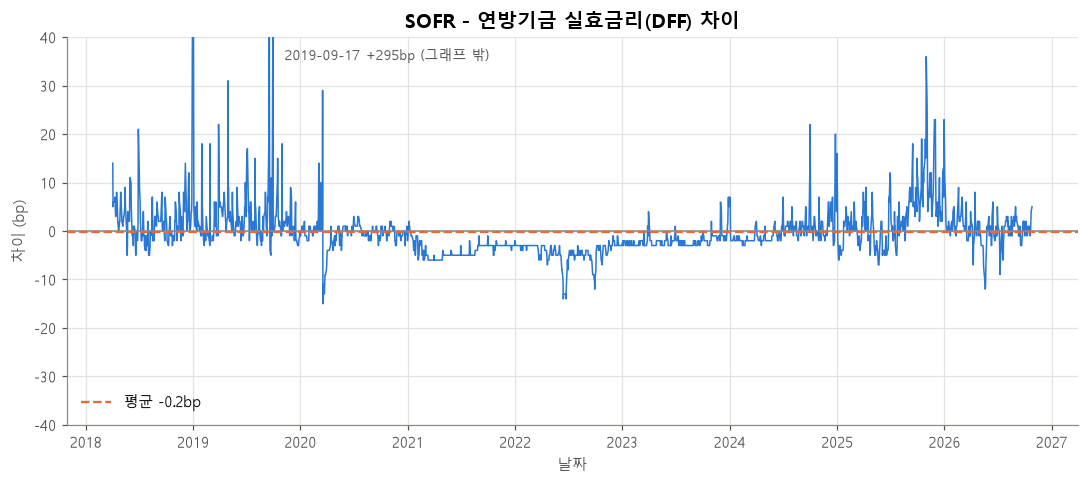

In [13]:
fig, ax = plt.subplots()
ax.plot(diff_bp.index, diff_bp.values, color=COLORS[0], linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axhline(diff_bp.mean(), color=COLORS[1], linestyle="--", linewidth=1.5,
           label=f"평균 {diff_bp.mean():.1f}bp")

ax.set_ylim(-40, 40)
spike_day = diff_bp.idxmax()
ax.annotate(f"{spike_day:%Y-%m-%d} +{diff_bp.max():.0f}bp (그래프 밖)",
            xy=(spike_day, 40), xytext=(10, -15), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_title("SOFR - 연방기금 실효금리(DFF) 차이")
ax.set_xlabel("날짜")
ax.set_ylabel("차이 (bp)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_sofr_minus_dff.png", dpi=200)
plt.show()

**해석**
- 평균 차이는 거의 0bp이고, 90%의 날이 약 ±7bp 안에 있다. 금리 수준(0~5%)에 비하면 아주 작다.
- 튀는 날은 주로 **월말·분기말**과 2019년 9월 단기자금시장 경색 때다. SOFR는 담보 거래라 국채 수급 영향을 더 받는다.
- 2021~22년에는 SOFR가 DFF보다 4~5bp 낮게, 2019·2025년에는 몇 bp 높게 유지된 시기가 있다. 시장에 돈이 많을 때는 SOFR가 더 낮아지는 경향이 있다.
- **결론: 차이를 보정하지 않고 DFF를 그대로 이어 붙인다.** 다만 2018년 이전의 DFF는 SOFR보다 **월말 출렁임이 작아** 변동성을 조금 덜 보여줄 수 있다는 점은 기억해 두자.

## 1-7. '기준금리' 열 만들기

### SOFR + DFF 이어 붙이기
이 셀이 하는 일: 아래 규칙으로 `base_rate`(기준금리) 열과, 그 값이 어디서 왔는지 적는 `base_source`(출처) 열을 만든다.

| 구간 | base_rate 값 | base_source |
|---|---|---|
| SOFR 시작일(2018-04-03) 이전 | DFF | `DFF 대체` |
| 그 이후 | SOFR | `SOFR` |
| 그 이후 중 SOFR 휴일 | 직전 영업일 SOFR | `휴일(직전값)` |

In [14]:
sofr_start = raw["SOFR"].first_valid_index()
before_sofr = rates.index < sofr_start                 # SOFR 시작 전이면 True

base_rate = rates["SOFR"].copy()
base_source = pd.Series("SOFR", index=rates.index)

base_rate[before_sofr] = rates.loc[before_sofr, "DFF"]   # 시작 전 구간은 DFF로
base_source[before_sofr] = "DFF 대체"

holiday = base_rate.isna()                    # 그래도 비어 있는 날 = SOFR 휴일
base_rate = base_rate.ffill()                 # ffill: 바로 위(직전 날짜) 값으로 채우기
base_source[holiday] = "휴일(직전값)"

rates["base_rate"] = base_rate
rates["base_source"] = base_source

print("SOFR 시작일:", sofr_start.date())
print("base_rate 빈 칸 수:", rates["base_rate"].isna().sum())
rates["base_source"].value_counts()

SOFR 시작일: 2018-04-03
base_rate 빈 칸 수: 0


base_source
DFF 대체     4761
SOFR       2139
휴일(직전값)      96
Name: count, dtype: int64

이 셀이 하는 일: SOFR 시작일 앞뒤 며칠을 보여줘서 DFF → SOFR로 자연스럽게 넘어가는지 확인한다.

In [15]:
rates.loc["2018-03-28":"2018-04-06", ["DFF", "SOFR", "base_rate", "base_source"]]

,DFF,SOFR,base_rate,base_source
date,,,,
2018-03-28,1.68,NaN,1.68,DFF 대체
2018-03-29,1.68,NaN,1.68,DFF 대체
2018-03-30,1.67,NaN,1.67,DFF 대체
2018-04-02,1.68,NaN,1.68,DFF 대체
2018-04-03,1.69,1.83,1.83,SOFR
2018-04-04,1.69,1.74,1.74,SOFR
2018-04-05,1.69,1.75,1.75,SOFR
2018-04-06,1.69,1.75,1.75,SOFR


## 1-8. 베이시스: SOFR − 3개월 국채

플로어는 **SOFR**로 정산되지만, 발행사가 실제로 버는 건 준비금에 담긴 **국채 수익률**이다. 둘이 따로 움직이면 헤지가 딱 맞지 않는데, 이를 **베이시스 위험**이라고 한다.

### 먼저 단위 맞추기: 할인율 → 수익률
DTB3는 **할인율**(discount rate)로 표시된다. SOFR와 단위가 달라서 그대로 빼면 안 된다.

- **할인율**: 이자를 **만기에 받을 돈(액면 100)** 으로 나눈 값. 예) 99에 사서 100 받으면 1 ÷ 100
- **수익률**(SOFR와 같은 방식): 이자를 **지금 낸 돈(99)** 으로 나눈 값. 1 ÷ 99
- 같은 거래라도 수익률이 할인율보다 조금 크다. 그래서 DTB3를 SOFR 방식으로 바꿔 준다.

$$\text{수익률} = \frac{360 \times d}{360 - 91 \times d}$$

($d$: 할인율(소수), 91: 3개월 국채의 만기 일수, 360: 미국 단기금리의 1년 일수 관행)
- 직관: 분모가 360보다 조금 작아서 할인율보다 살짝 커진다. 금리가 4%면 약 4bp 차이.

이 셀이 하는 일: DTB3를 수익률로 바꾼 `DTB3_MM` 열을 만들고, 바꾸기 전후 차이를 확인한다.

In [16]:
d = rates["DTB3"] / 100                                       # % → 소수 (4.0% → 0.04)
rates["DTB3_MM"] = 360 * d / (360 - 91 * d) * 100             # 다시 % 단위로

conv_gap_bp = (rates["DTB3_MM"] - rates["DTB3"]) * 100
print(f"할인율 → 수익률 변환으로 늘어난 폭: 최근 {conv_gap_bp.dropna().iloc[-1]:.1f}bp, 최대 {conv_gap_bp.max():.1f}bp")
rates[["DTB3", "DTB3_MM"]].dropna().tail()

할인율 → 수익률 변환으로 늘어난 폭: 최근 4.2bp, 최대 10.0bp


,DTB3,DTB3_MM
date,,
2026-10-20,4.08,4.122517
2026-10-21,4.07,4.112308
2026-10-22,4.04,4.081683
2026-10-23,4.04,4.081683
2026-10-26,4.05,4.091891


### 베이시스 그래프
이 셀이 하는 일: SOFR와 DTB3(수익률 환산)가 모두 있는 날만 골라 차이(bp)를 그리고, 연도별 평균을 표로 보여준다.
- 세로축은 ±130bp로 잘랐다. 2019년 9월 17일 값은 글씨로 적었다.

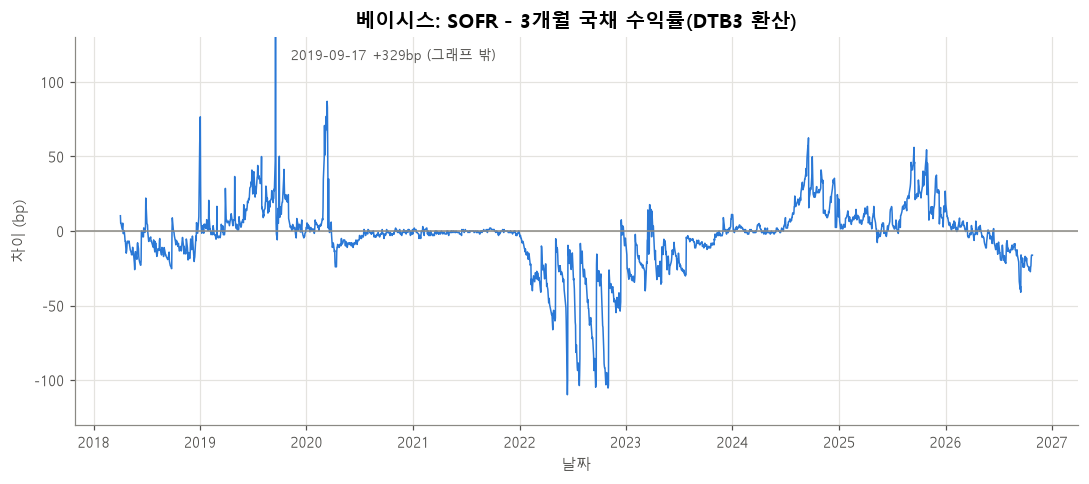

전체: 평균 -3.3bp, 표준편차 22.9bp


date,2018,2019,2020,2021,2022,2023,2024,2025,2026
연평균 베이시스(bp),-9.1,13.0,0.4,-0.6,-40.5,-13.1,11.5,13.6,-7.2


In [17]:
both = rates[["SOFR", "DTB3_MM"]].dropna()
basis_bp = (both["SOFR"] - both["DTB3_MM"]) * 100

fig, ax = plt.subplots()
ax.plot(basis_bp.index, basis_bp.values, color=COLORS[0], linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)

ax.set_ylim(-130, 130)
spike_day = basis_bp.idxmax()
ax.annotate(f"{spike_day:%Y-%m-%d} +{basis_bp.max():.0f}bp (그래프 밖)",
            xy=(spike_day, 130), xytext=(10, -15), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_title("베이시스: SOFR - 3개월 국채 수익률(DTB3 환산)")
ax.set_xlabel("날짜")
ax.set_ylabel("차이 (bp)")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_sofr_minus_tbill.png", dpi=200)
plt.show()

print(f"전체: 평균 {basis_bp.mean():.1f}bp, 표준편차 {basis_bp.std():.1f}bp")
basis_bp.groupby(basis_bp.index.year).mean().round(1).to_frame("연평균 베이시스(bp)").T

**이 차이가 의미하는 것** — 단위를 맞춘 뒤에도 남는 차이는 세 가지가 섞여 있다.

1. **만기 차이 → 금리 예상** (가장 크다)
   SOFR는 하루짜리, 3개월 국채는 3개월짜리라서, 앞으로 3개월 동안의 금리 예상이 국채에 먼저 반영된다.
   - 시장이 **인상**을 예상할 때(2022년) → 국채가 먼저 올라 차이가 **음(−)** (2022년 평균 약 −40bp)
   - 시장이 **인하**를 예상할 때(2019년, 2024~25년) → 국채가 먼저 내려 차이가 **양(+)**
2. **담보·수급 차이**: 월말·분기말이나 2019년 9월처럼 단기자금이 부족할 때 SOFR만 튄다. 하루 이틀 만에 돌아온다.
3. **국채 수급**: 국채 발행이 많거나 적을 때 국채 금리만 따로 움직인다.

**우리 연구에 주는 의미**
- 발행사가 SOFR 플로어를 사면, 정산은 SOFR로 받는데 수익은 국채로 번다. 금리 **인하가 예상되는** 시기에는 국채 수익이 SOFR보다 **먼저** 떨어지므로, 플로어 보상이 손실보다 늦게 들어올 수 있다.
- 장기 평균은 0bp 근처라 큰 방향성은 없지만, 표준편차가 20bp 넘게 출렁인다. 10단계(한계 점검)의 베이시스 위험 근거로 쓴다.

## 1-9. 그래프

### 기준금리 추이 (2000년~현재)
이 셀이 하는 일: `base_rate`를 2000년부터 그린다.
- 선 색: **주황 = DFF 대체 구간**, **파랑 = SOFR 구간**
- 회색 음영: 연준의 **금리 인하 사이클** (첫 인하 ~ 마지막 인하, 연준 발표일 기준)
- 빗금: **제로금리** 구간 (기준금리 0.25% 미만)

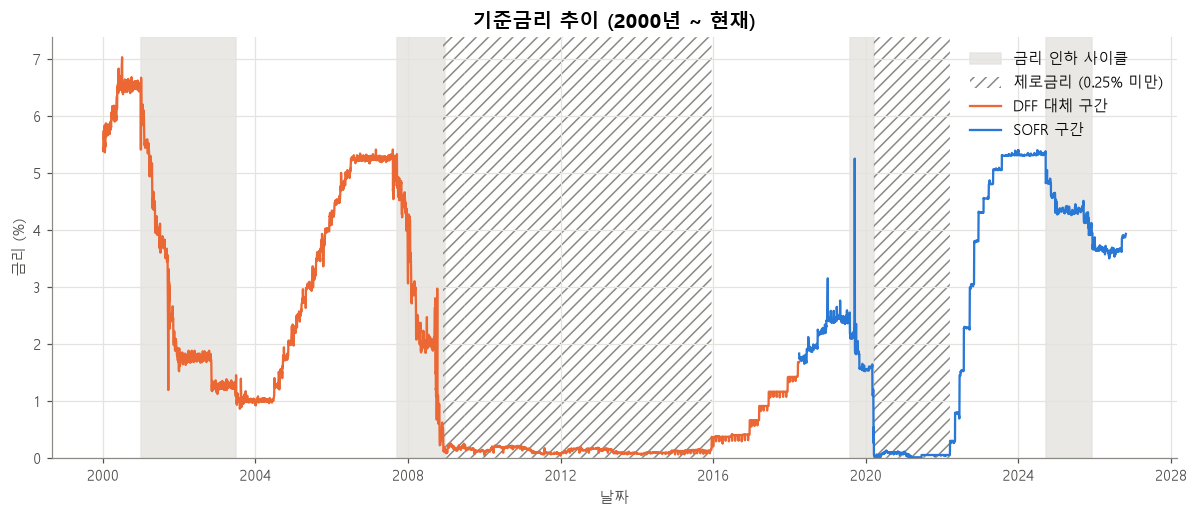

In [18]:
# 연준 금리 인하 사이클 (첫 인하일, 마지막 인하일)
CUT_CYCLES = [
    ("2001-01-03", "2003-06-25"),   # 닷컴 버블 붕괴
    ("2007-09-18", "2008-12-16"),   # 글로벌 금융위기
    ("2019-07-31", "2020-03-15"),   # 보험성 인하 → 코로나
    ("2024-09-18", "2025-12-10"),   # 인플레이션 진정 후 인하
]

base = rates["base_rate"]
is_dff = rates["base_source"] == "DFF 대체"

fig, ax = plt.subplots(figsize=(11, 4.8))

for i, (start, end) in enumerate(CUT_CYCLES):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.8,
               label="금리 인하 사이클" if i == 0 else None)

ax.fill_between(base.index, 0, base.max() * 1.05, where=base < 0.25,
                facecolor="none", edgecolor=MUTED, hatch="///", linewidth=0,
                label="제로금리 (0.25% 미만)")

ax.plot(base[is_dff].index, base[is_dff].values, color=COLORS[1], label="DFF 대체 구간")
ax.plot(base[~is_dff].index, base[~is_dff].values, color=COLORS[0], label="SOFR 구간")

ax.set_ylim(0, base.max() * 1.05)
ax.set_title("기준금리 추이 (2000년 ~ 현재)")
ax.set_xlabel("날짜")
ax.set_ylabel("금리 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_base_rate_2000.png", dpi=200)
plt.show()

**읽는 법**
- 2000년 이후 인하 사이클은 4번이고, 그중 두 번(2008년, 2020년)은 **제로금리**까지 내려갔다. 제로금리 기간을 합치면 약 9년이다.
- 발행사 입장에서 제로금리는 준비금 수익이 사실상 0이 되는 **최악의 시나리오**다. 플로어가 막아야 하는 상황이 바로 이것이다.
- 인하는 한번 시작하면 1~2년 동안 수백 bp가 빠르게 내려가지만, 인상은 천천히 올라간다. 금리 모형이 이 비대칭을 얼마나 잡는지 2단계에서 확인해야 한다.

### 최신 수익률곡선
이 셀이 하는 일: 8개 만기 금리가 모두 있는 가장 최근 날짜의 수익률곡선을 그린다.
- 오른쪽으로 **올라가면**(장기 > 단기) 정상 모양, **내려가면** 역전(시장이 앞으로 금리 인하를 예상)이다.
- 가로축 간격은 실제 기간 비율이 아니라 보기 편하게 같은 간격으로 놓았다.

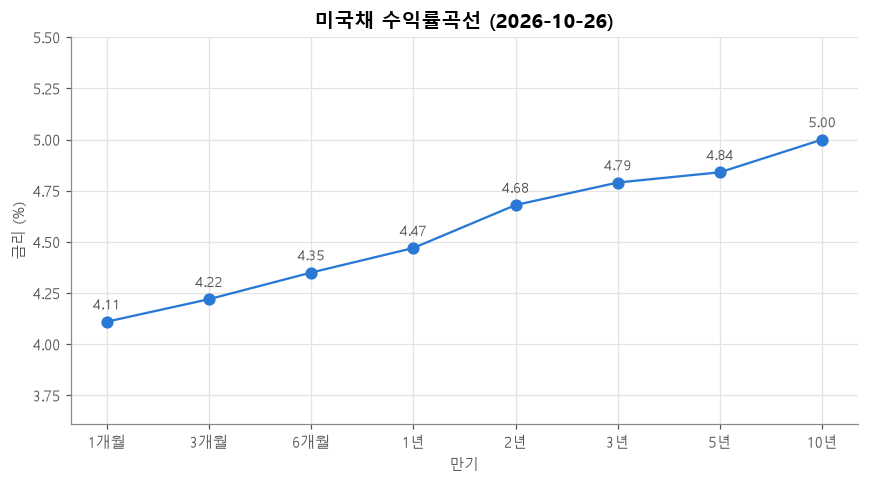

10년 - 3개월 = 78bp, 2년 - 3개월 = 46bp


In [19]:
curve_ids = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
curve_labels = ["1개월", "3개월", "6개월", "1년", "2년", "3년", "5년", "10년"]

latest = rates[curve_ids].dropna().iloc[-1]   # 8개가 모두 있는 마지막 날

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve_labels, latest.values, color=COLORS[0], marker="o", markersize=7)
for x, y in zip(curve_labels, latest.values):
    ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT_SUB)

ax.set_ylim(latest.min() - 0.5, latest.max() + 0.5)
ax.set_title(f"미국채 수익률곡선 ({latest.name:%Y-%m-%d})")
ax.set_xlabel("만기")
ax.set_ylabel("금리 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_yield_curve_latest.png", dpi=200)
plt.show()

print(f"10년 - 3개월 = {(latest['DGS10'] - latest['DGS3MO']) * 100:.0f}bp, "
      f"2년 - 3개월 = {(latest['DGS2'] - latest['DGS3MO']) * 100:.0f}bp")

## 1-10. 저장
이 셀이 하는 일: 정리한 표를 `data/processed/rates.parquet`로 저장하고, 다시 읽어서 제대로 저장됐는지 확인한다.
- **parquet**: CSV보다 빠르고 작은 표 저장 형식. 날짜·숫자 형식이 그대로 유지돼서 다시 읽을 때 변환할 필요가 없다.

| 열 | 내용 |
|---|---|
| `SOFR`, `DFF`, `DTB3`, `DGS1MO` ~ `DGS10` | 원본 값 (결측은 NaN 그대로) |
| `DTB3_MM` | DTB3를 SOFR와 같은 수익률 방식으로 바꾼 값 |
| `base_rate` | 기준금리 (빈 칸 없음) |
| `base_source` | 기준금리 출처: `SOFR` / `DFF 대체` / `휴일(직전값)` |

In [20]:
out_path = PROC_DIR / "rates.parquet"
rates.to_parquet(out_path)

check = pd.read_parquet(out_path)
print("저장 완료:", out_path)
print("행, 열:", check.shape, "| 기간:", check.index[0].date(), "~", check.index[-1].date())
check.dtypes

저장 완료: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\data\processed\rates.parquet
행, 열: (6996, 14) | 기간: 2000-01-03 ~ 2026-10-26


SOFR           float64
DFF            float64
DTB3           float64
DGS1MO         float64
DGS3MO         float64
DGS6MO         float64
DGS1           float64
DGS2           float64
DGS3           float64
DGS5           float64
DGS10          float64
base_rate      float64
base_source        str
DTB3_MM        float64
dtype: object

## 1-11. 발견한 점 요약 (2026-10-26 데이터 기준)

**데이터 상태**
- 11개 시리즈 모두 정상으로 받았다. SOFR는 2018-04-03~2026-10-26, 나머지는 2000년~2026-10-26 (2026-10-28에 다시 받음). 국채·DFF는 SOFR보다 공표가 늦어 받는 시점에 따라 하루 정도 뒤처질 수 있다.
- 결측치는 시리즈마다 약 4%이고, 모두 **채권시장 휴장일**(미국 공휴일, 성금요일 등)이다. 데이터 오류는 아니다.
- DGS1MO(1개월물)는 2001-07-31부터만 있다. 수익률곡선 전체(8개 만기)를 쓰는 분석은 2001년 8월부터 가능하다.
- 현재 FRED 파일은 결측을 `.`이 아니라 **빈 칸**으로 표시한다. 두 경우 모두 `NaN`으로 처리되게 해 두었다.

**이상값**
- **2019-09-17 SOFR 급등** (하루 +282bp, 5.25%): 단기자금시장 경색이라는 실제 사건이다. 지우지 않고 남겨 두지만, 금리 모형의 변동성을 추정할 때 이 하루가 결과를 크게 흔들 수 있다. 2단계에서 포함/제외를 비교해야 한다.
- 월말·분기말에 SOFR가 몇~수십 bp 튀는 패턴이 반복된다.

**주의할 점**
- **SOFR ≈ DFF**: 겹치는 기간 평균 차이 약 0bp, 90%가 ±7bp 안 → 보정 없이 이어 붙였다. 단, 2018년 이전 구간(DFF)은 SOFR보다 월말 출렁임이 작다.
- **DTB3는 할인율**이라 수익률보다 최대 10bp 정도 낮게 나온다. 비교할 때는 `DTB3_MM`(환산값)을 쓴다.
- **베이시스**(SOFR − 국채): 평균은 0 근처지만 표준편차가 20bp가 넘고, 금리 예상 방향에 따라 수십 bp씩 한쪽으로 쏠린다(2022년 평균 약 −40bp). 플로어 정산(SOFR)과 실제 수익(국채)이 어긋나는 위험이다.
- **최근 금리 방향 전환**: 2024-09~2025-12 인하 사이클 이후, 데이터상 **2026-09-17에 +25bp 인상**이 있었다. 시뮬레이션 시작점(최신 날짜)의 금리 수준과 수익률곡선 모양이 결과에 직접 영향을 주므로, 2단계에서 최신 곡선을 기준으로 삼아야 한다.
- 2000년 이후 제로금리 기간이 약 9년이다. 모형 추정 기간(2000년~ 또는 2008년~)에 따라 "금리가 0 근처에 머물 확률"이 크게 달라질 수 있다.

# 2. USDC 유통량과 통제 변수

**순서**
1. API 구조 확인 → 2. 다운로드(원본 저장) → 3. 읽어서 표로 바꾸기 → 4. 기간·결측치 → 5. 급격한 변화 확인
→ 6. 이벤트 열 3개 → 7. 통제 변수: 비트코인 가격 → 8. 금리와 합치기 → 9. USDC = 시장 × 점유율 분해
→ 10. 주간·월간 → 11. 그래프 → 12. 저장 → 13. 국면별 정리

**DefiLlama**: 블록체인 위의 자산 규모를 모아서 무료로 공개하는 사이트. 스테이블코인별로 각 블록체인에 얼마나 발행돼 있는지 매일 집계한다.
- **유통량**(circulating supply): 지금 시장에 풀려 있는 코인 개수. USDC 1개 = 1달러 준비금이므로, **유통량 ≈ 준비금 규모 R** 이다.

## 2-1. API 구조 확인

**API**: 프로그램이 다른 서비스에 데이터를 요청하는 창구. 정해진 주소로 요청하면 데이터를 **JSON**으로 돌려준다.
- **JSON**: `{"이름": 값}` 모양으로 데이터를 담는 글자 형식. 파이썬의 딕셔너리(`{}`)·리스트(`[]`)와 거의 같다.

DefiLlama 스테이블코인 API에서 쓸 만한 주소는 이렇다. (API 키 필요 없음)

| 주소 | 돌려주는 것 | 이번에 쓰나 |
|---|---|---|
| `https://stablecoins.llama.fi/stablecoins` | 모든 스테이블코인 목록과 **ID**, 현재 유통량 | ID 확인용 |
| `https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=<ID>` | 그 코인의 **일별 유통량** (모든 체인 합계) | **사용** (USDC, USDT, UST) |
| `https://stablecoins.llama.fi/stablecoincharts/all` (ID 없이) | **모든 스테이블코인 합계**의 일별 유통량 | **사용** (전체 시장) |
| `https://stablecoins.llama.fi/stablecoin/<ID>` | 체인(이더리움, 솔라나 등)별 상세 이력 | 사용 안 함 (너무 상세함) |

### 코인 목록에서 ID 확인
이 셀이 하는 일: 스테이블코인 목록을 받아 USDT, USDC, 그리고 2022년에 붕괴한 테라 UST(지금 이름 USTC)의 ID를 확인한다.

In [21]:
import json   # JSON 글자 ↔ 파이썬 데이터 변환 도구

LLAMA = "https://stablecoins.llama.fi"

coin_list = requests.get(f"{LLAMA}/stablecoins", timeout=60).json()
print("최상위 키:", list(coin_list.keys()))

for coin in coin_list["peggedAssets"]:
    if coin["symbol"] in ["USDT", "USDC", "USTC"]:
        now = coin["circulating"].get("peggedUSD", 0) / 1e9
        print(f"{coin['symbol']}: ID={coin['id']}, 이름={coin['name']}, 현재 유통량={now:,.1f}bn 달러")

최상위 키: ['peggedAssets', 'chains']
USDT: ID=1, 이름=Tether, 현재 유통량=180.3bn 달러
USDC: ID=2, 이름=USD Coin, 현재 유통량=71.5bn 달러
USTC: ID=3, 이름=TerraClassicUSD, 현재 유통량=0.0bn 달러


### 일별 데이터의 모양 확인
이 셀이 하는 일: USDC(ID=2)의 일별 데이터를 받아서, 맨 처음과 맨 마지막 항목을 그대로 출력해 본다.

In [22]:
sample = requests.get(f"{LLAMA}/stablecoincharts/all?stablecoin=2", timeout=60).json()

print("자료형:", type(sample).__name__, "| 항목 수:", len(sample))
print("--- 첫 항목 ---")
print(json.dumps(sample[0], indent=1))
print("--- 마지막 항목 ---")
print(json.dumps(sample[-1], indent=1))

자료형: list | 항목 수: 2972
--- 첫 항목 ---
{
 "date": "1536624000",
 "totalCirculating": {
  "peggedUSD": 2
 },
 "totalCirculatingUSD": {
  "peggedUSD": 2
 }
}
--- 마지막 항목 ---
{
 "date": "1793318400",
 "totalCirculating": {
  "peggedUSD": 71479873890.58
 },
 "totalUnreleased": {
  "peggedUSD": 1105247809.46
 },
 "totalCirculatingUSD": {
  "peggedUSD": 71441245833.01
 },
 "totalMintedUSD": {
  "peggedUSD": 0
 },
 "totalBridgedToUSD": {
  "peggedUSD": 0
 }
}


**응답 구조**: 하루에 항목 하나씩 들어 있는 **리스트**다. 각 항목의 필드(칸)는 이렇다.

| 필드 | 뜻 | 사용 |
|---|---|---|
| `date` | 날짜. **유닉스 시간**(1970-01-01부터 흐른 초)으로 적혀 있다. 예: `1793059200` → 2026-10-26 | **사용** (날짜로 변환) |
| `totalCirculating.peggedUSD` | 유통 중인 **코인 개수** (1개 = 1달러로 계산) | **사용** |
| `totalCirculatingUSD.peggedUSD` | 코인 개수 × **그날 시장 가격** | 비교용으로만 |
| `totalUnreleased` | 발행은 됐지만 아직 시장에 안 풀린 물량 | 사용 안 함 |
| `totalMintedUSD`, `totalBridgedToUSD` | 체인 간 이동 집계용 값 | 사용 안 함 |

- 전체 합계(ID 없이)에는 `peggedEUR`, `peggedJPY`처럼 다른 통화에 고정된 코인도 따로 들어 있다. 우리는 **달러 스테이블코인**(`peggedUSD`)만 쓴다.

**왜 `totalCirculating`(개수)을 쓰나?** 발행사가 준비금을 쥐고 이자를 버는 기준은 **코인 개수**다. 시장 가격이 잠깐 0.88달러로 떨어져도(디페깅) 발행사가 돌려줘야 할 돈은 개수 × 1달러다.
- **디페깅**(de-peg): 1달러에 고정돼야 할 코인 가격이 1달러에서 벗어나는 것.

## 2-2. 다운로드 (원본 저장)

### 다운로드 함수
이 셀이 하는 일: 이름을 주면 일별 데이터를 받아 `data/raw/defillama/<이름>.json`에 **받은 그대로** 저장하는 함수를 만든다.
- `ALL`은 ID 없이 받는 **전체 스테이블코인 합계**다.
- `USTC`(테라 UST)는 전체 합계에서 빼 주려고 받는다. 이유는 2-4에서 설명한다.
- 원본은 기간을 자르지 않고 전체를 저장한다.

In [23]:
LLAMA_DIR = PROJECT / "data" / "raw" / "defillama"
LLAMA_DIR.mkdir(parents=True, exist_ok=True)

STABLECOINS = {"USDC": 2, "USDT": 1, "USTC": 3, "ALL": None}   # 이름: DefiLlama ID (None = 전체 합계)


def download_llama(name, refresh=False):
    # DefiLlama에서 일별 유통량을 받아 원본 그대로 저장한다
    path = LLAMA_DIR / f"{name}.json"

    if path.exists() and not refresh:
        print(f"{name}: 이미 받은 파일이 있어 건너뜀")
        return path

    url = f"{LLAMA}/stablecoincharts/all"
    if STABLECOINS[name] is not None:
        url += f"?stablecoin={STABLECOINS[name]}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()
    path.write_bytes(response.content)   # 받은 내용을 그대로 저장
    print(f"{name}: 저장 완료 → {path.name}")
    return path

### 다운로드 실행
이 셀이 하는 일: USDC, USDT, USTC, 전체 합계를 받는다.

In [24]:
REFRESH_LLAMA = False   # 최신 데이터로 다시 받고 싶으면 True

for name in STABLECOINS:
    download_llama(name, refresh=REFRESH_LLAMA)

USDC: 이미 받은 파일이 있어 건너뜀
USDT: 이미 받은 파일이 있어 건너뜀
USTC: 이미 받은 파일이 있어 건너뜀
ALL: 이미 받은 파일이 있어 건너뜀


## 2-3. 읽어서 표로 바꾸기

### 읽기 함수
이 셀이 하는 일: 저장한 JSON을 읽어서 `날짜 | 유통량(개수) | 시장가치` 표로 바꾸는 함수를 만든다.
- 유닉스 시간 → 날짜로 바꾼다. (`unit="s"`: 초 단위라는 뜻)
- 단위를 **bn(10억) 달러**로 바꾼다. 710억 달러 → `71.0`
- 2020-01-01 이후만 남긴다. (CLAUDE.md 기준: 2018~19년은 규모가 작아 제외)
- **파일을 받은 날의 행은 뺀다.** 그날이 끝나기 전에 집계된 값이라 나중에 바뀔 수 있다. ("오늘"을 기준으로 하면 다음 날 다시 실행할 때 덜 집계된 행이 들어오므로, 파일이 저장된 날짜를 기준으로 한다)

In [25]:
USDC_START = "2020-01-01"


def read_llama(name):
    path = LLAMA_DIR / f"{name}.json"
    items = json.loads(path.read_text())
    df = pd.DataFrame({
        "date":   [int(x["date"]) for x in items],
        "supply": [x.get("totalCirculating", {}).get("peggedUSD") for x in items],
        "value":  [x.get("totalCirculatingUSD", {}).get("peggedUSD") for x in items],
    })
    df["date"] = pd.to_datetime(df["date"], unit="s")    # 유닉스 시간 → 날짜
    df = df.set_index("date")
    df = df / 1e9                                         # 달러 → bn 달러

    downloaded = pd.Timestamp(path.stat().st_mtime, unit="s").normalize()   # 파일을 받은 날 (UTC)
    return df.loc[USDC_START:].loc[lambda x: x.index < downloaded]          # 2020년~, 받은 날 제외

이 셀이 하는 일: 네 개를 모두 읽어 `coins`라는 묶음에 넣고, USDC의 마지막 5일을 보여준다.

In [26]:
coins = {name: read_llama(name) for name in STABLECOINS}
coins["USDC"].tail()

,supply,value
date,,
2026-10-22,72.659635,72.623894
2026-10-23,72.252448,72.233349
2026-10-24,71.858865,71.829216
2026-10-25,71.773113,71.746839
2026-10-26,71.711957,71.663114


### 왜 '개수'를 쓰는지 데이터로 확인
이 셀이 하는 일: SVB 사태 때(2023년 3월) USDC의 **개수**(supply)와 **시장가치**(value)를 나란히 보여준다.
- 3월 11~13일에는 가격이 1달러 아래로 떨어져서 시장가치가 개수보다 더 작다. 하지만 발행사의 준비금은 개수를 따라간다.

In [27]:
svb = coins["USDC"].loc["2023-03-08":"2023-03-15"].copy()
svb["가치 - 개수(bn)"] = svb["value"] - svb["supply"]
svb.round(2)

,supply,value,가치 - 개수(bn)
date,,,
2023-03-08,43.23,43.23,-0.00
2023-03-09,43.20,43.20,-0.00
2023-03-10,43.18,43.18,0.00
2023-03-11,42.20,42.10,-0.10
2023-03-12,40.66,39.08,-1.58
2023-03-13,40.47,40.14,-0.33
2023-03-14,39.08,39.06,-0.02
2023-03-15,38.11,38.00,-0.11


## 2-4. 기간·결측치 확인

### 요약표
이 셀이 하는 일: 시작일, 종료일, 행 수, **빠진 날짜 수**, 빈 값(NaN) 수, 0인 값 수를 표로 보여준다.
- 암호화폐는 주말에도 거래되므로 **하루도 빠짐없이** 있어야 정상이다. 그래서 금리와 달리 "달력 기준으로 빠진 날"도 센다.

In [28]:
def missing_days(df):
    full = pd.date_range(df.index[0], df.index[-1], freq="D")   # 빠짐없는 달력
    return len(full.difference(df.index))                        # 달력에는 있는데 데이터에 없는 날

pd.DataFrame({
    "시작일":     {k: df.index[0].date() for k, df in coins.items()},
    "종료일":     {k: df.index[-1].date() for k, df in coins.items()},
    "행 수":      {k: len(df) for k, df in coins.items()},
    "빠진 날짜":   {k: missing_days(df) for k, df in coins.items()},
    "빈 값":      {k: int(df["supply"].isna().sum()) for k, df in coins.items()},
    "0인 값":     {k: int((df["supply"] == 0).sum()) for k, df in coins.items()},
    "최근 유통량(bn)": {k: round(df["supply"].iloc[-1], 1) for k, df in coins.items()},
})

,시작일,종료일,행 수,빠진 날짜,빈 값,0인 값,최근 유통량(bn)
USDC,2020-01-01,2026-10-26,2491,0,0,0,71.7
USDT,2020-01-01,2026-10-26,2491,0,0,0,182.5
USTC,2020-11-26,2022-06-22,533,41,0,1,0.0
ALL,2020-01-01,2026-10-26,2491,0,0,0,302.8


### 전체 시장에서 UST를 빼는 이유
이 셀이 하는 일: 테라 붕괴 때(2022년 5월) **전체 합계**와 **UST** 유통량을 나란히 본다.
- DefiLlama는 붕괴한 UST를 **2022-05-12부터 집계에서 아예 뺐다.** 그래서 전체 합계가 그날 하루에 약 −18bn 떨어진다.
- 이건 실제로 돈이 빠져나간 게 아니라 **집계 대상이 바뀐 것**이라, 그대로 두면 "전체 시장 변화"에 가짜 급락이 섞인다.
- 그래서 **전체 시장 = 전체 합계 − UST** 로 정의한다. UST 기록이 없는 날(집계에서 빠진 뒤)은 뺄 것이 없으므로 0으로 본다.

In [29]:
terra = pd.DataFrame({
    "전체 합계": coins["ALL"]["supply"],
    "UST":     coins["USTC"]["supply"],
}).loc["2022-05-07":"2022-05-14"]
terra["전체 - UST"] = terra["전체 합계"] - terra["UST"].fillna(0)
terra.round(1)

,전체 합계,UST,전체 - UST
date,,,
2022-05-07,185.8,18.8,167.0
2022-05-08,185.6,18.7,166.9
2022-05-09,184.7,18.6,166.1
2022-05-10,180.9,15.7,165.2
2022-05-11,178.0,13.7,164.3
2022-05-12,160.3,NaN,160.3
2022-05-13,160.0,NaN,160.0
2022-05-14,158.6,NaN,158.6


## 2-5. 급격한 변화가 있는 날

### 하루 변화가 컸던 날 (USDC)
이 셀이 하는 일: USDC 유통량이 전날보다 **금액 기준으로** 가장 크게 변한 날 12개를 뽑는다.
- %가 아니라 **금액(bn)** 기준으로 고른다. 2020년엔 유통량이 5억 달러 정도라 조금만 움직여도 %가 크게 나오기 때문이다.

In [30]:
usdc = coins["USDC"]["supply"]
usdc_change = pd.DataFrame({
    "유통량(bn)":   usdc,
    "전날 대비(bn)": usdc.diff(),
    "전날 대비(%)":  usdc.pct_change() * 100,
})

top_days = usdc_change["전날 대비(bn)"].abs().nlargest(12).index
usdc_change.loc[top_days].sort_index().round(2)

,유통량(bn),전날 대비(bn),전날 대비(%)
date,,,
2022-01-02,42.55,4.53,11.91
2022-01-23,47.96,1.53,3.30
2022-12-14,44.63,2.55,6.07
2023-03-12,40.66,-1.54,-3.65
2024-04-18,29.83,-2.07,-6.48
2024-04-19,32.39,2.56,8.59
2024-04-20,30.95,-1.44,-4.45
2024-04-22,33.26,2.26,7.28
2025-01-22,50.87,2.70,5.59


### 데이터 오류일까, 실제 사건일까?
- **실제 사건**: 며칠~몇 주에 걸쳐 **한 방향으로** 움직인다. (예: SVB 사태 때 매일 수억~수십억 달러씩 상환)
- **데이터 오류 의심**: ① 하루 만에 **오르고 바로 되돌아가는 왕복**, ② 평소와 달리 하루 만에 크게 뛰고 그대로 유지되는 **계단**. 집계 범위를 바꿀 때 이런 모양이 생기곤 한다.

이 셀이 하는 일: USDC에서 의심되는 두 구간과, USDT에서 하루 변화(%)가 가장 컸던 날들을 보여준다.

In [31]:
usdt = coins["USDT"]["supply"]

print("① USDC 2024년 4월: 하루 간격으로 오르내림 (왕복)")
print(usdc.loc["2024-04-15":"2024-04-24"].round(2).to_string())
print()
print("② USDC 2022-01-02: 하루 만에 +4.5bn 뛰고 유지 (계단)")
print(usdc.loc["2021-12-30":"2022-01-05"].round(2).to_string())
print()
print("③ USDT 하루 변화(%) 상위 3개")
print((usdt.pct_change() * 100).abs().nlargest(3).round(1).to_string())

① USDC 2024년 4월: 하루 간격으로 오르내림 (왕복)
date
2024-04-15    31.59
2024-04-16    31.70
2024-04-17    31.90
2024-04-18    29.83
2024-04-19    32.39
2024-04-20    30.95
2024-04-21    31.01
2024-04-22    33.26
2024-04-23    33.11
2024-04-24    32.78

② USDC 2022-01-02: 하루 만에 +4.5bn 뛰고 유지 (계단)
date
2021-12-30    37.67
2021-12-31    37.97
2022-01-01    38.02
2022-01-02    42.55
2022-01-03    42.64
2022-01-04    42.69
2022-01-05    42.79

③ USDT 하루 변화(%) 상위 3개
date
2020-04-03    46.8
2020-01-03    34.0
2020-04-23    12.2


**판단**
- ① USDC 2024-04-18 ~ 04-21: 하루씩 오르내린다. 실제로 수십억 달러가 하루 만에 상환됐다가 다시 발행됐을 가능성은 낮아 **데이터 오류로 본다**.
- ② USDC 2022-01-02: 일요일 하루에 +4.5bn이 뛰고 유지된다. 실제 대량 발행인지 집계 범위 변경인지 **확인이 필요하다**.
- ③ USDT 2020-01-03, 2020-04-03: 하루에 +34%, +47%의 계단이 있다. USDT는 전체 시장의 큰 부분이라 **전체 시장과 USDC 점유율에도 그대로 영향**을 준다.
- 모두 **값은 고치지 않고** `data_flag` 열에 표시만 한다. 고칠지는 3단계(발행량 모형)에서 정한다.

이 셀이 하는 일: 의심 날짜를 `data_flag`(True/False)와 `data_note`(이유) 열로 만든다.

In [32]:
SUSPECT_DAYS = {
    ("2020-01-03", "2020-01-03"): "USDT 하루 +34% 계단 → 전체 시장·점유율에 영향",
    ("2020-04-03", "2020-04-03"): "USDT 하루 +47% 계단 → 전체 시장·점유율에 영향",
    ("2022-01-02", "2022-01-02"): "USDC 하루 +4.5bn 계단 (집계 범위 변경 의심, 확인 필요)",
    ("2024-04-18", "2024-04-21"): "USDC 하루 간격 왕복 (데이터 오류 의심)",
}

data_flag = pd.Series(False, index=usdc.index)
data_note = pd.Series("", index=usdc.index)
for (start, end), note in SUSPECT_DAYS.items():
    data_flag.loc[start:end] = True
    data_note.loc[start:end] = note

print("의심 표시한 날:", data_flag.sum(), "일")

의심 표시한 날: 7 일


## 2-6. 충격 이벤트 열 3개

금리가 아닌 다른 이유로 유통량이 크게 움직인 기간을 **성격별로 세 열**에 나눠 표시한다. 다음 단계(회귀)에서 "금리 효과"를 따로 보려면 이 기간을 통제해야 하기 때문이다.

| 열 | 성격 | 이벤트 | 표시 구간 |
|---|---|---|---|
| `event_market` | **시장 전체 충격** (모든 스테이블코인·코인 시장이 흔들림) | 테라·루나 붕괴 | 2022-05-07 ~ 2022-05-31 |
| | | FTX 파산 | 2022-11-06 ~ 2022-11-30 |
| `event_usdc` | **USDC 고유 충격** (USDC만 크게 움직임) | 바이낸스 USDC→BUSD 자동전환 | 2022-09-29 ~ 2022-10-31 |
| | | SVB 파산·USDC 디페깅 | 2023-03-10 ~ 2023-03-31 |
| `event_regulation` | **제도 변화** | GENIUS법 서명 | 2025-07-18 ~ 2025-08-31 |

**날짜 근거** (시작일은 사건 날짜, 끝 날짜는 유통량 변화가 가장 심했던 기간을 보고 정한 **판단**)
- **테라·루나** — 5월 7일 테라 측의 대규모 UST 인출 직후 첫 가격 이탈(0.91달러), 5월 9일 0.35달러, 5월 12일 LUNA 사실상 0, 5월 13일 테라 블록체인 중단. ([CoinDesk](https://coindesk.com/learn/the-fall-of-terra-a-timeline-of-the-meteoric-rise-and-crash-of-ust-and-luna), [The Block](https://www.theblock.co/post/146444/terra-luna-and-ust-how-we-got-here))
- **FTX** — 11월 2일 알라메다 재무 상태 보도 → 11월 6일 바이낸스 CEO가 FTT 매도 발표 → 11월 8일 출금 중단 → 11월 11일 파산 신청. 시작일은 대량 인출이 본격화된 11월 6일로 잡았다. ([Wikipedia](https://en.wikipedia.org/wiki/Bankruptcy_of_FTX), [The Block](https://www.theblock.co/post/186132/ftx-collapse-timeline-six-days-that-rocked-the-crypto-industry))
- **바이낸스 자동전환** — 9월 5일 발표, **9월 29일 03:00 UTC 시행**. 고객의 USDC 잔고를 바이낸스 자체 코인 BUSD로 바꿔서 USDC가 상환됐다. 실제 돈이 움직인 시행일을 시작일로 잡았다. ([The Block](https://www.theblock.co/post/167885/binance-to-end-support-for-usdc-other-stablecoins-in-favor-of-its-own-busd))
- **SVB** — 3월 10일 SVB 폐쇄, 같은 날 Circle이 준비금 33억 달러가 SVB에 있다고 공개 → 3월 11일 USDC 최저 0.87~0.88달러 → 3월 13일 1달러 회복. 회복 뒤에도 3월 내내 상환이 이어졌다. ([The Block](https://www.theblock.co/post/218993/usdc-and-dai-remain-at-about-0-90-following-circles-disclosure-of-funds-at-svb), [Cointelegraph](https://cointelegraph.com/news/usdc-slowly-repegs-on-unconfirmed-reports-of-svb-resolution))
- **GENIUS법** — 7월 17일 하원 통과(308:122), **7월 18일 대통령 서명**. 스테이블코인 1:1 준비금, 보유자 이자 지급 금지 등을 규정. ([The Block](https://theblock.co/post/363425/trump-signs-stablecoin-genius-act-cementing-first-major-crypto-framework-in-us-law))

**제도 변화를 '기간'으로 표시한 이유**: 법은 한 번 생기면 계속 유효하므로 "서명 이후 전부 1"로 표시할 수도 있다. 하지만 다음 단계 회귀는 **월간 변화율** 기준이다. 수준이 한 번 올라가는 효과는 변화율에서는 **그 시점에만** 나타나므로, 짧은 구간 표시가 맞다.

이 셀이 하는 일: 위 표를 `EVENTS`로 적어 두고, 세 개의 0/1 열(`event_market`, `event_usdc`, `event_regulation`)과 이름을 적는 `event_name` 열을 만든다.

In [33]:
EVENTS = {
    # 이벤트 이름: (종류, 시작일, 끝일)
    "테라·루나 붕괴":       ("market",     "2022-05-07", "2022-05-31"),
    "FTX 파산":           ("market",     "2022-11-06", "2022-11-30"),
    "바이낸스 USDC 자동전환": ("usdc",       "2022-09-29", "2022-10-31"),
    "SVB·USDC 디페깅":     ("usdc",       "2023-03-10", "2023-03-31"),
    "GENIUS법 서명":       ("regulation", "2025-07-18", "2025-08-31"),
}

event_cols = {kind: pd.Series(0, index=usdc.index) for kind in ["market", "usdc", "regulation"]}
event_name = pd.Series(pd.NA, index=usdc.index, dtype="string")

for name, (kind, start, end) in EVENTS.items():
    event_cols[kind].loc[start:end] = 1
    event_name.loc[start:end] = name

pd.DataFrame({f"event_{k}": s.sum() for k, s in event_cols.items()}, index=["표시된 날 수"])

,event_market,event_usdc,event_regulation
표시된 날 수,50,55,45


이 셀이 하는 일: 각 이벤트 기간에 USDC·USDT·전체 시장이 얼마나 변했는지 계산해, 분류가 맞는지 확인한다.
- **시장 전체 충격**이면 여러 코인이 같이 크게 움직이고, **USDC 고유 충격**이면 USDC만 크게 움직이고 USDT는 조용하거나 반대로 움직여야 한다.

In [34]:
market_now = coins["ALL"]["supply"] - coins["USTC"]["supply"].reindex(usdc.index).fillna(0)   # 전체 - UST

rows = {}
for name, (kind, start, end) in EVENTS.items():
    rows[name] = {
        "종류": kind,
        "USDC 변화(bn)":    round(usdc[end] - usdc[start], 1),
        "USDT 변화(bn)":    round(usdt[end] - usdt[start], 1),
        "전체 시장 변화(bn)": round(market_now[end] - market_now[start], 1),
    }
pd.DataFrame(rows).T

,종류,USDC 변화(bn),USDT 변화(bn),전체 시장 변화(bn)
테라·루나 붕괴,market,5.3,-10.7,-8.2
FTX 파산,market,1.5,-4.1,-4.3
바이낸스 USDC 자동전환,usdc,-5.2,1.3,-4.2
SVB·USDC 디페깅,usdc,-10.6,7.9,-2.9
GENIUS법 서명,regulation,7.3,6.5,22.9


## 2-7. 통제 변수: 비트코인 가격

**통제 변수**: 우리가 보고 싶은 관계(금리 → 유통량) 말고, 결과에 영향을 주는 **다른 요인**. 이걸 같이 넣어야 금리 효과를 따로 떼어 볼 수 있다. 코인 시장이 뜨거우면 스테이블코인 수요도 늘기 때문에, 시장 분위기를 대표하는 **비트코인 가격**을 쓴다.

- 출처: FRED `CBBTCUSD` (코인베이스 거래소의 비트코인 가격, 달러). 섹션 1과 같은 방식으로 받을 수 있어서 이걸 쓴다.
- 코인 시장은 주말에도 열리므로 **매일** 값이 있다.

### 다운로드와 읽기
이 셀이 하는 일: 섹션 1에서 만든 `download_fred`, `read_fred` 함수를 그대로 써서 비트코인 가격을 받고 읽는다. (`data/raw/fred/CBBTCUSD.csv`)

In [35]:
download_fred("CBBTCUSD", start=USDC_START, refresh=REFRESH)
btc = read_fred("CBBTCUSD")

print("기간:", btc.first_valid_index().date(), "~", btc.last_valid_index().date())
print("빠진 날짜:", missing_days(btc.to_frame()), "| 빈 값:", int(btc.isna().sum()))
btc.tail()

CBBTCUSD 이미 받은 파일이 있어 건너뜀
기간: 2020-01-01 ~ 2026-10-27
빠진 날짜: 0 | 빈 값: 1


observation_date
2026-10-23    81026.70
2026-10-24    80681.44
2026-10-25    79914.39
2026-10-26    80056.43
2026-10-27    80728.47
Name: CBBTCUSD, dtype: float64

### 비트코인 가격 그래프
이 셀이 하는 일: 비트코인 가격을 **로그 축**으로 그린다.
- **로그 축**: 눈금이 1,000 → 10,000 → 100,000처럼 **배수**로 늘어나는 축. 7천 달러에서 10만 달러까지 범위가 너무 넓어서, 일반 축으로 그리면 초반 움직임이 납작하게 보인다. 로그 축에서는 같은 높이 = 같은 **비율** 변화다.

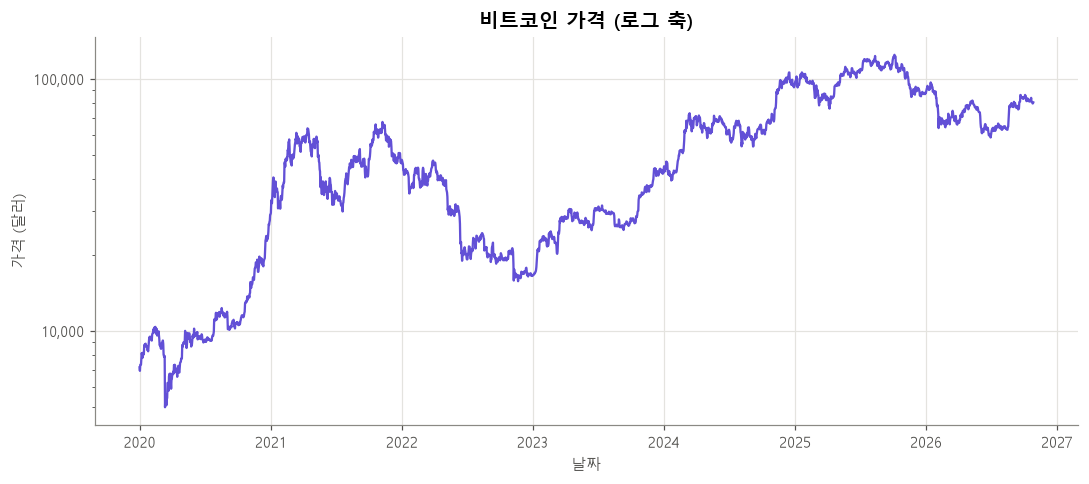

In [36]:
BTC_COLOR = "#6250d6"   # 보라 (비트코인 전용)

fig, ax = plt.subplots()
ax.plot(btc.index, btc.values, color=BTC_COLOR)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax.set_title("비트코인 가격 (로그 축)")
ax.set_xlabel("날짜")
ax.set_ylabel("가격 (달러)")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_btc_price.png", dpi=200)
plt.show()

## 2-8. 금리와 합치기

### 금리 데이터 불러오기
이 셀이 하는 일: 섹션 1에서 저장한 `rates.parquet`에서 **기준금리**(`base_rate`)와 **2년물 국채금리**(`DGS2`)를 가져온다.

왜 두 금리를 같이 보나?
- **기준금리**: **지금** 준비금이 받는 금리. 발행사 이익에 바로 들어간다.
- **2년물 국채금리**: 시장이 예상하는 **앞으로 2년간의 평균 단기금리**에 가깝다. 사람들은 금리가 실제로 바뀌기 **전에** 예상만으로 움직일 수 있다. 2년물이 기준금리보다 먼저 움직였다면, 유통량도 기대를 따라 먼저 움직였는지 비교해 볼 수 있다.
- 2년물 − 기준금리 > 0 이면 시장이 **인상**을, < 0 이면 **인하**를 예상한다는 뜻이다.

In [37]:
rates_saved = pd.read_parquet(PROC_DIR / "rates.parquet")
rates_saved[["base_rate", "base_source", "DGS2"]].tail(3)

,base_rate,base_source,DGS2
date,,,
2026-10-22,3.90,SOFR,4.65
2026-10-23,3.92,SOFR,4.69
2026-10-26,3.93,SOFR,4.68


### 날짜 기준으로 합치기
이 셀이 하는 일: USDC 날짜(매일)를 기준으로 모든 데이터를 붙여 `usdc_daily` 표를 만든다.
- 금리는 **주말·휴일에 공표되지 않는다.** 그날은 직전 영업일 금리가 그대로 적용되므로 **직전 값**으로 채운다. 기준금리의 출처 열에는 `주말(직전값)`이라고 적는다.
- 2020-01-01은 공휴일이라 그날 2년물 값이 없다. 그래서 **합치기 전에** 2000년부터 있는 금리 표에서 먼저 직전 값을 채운다(2019년 마지막 영업일 값).
- 비트코인 가격은 원본에서 **2020-09-04 하루**가 비어 있다. 월말이 아니라 월간 데이터에는 영향이 없고, 일별에서는 직전 값으로 채운다.
- **전체 시장**(`stable_total_bn`)은 2-4에서 정한 대로 **달러 스테이블코인 전체 − UST**다.

In [38]:
days = usdc.index   # 2020-01-01부터 매일

usdc_daily = pd.DataFrame({
    "usdc_bn":          usdc,
    "usdt_bn":          usdt.reindex(days),
    "stable_total_bn":  market_now,
    "btc_usd":          btc.reindex(days).ffill(),                        # 2020-09-04 하루 → 직전 값
    "base_rate":        rates_saved["base_rate"].reindex(days).ffill(),
    "base_source":      rates_saved["base_source"].reindex(days).fillna("주말(직전값)"),
    "dgs2":             rates_saved["DGS2"].ffill().reindex(days).ffill(),   # 휴일 먼저 채우고 → 주말 채우기
    "event_market":     event_cols["market"],
    "event_usdc":       event_cols["usdc"],
    "event_regulation": event_cols["regulation"],
    "event_name":       event_name,
    "data_flag":        data_flag,
    "data_note":        data_note,
})
usdc_daily.index.name = "date"

print("행, 열:", usdc_daily.shape)
print("빈 칸:", usdc_daily.drop(columns=["event_name"]).isna().sum().loc[lambda s: s > 0].to_dict() or "없음")

행, 열: (2491, 13)
빈 칸: 없음


## 2-9. USDC = 전체 시장 × USDC 점유율

USDC 유통량을 두 부분으로 나눈다.

$$\text{USDC} = \underbrace{\text{전체 스테이블코인 시장}}_{\text{시장이 커졌나?}} \times \underbrace{\text{USDC 점유율}}_{\text{USDC가 다른 코인보다 잘 팔렸나?}}$$

- 같은 "USDC 10% 증가"라도, 시장 전체가 커져서인지 USDC가 남의 몫을 가져와서인지에 따라 의미가 다르다.
- 금리는 모든 스테이블코인에 비슷하게 영향을 주므로 주로 **시장 크기** 쪽에, 바이낸스·SVB 같은 고유 사건은 주로 **점유율** 쪽에 나타날 것으로 예상할 수 있다.
- 양쪽에 **로그**를 씌우면 곱하기가 더하기로 바뀐다: log(USDC) = log(시장) + log(점유율). 그래서 다음 단계의 **월간 로그 변화율**도 "시장 변화율 + 점유율 변화율"로 정확히 나뉜다.
  - **로그 변화율**: log(이번 달) − log(지난달). 변화가 작을 때는 % 변화율과 거의 같다.

이 셀이 하는 일: 점유율 열(`usdc_share`, %)을 만들고, 시장 × 점유율이 USDC와 정확히 같은지 확인한다.

In [39]:
usdc_daily["usdc_share"] = usdc_daily["usdc_bn"] / usdc_daily["stable_total_bn"] * 100

rebuilt = usdc_daily["stable_total_bn"] * usdc_daily["usdc_share"] / 100   # 시장 × 점유율
print("시장 × 점유율 − USDC 의 최대 오차:", f"{(rebuilt - usdc_daily['usdc_bn']).abs().max():.2e}", "bn (0이면 정확)")

usdc_daily[["usdc_bn", "stable_total_bn", "usdc_share"]].iloc[[0, -1]].round(2)

시장 × 점유율 − USDC 의 최대 오차: 1.42e-14 bn (0이면 정확)


,usdc_bn,stable_total_bn,usdc_share
date,,,
2020-01-01,0.52,4.16,12.41
2026-10-26,71.71,302.82,23.68


## 2-10. 주간·월간 데이터 만들기
이 셀이 하는 일: 일별 표를 **주 단위**(일요일 마감)와 **월 단위**(말일 마감)로 묶는다.
- **유통량·시장·점유율·비트코인 가격은 그 기간의 마지막 날 값**을 쓴다. 유통량은 '잔액'이라 7일치를 더하면 의미가 없다. (은행 잔고를 일주일 치 더하지 않는 것과 같다) 월간 로그 변화율도 월말 값끼리 비교해야 한다.
- **금리는 그 기간의 평균**을 쓴다. 그 주(달) 동안 준비금이 평균적으로 받은 금리이기 때문이다.
- 이벤트·데이터 표시는 그 기간에 **하루라도** 있으면 1로 표시한다.

In [40]:
AGG_RULES = {
    "usdc_bn":          "last",   # 마지막 날 값
    "usdt_bn":          "last",
    "stable_total_bn":  "last",
    "usdc_share":       "last",
    "btc_usd":          "last",
    "base_rate":        "mean",   # 평균
    "dgs2":             "mean",
    "event_market":     "max",    # 하루라도 1이면 1
    "event_usdc":       "max",
    "event_regulation": "max",
    "data_flag":        "max",
}

usdc_weekly = usdc_daily.resample("W").agg(AGG_RULES)     # W: 주 단위 (일요일 마감)
usdc_monthly = usdc_daily.resample("ME").agg(AGG_RULES)   # ME: 월 단위 (말일 마감)

print("주간:", usdc_weekly.shape, "| 월간:", usdc_monthly.shape)
usdc_monthly.loc[usdc_monthly[["event_market", "event_usdc", "event_regulation"]].any(axis=1)]

주간: (357, 11) | 월간: (82, 11)


,usdc_bn,usdt_bn,stable_total_bn,usdc_share,btc_usd,base_rate,dgs2,event_market,event_usdc,event_regulation,data_flag
date,,,,,,,,,,,
2022-05-31,53.740917,72.563691,158.777842,33.846610,31804.27,0.721290,2.610323,1,0,0,False
2022-09-30,47.899407,67.951354,149.499370,32.039872,19415.80,2.489667,3.813667,0,1,0,False
2022-10-31,43.017550,69.258582,145.740844,29.516469,20472.79,3.034194,4.374194,0,1,0,False
2022-11-30,42.807756,65.282829,141.295586,30.296598,17179.78,3.745667,4.491000,1,0,0,False
2023-03-31,32.596519,79.665015,131.736579,24.743711,28492.72,4.629677,4.290968,0,1,0,False
2025-07-31,63.695607,164.580462,264.183852,24.110333,113248.73,4.335484,3.884839,0,0,1,False
2025-08-31,71.341964,168.005950,280.910657,25.396674,109240.55,4.346129,3.700645,0,0,1,False


## 2-11. 그래프

### 그래프 공통 준비
이 셀이 하는 일: 섹션 2 그래프에서 쓸 색을 정하고, 이벤트를 세로선으로 그리는 함수를 만든다.
- 이벤트 종류마다 선 모양을 다르게 한다: 시장 전체 충격 `--`(긴 점선), USDC 고유 충격 `:`(짧은 점선), 제도 변화 `-.`(점·선)
- 이벤트가 몰려 있어 이름이 겹치지 않도록 글씨를 **세로로**, 선의 **오른쪽·왼쪽 번갈아** 적는다. 글씨가 데이터를 가리지 않게 그래프 위쪽에 여백을 둔다.

In [41]:
COIN_COLORS = {"USDC": COLORS[0], "USDT": COLORS[1]}   # 섹션 2 전체에서 색은 고정
MARKET_COLOR = "#d55181"                                 # 전체 시장: 자주색
RATE_COLORS = {"base_rate": COLORS[2], "dgs2": COLORS[3]}
EVENT_STYLES = {"market": "--", "usdc": ":", "regulation": "-."}
EVENT_KIND_NAMES = {"market": "시장 전체 충격", "usdc": "USDC 고유 충격", "regulation": "제도 변화"}


def draw_events(ax, with_labels=True):
    # 이벤트 시작일에 세로선을 긋고, 원하면 이름을 세로로 적는다
    if with_labels:
        low, high = ax.get_ylim()
        ax.set_ylim(low, high + (high - low) * 0.45)   # 위쪽에 글씨 들어갈 여백
    by_date = sorted(EVENTS.items(), key=lambda item: item[1][1])   # 날짜순
    for i, (name, (kind, start, end)) in enumerate(by_date):
        ax.axvline(pd.Timestamp(start), color=MUTED, linestyle=EVENT_STYLES[kind], linewidth=1.2)
        if with_labels:
            ax.text(pd.Timestamp(start), ax.get_ylim()[1], f" {name} ", rotation=90,
                    ha="left" if i % 2 == 0 else "right",   # 선 오른쪽 / 왼쪽 번갈아
                    va="top", color=TEXT_SUB, fontsize=8)


def event_legend_handles():
    # 범례에 넣을 '이벤트 종류별 선 모양' 견본
    from matplotlib.lines import Line2D
    return [Line2D([], [], color=MUTED, linestyle=style, label=EVENT_KIND_NAMES[kind])
            for kind, style in EVENT_STYLES.items()]


def draw_rates(ax):
    # 아래 칸: 기준금리와 2년물 국채금리
    ax.plot(usdc_daily.index, usdc_daily["base_rate"], color=RATE_COLORS["base_rate"], label="기준금리")
    ax.plot(usdc_daily.index, usdc_daily["dgs2"], color=RATE_COLORS["dgs2"], label="2년물 국채금리")
    ax.set_ylabel("금리 (%)")
    ax.legend(loc="upper left")

### USDC와 USDT 유통량
이 셀이 하는 일: 두 코인의 유통량(bn 달러)을 한 그래프에 그린다. 단위가 같으므로 축 하나로 그린다.

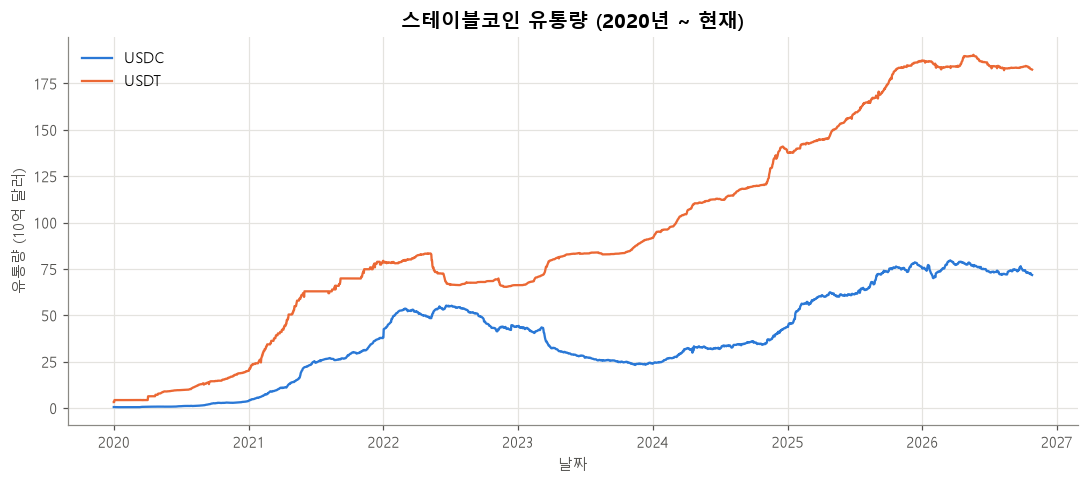

In [42]:
fig, ax = plt.subplots()
ax.plot(usdc_daily.index, usdc_daily["usdc_bn"], color=COIN_COLORS["USDC"], label="USDC")
ax.plot(usdc_daily.index, usdc_daily["usdt_bn"], color=COIN_COLORS["USDT"], label="USDT")

ax.set_title("스테이블코인 유통량 (2020년 ~ 현재)")
ax.set_xlabel("날짜")
ax.set_ylabel("유통량 (10억 달러)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_usdc_usdt_supply.png", dpi=200)
plt.show()

### 전체 스테이블코인 시장과 금리
이 셀이 하는 일: 위 칸에 **전체 시장**(UST 제외), 아래 칸에 **기준금리와 2년물**을 그린다. 가로축(날짜)은 공유한다.
- 금리와 시장은 단위가 달라서 축 하나에 못 그린다. 축 2개 대신 **위아래로 나눠** 그리면, 축 범위 때문에 생기는 착시 없이 **움직인 시점**을 비교할 수 있다.

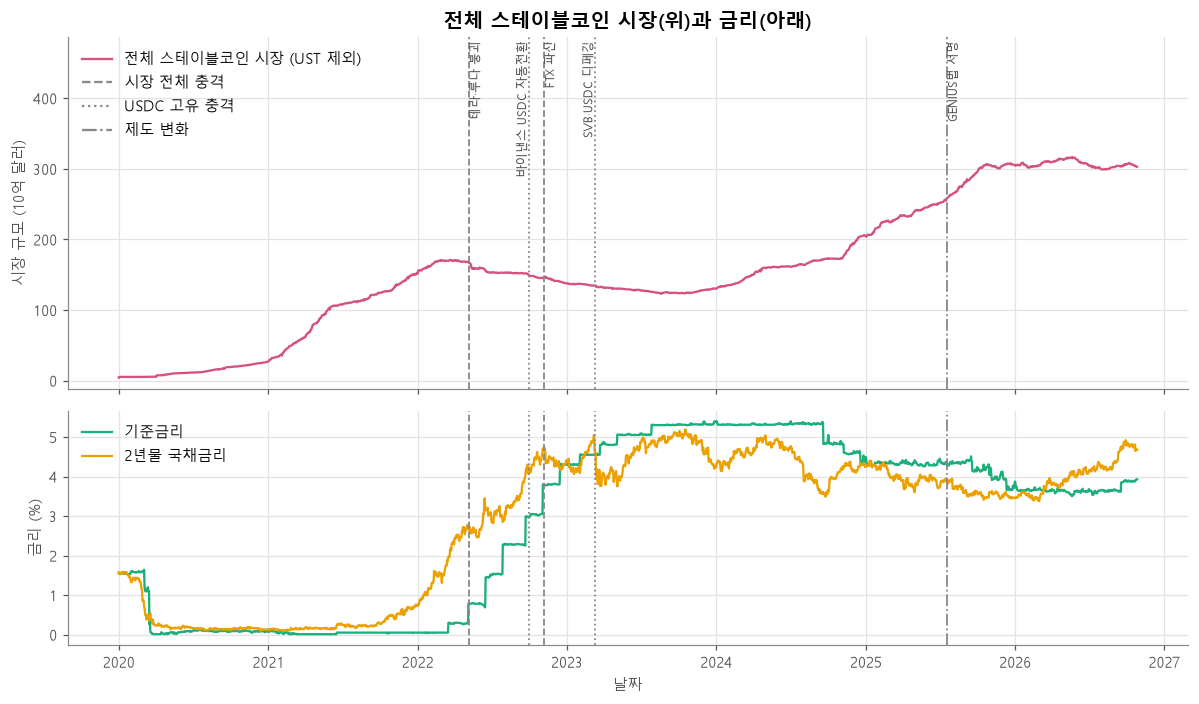

In [43]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})

top.plot(usdc_daily.index, usdc_daily["stable_total_bn"], color=MARKET_COLOR, label="전체 스테이블코인 시장 (UST 제외)")
top.set_ylabel("시장 규모 (10억 달러)")
top.legend(handles=top.get_legend_handles_labels()[0] + event_legend_handles(), loc="upper left")
draw_events(top)

draw_rates(bottom)
draw_events(bottom, with_labels=False)

top.set_title("전체 스테이블코인 시장(위)과 금리(아래)")
bottom.set_xlabel("날짜")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_market_and_rates.png", dpi=200)
plt.show()

### USDC 점유율과 금리
이 셀이 하는 일: 위 칸에 **USDC 점유율**(전체 시장 중 USDC 비중), 아래 칸에 금리를 그린다.
- 2020년 1·4월의 USDT 계단(2-5) 때문에 2020년 초반 점유율은 조심해서 봐야 한다.

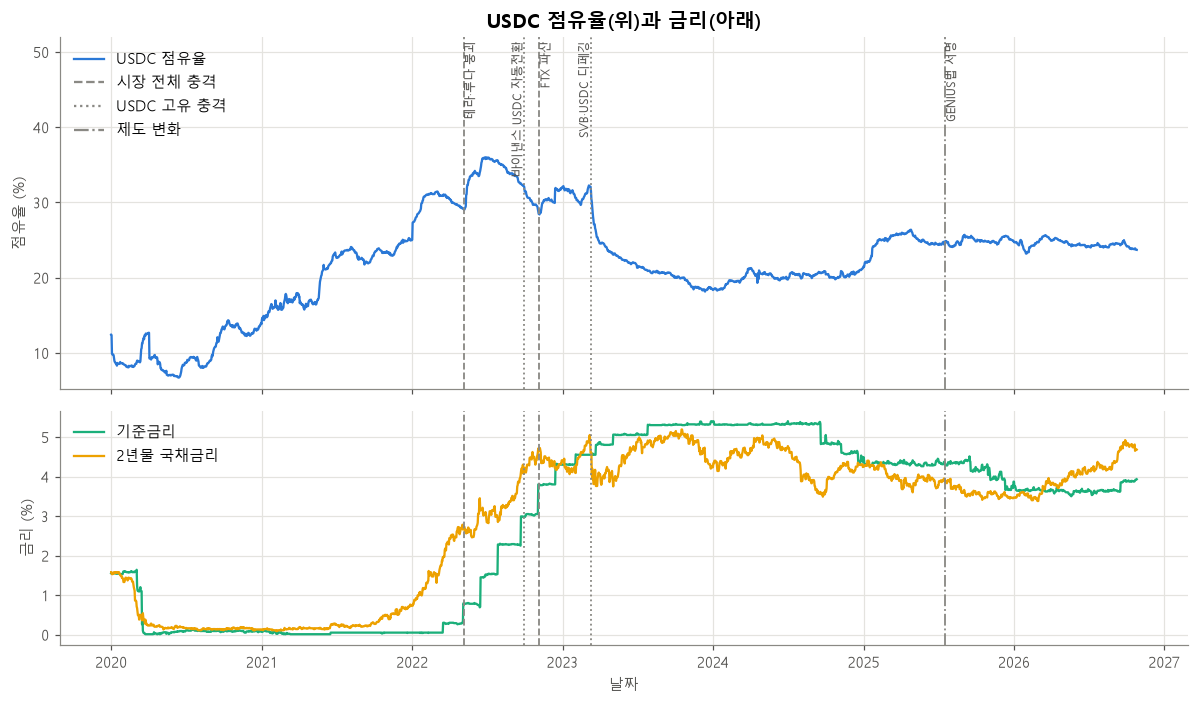

In [44]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})

top.plot(usdc_daily.index, usdc_daily["usdc_share"], color=COIN_COLORS["USDC"], label="USDC 점유율")
top.set_ylabel("점유율 (%)")
top.legend(handles=top.get_legend_handles_labels()[0] + event_legend_handles(), loc="upper left")
draw_events(top)

draw_rates(bottom)
draw_events(bottom, with_labels=False)

top.set_title("USDC 점유율(위)과 금리(아래)")
bottom.set_xlabel("날짜")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_share_and_rates.png", dpi=200)
plt.show()

### USDC 유통량과 기준금리 (축 2개)
이 셀이 하는 일: 왼쪽 축에 USDC 유통량, 오른쪽 축에 기준금리를 그리고 이벤트를 세로선으로 표시한다.

> **축 2개 그래프를 볼 때 주의:** 두 선이 "같이 움직이는 것처럼" 보이는 정도는 **양쪽 축의 범위를 어떻게 잡느냐**에 따라 달라진다. 판단은 위의 위아래 그래프와 2-13의 표로 한다.

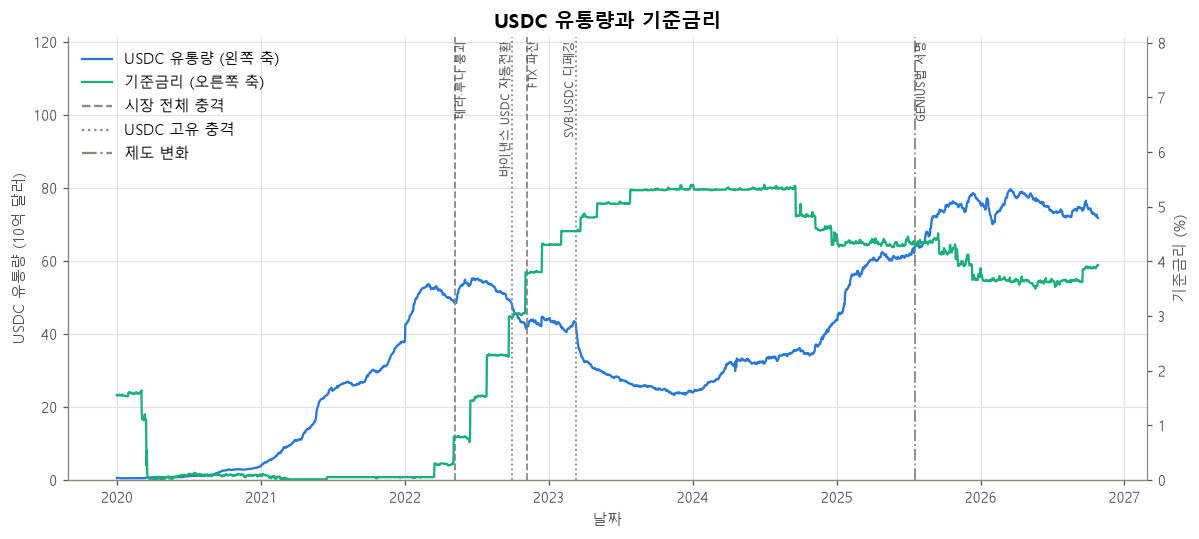

In [45]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()   # 같은 가로축을 쓰는 두 번째 세로축(오른쪽)

line1, = ax1.plot(usdc_daily.index, usdc_daily["usdc_bn"], color=COIN_COLORS["USDC"], label="USDC 유통량 (왼쪽 축)")
line2, = ax2.plot(usdc_daily.index, usdc_daily["base_rate"], color=RATE_COLORS["base_rate"], label="기준금리 (오른쪽 축)")

ax1.set_ylim(0, usdc_daily["usdc_bn"].max() * 1.05)
ax2.set_ylim(0, usdc_daily["base_rate"].max() * 1.5)   # 왼쪽 축의 위쪽 여백(×1.45)과 높이를 비슷하게
draw_events(ax1)

ax2.spines["right"].set_visible(True)
ax2.grid(False)   # 격자는 왼쪽 축 것만

ax1.set_title("USDC 유통량과 기준금리")
ax1.set_xlabel("날짜")
ax1.set_ylabel("USDC 유통량 (10억 달러)")
ax2.set_ylabel("기준금리 (%)")
ax1.legend(handles=[line1, line2] + event_legend_handles(), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_usdc_vs_base_rate.png", dpi=200)
plt.show()

## 2-12. 저장
이 셀이 하는 일: 일별·주간·월간 표를 parquet로 저장하고, 일별 파일을 다시 읽어 확인한다.

| 파일 | 내용 |
|---|---|
| `data/processed/usdc_rates.parquet` | 일별 (2020-01-01~) |
| `data/processed/usdc_rates_weekly.parquet` | 주간 (일요일 마감) |
| `data/processed/usdc_rates_monthly.parquet` | 월간 (말일 마감) ← 다음 단계 회귀용 |

| 열 | 내용 |
|---|---|
| `usdc_bn`, `usdt_bn` | 유통량 (10억 달러, 코인 개수 기준) |
| `stable_total_bn` | 전체 달러 스테이블코인 시장 (UST 제외) |
| `usdc_share` | USDC 점유율 = USDC ÷ 전체 시장 × 100 (%) |
| `btc_usd` | 비트코인 가격 (달러, 통제 변수) |
| `base_rate`, `base_source` | 기준금리와 출처 (주말은 `주말(직전값)`) |
| `dgs2` | 2년물 국채금리 (%, 금리 기대 지표) |
| `event_market`, `event_usdc`, `event_regulation` | 이벤트 종류별 0/1 |
| `event_name` | 이벤트 이름 (일별만) |
| `data_flag`, `data_note` | 데이터 오류 의심 여부와 이유 (`data_note`는 일별만) |

In [46]:
usdc_daily.to_parquet(PROC_DIR / "usdc_rates.parquet")
usdc_weekly.to_parquet(PROC_DIR / "usdc_rates_weekly.parquet")
usdc_monthly.to_parquet(PROC_DIR / "usdc_rates_monthly.parquet")

check = pd.read_parquet(PROC_DIR / "usdc_rates.parquet")
print("저장 완료 | 일별:", check.shape, "| 기간:", check.index[0].date(), "~", check.index[-1].date())
check.dtypes

저장 완료 | 일별: (2491, 14) | 기간: 2020-01-01 ~ 2026-10-26


usdc_bn             float64
usdt_bn             float64
stable_total_bn     float64
btc_usd             float64
base_rate           float64
base_source             str
dgs2                float64
event_market          int64
event_usdc            int64
event_regulation      int64
event_name           string
data_flag              bool
data_note               str
usdc_share          float64
dtype: object

## 2-13. 국면별 정리 (회귀분석 전, 숫자로 확인)
이 셀이 하는 일: 금리 국면별로 USDC, 전체 시장, 점유율, 비트코인, 2년물이 어떻게 변했는지 표로 정리한다.

In [47]:
PHASES = {
    "제로금리":          ("2020-03-16", "2022-03-16"),
    "인상기":            ("2022-03-17", "2023-07-27"),
    "고금리 유지":        ("2023-07-28", "2024-09-17"),
    "인하기":            ("2024-09-18", "2025-12-10"),
    "인하 멈춤~재인상":    ("2025-12-11", str(usdc_daily.index[-1].date())),
}

phase_rows = {}
for name, (start, end) in PHASES.items():
    p = usdc_daily.loc[start:end]
    first, last = p.iloc[0], p.iloc[-1]
    phase_rows[name] = {
        "평균 기준금리(%)":   round(p["base_rate"].mean(), 2),
        "2년물 시작→끝(%)":   f"{first['dgs2']:.2f} → {last['dgs2']:.2f}",
        "USDC(bn)":         f"{first['usdc_bn']:.1f} → {last['usdc_bn']:.1f}",
        "전체 시장(bn)":      f"{first['stable_total_bn']:.0f} → {last['stable_total_bn']:.0f}",
        "USDC 점유율(%)":    f"{first['usdc_share']:.1f} → {last['usdc_share']:.1f}",
        "비트코인(천 달러)":   f"{first['btc_usd'] / 1000:.0f} → {last['btc_usd'] / 1000:.0f}",
    }
pd.DataFrame(phase_rows).T

,평균 기준금리(%),2년물 시작→끝(%),USDC(bn),전체 시장(bn),USDC 점유율(%),비트코인(천 달러)
제로금리,0.05,0.36 → 1.95,0.6 → 52.3,5 → 170,11.2 → 30.9,5 → 41
인상기,3.19,1.94 → 4.91,52.3 → 26.2,170 → 126,30.9 → 20.9,41 → 29
고금리 유지,5.32,4.87 → 3.59,26.3 → 35.2,126 → 171,20.9 → 20.6,29 → 62
인하기,4.37,3.61 → 3.54,35.4 → 78.1,172 → 306,20.6 → 25.5,63 → 91
인하 멈춤~재인상,3.67,3.52 → 4.68,78.2 → 71.7,306 → 303,25.5 → 23.7,92 → 80


### 정리 (2026-10-26 데이터 기준, 회귀분석 전)

**분해해서 보니 달라 보이는 것**
- **전체 시장**은 금리 국면과 큰 흐름이 맞는다. 첫 인상(2022-03-17) 직후인 2022-03-21에 정점(170bn)을 찍고 줄었다. 바닥은 2023-08-19(123bn)로, 2년물 금리 정점(2023-10-17, 5.19%)보다 두 달 빨랐다. 실제 첫 인하(2024-09)보다는 1년 넘게 앞선다. → 기준금리보다 **금리 기대(2년물)** 쪽이 시점이 더 가깝다.
- 하지만 **고금리 유지기**(평균 5.3%)에도 시장은 126 → 171bn으로 커졌다. 같은 기간 비트코인은 2배 넘게 올랐다. → 금리만으로는 설명이 안 되고, **코인 시장 분위기**가 큰 몫을 한다.
- **USDC 점유율**은 금리보다 **USDC 고유 사건**에서 크게 움직인다. 바이낸스 자동전환과 SVB 이후 32% → 21%로 떨어졌다. 그 뒤 고금리 유지기 내내 21% 근처에 머물렀고, 2025년 초에 21% → 26%로 올랐다.
- 이벤트 분류도 데이터와 맞는다. SVB 기간에는 USDC −10.6bn, USDT +7.9bn으로 **고유 충격**이고, 테라 기간에는 전체 시장 −8.2bn으로 **시장 충격**이다(2-6 표).

**다음 단계(월간 로그 변화율 회귀) 전에 정해야 할 것**
1. **마지막 달(2026-10)은 26일까지만 있다.** 월간 표의 10월 값은 '월말'이 아니므로 회귀에서는 빼야 한다.
2. **전체 시장 안에 USDC가 들어 있다**(약 24%). 그래서 USDC와 시장은 기계적으로 같이 움직인다. 시장을 설명변수로 쓸 때는 **USDC를 뺀 시장**(`stable_total_bn − usdc_bn`)도 검토하자.
3. **2020년 1월·4월의 USDT 계단**은 그 달의 시장·점유율 변화율에 그대로 들어간다. 더미로 처리하거나, 시작 시점을 2020년 5월로 늦추는 방법이 있다.
4. **금리를 '수준'으로 넣을지 '변화'로 넣을지** 정해야 한다. 기회비용 논리라면 금리 수준이 유통량 **증가율**에 영향을 준다. 기대 효과는 2년물 변화로 볼 수 있다.
5. **관측치가 적다.** 월간 약 80개다. 금리 2개, 비트코인, 이벤트 3개를 넣으면 추정할 계수가 많아지므로, 변수 수를 아껴야 한다.
6. 바이낸스 자동전환처럼 **이벤트가 두 달에 걸치면** 월간 더미가 두 달 모두 1이 된다(2022년 9·10월).

# 3. Circle 재무제표

**목표:** 발행사 손익 π = (1 − s)·r·R − C 에 들어갈 **고정비 C**와 **배분율 s**를 USDC 발행사 Circle의 실제 공시로 추정한다.

| 기호 | 뜻 | Circle 공시에서 |
|---|---|---|
| C | 연간 고정비 | 영업비용 (인건비, 일반관리비, IT, 감가상각 등) |
| s | 배분율: 준비금 이자 중 유통 파트너(Coinbase 등)에게 주는 몫 | 유통·거래 비용 ÷ 준비금 이자수익 |

## 3-1. SEC EDGAR XBRL API

**SEC EDGAR**: 미국 상장회사의 공시를 모아 둔 미국 증권거래위원회(SEC)의 시스템. **XBRL**은 재무제표 숫자에 "이건 매출, 이건 영업비용" 같은 **표준 이름표(태그)**를 붙여 둔 형식이라, 프로그램으로 숫자를 바로 뽑을 수 있다.

| 주소 | 돌려주는 것 |
|---|---|
| `https://data.sec.gov/api/xbrl/companyfacts/CIK0001876042.json` | Circle(CIK 1876042)의 모든 XBRL 숫자 (표준 태그) |

- **CIK**: SEC가 회사마다 붙인 고유번호.
- SEC는 요청할 때 **User-Agent**(누가 요청하는지: 이름 + 이메일)를 꼭 적으라고 요구한다. 없으면 접속이 거부된다.

### 다운로드
이 셀이 하는 일: Circle의 XBRL 데이터를 받아 `data/raw/sec/circle_companyfacts.json`에 그대로 저장한다.

In [48]:
SEC_DIR = PROJECT / "data" / "raw" / "sec"
SEC_DIR.mkdir(parents=True, exist_ok=True)
SEC_USER_AGENT = "stablecoin-floor research drake1118@hanyang.ac.kr"   # SEC 요구: 이름 + 이메일
CIRCLE_CIK = "0001876042"

sec_path = SEC_DIR / "circle_companyfacts.json"
REFRESH_SEC = False
if REFRESH_SEC or not sec_path.exists():
    response = requests.get(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIRCLE_CIK}.json",
                            headers={"User-Agent": SEC_USER_AGENT}, timeout=60)
    response.raise_for_status()
    sec_path.write_bytes(response.content)
    print("저장 완료 →", sec_path.name)
else:
    print("이미 받은 파일이 있어 건너뜀")

facts = json.loads(sec_path.read_text())
print("회사:", facts["entityName"], "| 표준 태그 수:", len(facts["facts"]["us-gaap"]))

이미 받은 파일이 있어 건너뜀
회사: CIRCLE INTERNET GROUP, INC. | 표준 태그 수: 292


## 3-2. 쓰는 태그

| 태그 | 뜻 |
|---|---|
| `Revenues` | 총수익 (준비금 이자 + 기타 수익) |
| `InterestAndDividendIncomeOperating` | **준비금 이자수익** |
| `OperatingExpenses` | **영업비용** 합계 |
| `OperatingIncomeLoss` | 영업이익 |
| `ShareBasedCompensation` | 주식보상비용 (영업비용에 포함, 현금이 나가지 않는 비용) |

**유통·거래 비용은 어떻게 구하나?** Circle은 이 항목을 자기 회사 전용 태그로 공시해서, 이 API(표준 태그만 제공)에는 없다. 대신 손익계산서의 관계를 이용한다.

$$\text{총수익} - \text{유통·거래 비용} - \text{영업비용} = \text{영업이익} \;\Rightarrow\; \text{유통·거래 비용} = \text{총수익} - \text{영업비용} - \text{영업이익}$$

### 분기 값 뽑기
이 셀이 하는 일: 각 태그에서 **3개월짜리(분기)** 값을 뽑는 함수를 만든다.
- XBRL에는 같은 숫자가 3개월·6개월·9개월·1년 등 여러 기간으로 들어 있다. 4분기는 따로 공시하지 않으므로 **1년 값 − 9개월 값**으로 계산한다.

In [49]:
def quarterly_values(tag):
    rows = pd.DataFrame(facts["facts"]["us-gaap"][tag]["units"]["USD"])
    rows = rows[rows["start"].notna()].copy()                       # 기간 값(손익 항목)만
    rows["start"] = pd.to_datetime(rows["start"])
    rows["end"] = pd.to_datetime(rows["end"])
    rows["days"] = (rows["end"] - rows["start"]).dt.days
    rows = rows.sort_values("filed").drop_duplicates(["start", "end"], keep="last")   # 정정 공시는 최신 값

    quarters = rows[rows["days"].between(80, 100)].set_index("end")["val"]
    annual = rows[rows["days"].between(350, 380)]
    nine = rows[rows["days"].between(260, 280)]
    for _, year in annual.iterrows():                               # 4분기 = 1년 − 9개월
        if year["end"] in quarters.index:
            continue
        first9 = nine[(nine["start"] == year["start"]) & (nine["end"] < year["end"])]
        if len(first9):
            quarters.loc[year["end"]] = year["val"] - first9["val"].iloc[-1]
    return quarters.sort_index() / 1e6                              # 백만 달러

### 분기 손익표
이 셀이 하는 일: 태그별 분기 값을 한 표로 모으고, 유통·거래 비용과 분기별 배분율 s를 계산한다.

In [50]:
circle_q = pd.DataFrame({
    "총수익":        quarterly_values("Revenues"),
    "준비금 이자":    quarterly_values("InterestAndDividendIncomeOperating"),
    "영업비용":       quarterly_values("OperatingExpenses"),
    "영업이익":       quarterly_values("OperatingIncomeLoss"),
    "주식보상비용":    quarterly_values("ShareBasedCompensation"),
}).dropna()
circle_q["유통·거래 비용"] = circle_q["총수익"] - circle_q["영업비용"] - circle_q["영업이익"]
circle_q["배분율 s"] = circle_q["유통·거래 비용"] / circle_q["준비금 이자"]
circle_q.index.name = "분기 말"
circle_q.round(2)

,총수익,준비금 이자,영업비용,영업이익,주식보상비용,유통·거래 비용,배분율 s
분기 말,,,,,,,
2024-06-30,430.03,423.26,131.41,50.25,16.70,248.38,0.59
2024-09-30,445.76,445.22,124.26,63.80,12.80,257.70,0.58
2024-12-31,435.37,432.97,130.03,0.79,11.14,304.55,0.70
2025-03-31,578.57,557.91,137.99,92.94,12.72,347.65,0.62
2025-06-30,658.08,634.27,576.72,-325.58,435.00,406.94,0.64
2025-09-30,739.76,711.24,211.13,81.02,59.10,447.61,0.63
2025-12-31,770.23,733.40,253.60,55.19,59.41,461.45,0.63
2026-03-31,694.13,652.51,242.35,45.00,51.84,406.78,0.62
2026-06-30,701.32,667.73,254.49,34.36,53.60,412.47,0.62


**읽는 법**
- **배분율 s**는 대부분 분기에서 약 0.58~0.64로 꽤 안정적이다(2024년 4분기만 0.70). 준비금 이자의 약 60%를 Coinbase 등 유통 파트너에게 넘긴다는 뜻이다.
- **영업비용**은 2025년 2분기에 크게 튄다. 6월 상장(IPO) 때 한꺼번에 잡힌 **주식보상비용**(약 4.4억 달러) 때문이다. 일회성이라 C 추정에서는 빼야 한다.
- 분기 값은 2024년 2분기부터 있다(상장 서류에 그 이전은 연간 값만 있다).

## 3-3. C와 s 추정

**결정 방법**: 상장 이후의 **최근 4개 분기**(TTM: 직전 12개월) 합계를 쓴다. IPO 일회성 비용이 빠지고, 지금의 비용 구조를 가장 잘 보여준다.
- C = 최근 4개 분기 영업비용 합계 (주식보상비용 포함)
- s = 최근 4개 분기 유통·거래 비용 합계 ÷ 준비금 이자 합계

이 셀이 하는 일: C와 s를 계산하고, 참고로 주식보상비용을 뺀 C도 보여준다.

In [51]:
ttm = circle_q.iloc[-4:]
C_circle = ttm["영업비용"].sum()                                   # 백만 달러 / 년
s_circle = ttm["유통·거래 비용"].sum() / ttm["준비금 이자"].sum()

print(f"기간: {ttm.index[0]:%Y-%m} ~ {ttm.index[-1]:%Y-%m} (최근 4개 분기)")
print(f"고정비 C  = {C_circle:,.0f} 백만 달러/년  (참고: 주식보상비용 제외 시 {C_circle - ttm['주식보상비용'].sum():,.0f})")
print(f"배분율 s  = {s_circle:.3f}  → 발행사 몫 1 − s = {1 - s_circle:.3f}")

기간: 2025-09 ~ 2026-06 (최근 4개 분기)
고정비 C  = 962 백만 달러/년  (참고: 주식보상비용 제외 시 738)
배분율 s  = 0.625  → 발행사 몫 1 − s = 0.375


### 점검: 준비금 이자 ÷ USDC 유통량 ≈ 금리?
이 셀이 하는 일: 분기 준비금 이자를 그 분기 평균 USDC 유통량으로 나눠 **연 수익률**로 바꾸고, 같은 분기 평균 SOFR와 비교한다. 비슷하면 "준비금 ≈ USDC 유통량, 수익률 ≈ 단기금리"라는 모형 가정이 맞는 것이다.

In [52]:
quarter_avg = usdc_daily[["usdc_bn", "base_rate"]].resample("QE").mean()
check_yield = pd.DataFrame({
    "평균 USDC(bn)":      quarter_avg["usdc_bn"],
    "준비금 수익률(%, 연)": circle_q["준비금 이자"] * 4 / (quarter_avg["usdc_bn"] * 1000) * 100,
    "평균 기준금리(%)":    quarter_avg["base_rate"],
}).dropna()
check_yield["차이(%p)"] = check_yield["준비금 수익률(%, 연)"] - check_yield["평균 기준금리(%)"]
check_yield.round(2)

,평균 USDC(bn),"준비금 수익률(%, 연)",평균 기준금리(%),차이(%p)
2024-06-30,32.28,5.24,5.32,-0.07
2024-09-30,34.15,5.21,5.27,-0.06
2024-12-31,37.95,4.56,4.67,-0.10
2025-03-31,54.05,4.13,4.33,-0.20
2025-06-30,60.91,4.17,4.32,-0.16
2025-09-30,67.49,4.22,4.33,-0.11
2025-12-31,75.89,3.87,3.99,-0.13
2026-03-31,75.28,3.47,3.66,-0.19
2026-06-30,76.73,3.48,3.62,-0.14


**읽는 법**: 9개 분기 모두 준비금 수익률이 기준금리보다 **0.1~0.2%p 낮을 뿐** 거의 같이 움직인다. "준비금 ≈ USDC 유통량, 준비금 수익률 ≈ 단기금리"라는 모형 가정이 데이터와 맞는다.

### 저장
이 셀이 하는 일: 분기 손익표와 C·s 추정값을 `data/processed/`에 저장한다.

In [53]:
circle_q.to_csv(PROC_DIR / "circle_quarterly.csv")
pd.Series({"C_musd_per_year": C_circle, "s": s_circle,
           "ttm_start": ttm.index[0].date(), "ttm_end": ttm.index[-1].date()}).to_csv(PROC_DIR / "circle_params.csv",
                                                                                    header=["value"])
print("저장 완료: circle_quarterly.csv, circle_params.csv")

저장 완료: circle_quarterly.csv, circle_params.csv


## 3-4. 정리
- **C ≈ 9.6억 달러/년**, **s ≈ 0.62** (2025-Q3 ~ 2026-Q2, 상장 이후 4개 분기).
- Circle 자신의 손익분기 금리: r* = C ÷ ((1 − s) × R). USDC 약 740억 달러 기준이면 약 3.5%로, 지금 SOFR(3.93%)와 멀지 않다.
- 준비금 수익률은 기준금리보다 매 분기 약 0.1~0.2%p 낮다. 모형은 준비금 수익률 = 기준금리로 두므로 이 차이만큼 이익을 조금 크게 본다(한계).
- 한계: 유통·거래 비용을 손익 관계로 역산했다(기타 비용이 조금 섞임). 기타 수익(총수익 − 준비금 이자, 분기 약 3~4천만 달러)은 모형에서 뺐다.

---

# 2단계: 발행량 ~ 금리 회귀분석

*원본 파일: `notebooks/02_supply_regression.ipynb`*

# 02. 발행량과 금리의 관계 (회귀분석)

**질문:** 금리가 바뀌면 스테이블코인 시장(=발행사의 준비금 R)은 얼마나 변하나?
이 답(계수 b1)이 6단계 시뮬레이션에서 "금리가 떨어질 때 R이 같이 늘어나 손실을 일부 메워 주는가"를 정한다.

**이번 분석에서 정한 것**

| 항목 | 결정 |
|---|---|
| 기간 | 2020년 5월 ~ 2026년 9월 (월간). 2026년 10월은 월말 전이라 제외 |
| 종속변수(설명하고 싶은 것) | **USDC를 뺀** 스테이블코인 시장의 월간 로그 변화율. 전체 시장은 확인용 |
| 금리 | **2년물 국채금리 변화(%p)**. 기준금리·금리 수준은 확인용 |
| 통제 변수 | 비트코인 월간 로그 변화율, 시장 전체 충격 더미(`event_market`) |
| USDC 점유율 | 회귀하지 않음 |

**메인 회귀식**

$$\Delta\log(\text{USDC 제외 시장})_t = a + b_1\,\Delta(\text{2년물})_t + b_2\,\Delta\log(\text{비트코인})_t + b_3\,\text{event\_market}_t + \varepsilon_t$$

- **회귀분석**: 여러 요인이 결과에 각각 얼마나 영향을 주는지, 데이터에 가장 잘 맞는 직선(평면)을 찾아 숫자로 뽑는 방법.
- **b1이 가장 중요하다.** "2년물 금리가 한 달에 1%p 오르면, 그 달 시장이 몇 % 변하나"를 뜻한다.
- **USDC를 뺀 시장을 쓰는 이유**: 전체 시장 안에 USDC가 약 24% 들어 있어서, 전체 시장을 쓰면 USDC 고유 사건(SVB 등)이 섞인다. USDC를 빼면 "금리가 스테이블코인 수요 전반에 주는 영향"을 더 깨끗하게 볼 수 있다.

## 1. 준비

### 라이브러리 불러오기
이 셀이 하는 일: 이번 노트북에서 쓸 도구를 불러온다.
- `numpy`: 로그 같은 수학 계산 도구
- `statsmodels`: 회귀분석 도구

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf   # 자기상관 계산용 (5번에서 설명)

### 경로와 그래프 설정
이 셀이 하는 일: 폴더 경로를 정하고, 01번 노트북과 같은 그래프 설정(한글 폰트)을 불러온다.

In [2]:
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")   # 표의 숫자를 소수 넷째 자리까지

## 2. 데이터 불러오기
이 셀이 하는 일: 01번 노트북에서 만든 **월간** 데이터를 읽고, 2026년 9월까지만 남긴다.
- 월간 데이터의 유통량·시장·비트코인은 **월말 값**, 금리는 **월평균**이다. (01번 노트북 2-10)

In [3]:
monthly = pd.read_parquet(PROC_DIR / "usdc_rates_monthly.parquet")
monthly = monthly.loc[:"2026-09-30"]   # 2026년 10월(26일까지만 있음) 제외

print("기간:", monthly.index[0].date(), "~", monthly.index[-1].date(), "|", len(monthly), "개월")
monthly.tail(3)

기간: 2020-01-31 ~ 2026-09-30 | 81 개월


,usdc_bn,usdt_bn,stable_total_bn,usdc_share,btc_usd,base_rate,dgs2,event_market,event_usdc,event_regulation,data_flag
date,,,,,,,,,,,
2026-07-31,72.0554,183.4535,299.0603,24.0939,"62,886.6400",3.6161,4.2181,0,0,0,False
2026-08-31,74.0654,183.4957,302.4743,24.4865,"78,603.0200",3.6413,4.2252,0,0,0,False
2026-09-30,74.5835,183.8399,306.6731,24.3202,"83,482.5100",3.7487,4.6397,0,0,0,False


## 3. 변수 만들기

### 로그 변화율과 %p 변화
- **로그 변화율** Δlog(X) = log(이번 달) − log(지난달). 변화가 작을 때는 **% 변화율과 거의 같다.** (예: 0.05 ≈ 5% 증가)
  - 로그를 쓰는 이유: 시장 규모가 50억 달러일 때와 3,000억 달러일 때의 "10억 달러 증가"는 의미가 다르다. 비율로 보면 같은 기준으로 비교할 수 있다.
- **금리 변화** Δ(2년물) = 이번 달 평균 − 지난달 평균 (단위: **%p**, 퍼센트포인트). 예: 4.0% → 4.25%는 +0.25%p.

이 셀이 하는 일: 회귀에 쓸 변수들을 만들어 `data` 표에 담는다. 강건성 검정용 변수(전체 시장, 기준금리, 금리 수준, 앞뒤 시차)도 함께 만든다.
- **시차**: `shift(1)`은 한 칸 아래로 밀기 = **한 달 전** 값. `shift(-1)`은 한 칸 위로 = **한 달 뒤** 값.

In [4]:
data = pd.DataFrame(index=monthly.index)

# 종속변수
data["y_ex_usdc"] = np.log(monthly["stable_total_bn"] - monthly["usdc_bn"]).diff()   # 메인: USDC 제외 시장
data["y_total"]   = np.log(monthly["stable_total_bn"]).diff()                         # 확인용: 전체 시장

# 금리
data["d_dgs2"]    = monthly["dgs2"].diff()        # 메인: 2년물 변화 (%p)
data["d_base"]    = monthly["base_rate"].diff()   # 확인용: 기준금리 변화
data["dgs2_level"] = monthly["dgs2"]              # 확인용: 2년물 수준 (%)
for k in [1, 2]:
    data[f"d_dgs2_lag{k}"]  = data["d_dgs2"].shift(k)    # k개월 전 금리 변화
    data[f"d_dgs2_lead{k}"] = data["d_dgs2"].shift(-k)   # k개월 뒤 금리 변화

# 통제 변수
data["d_log_btc"]    = np.log(monthly["btc_usd"]).diff()
data["event_market"] = monthly["event_market"]

data = data.loc["2020-05":]   # 시작: 2020년 5월 (2020년 1·4월 USDT 계단 제외)
print("관측치:", len(data), "개월 |", data.index[0].date(), "~", data.index[-1].date())
data[["y_ex_usdc", "d_dgs2", "d_log_btc", "event_market"]].describe().T[["count", "mean", "std", "min", "max"]]

관측치: 77 개월 | 2020-05-31 ~ 2026-09-30


,count,mean,std,min,max
y_ex_usdc,77.0000,0.0431,0.0742,-0.1252,0.2967
d_dgs2,77.0000,0.0574,0.2217,-0.5319,0.6397
d_log_btc,77.0000,0.0294,0.1723,-0.4720,0.3862
event_market,77.0000,0.0260,0.1601,0.0000,1.0000


**읽는 법**
- `y_ex_usdc` 평균 약 0.043 = USDC 제외 시장이 **한 달 평균 약 4.3%** 커졌다. 2020~21년 급성장기가 평균을 끌어올렸다.
- `d_dgs2` 표준편차 약 0.22 = 2년물은 한 달에 보통 **±0.2%p** 정도 움직인다. 1%p는 아주 큰 움직임이라는 점을 기억하자.

## 4. 회귀 전에 눈으로 보기
이 셀이 하는 일: 가로축에 2년물 변화, 세로축에 USDC 제외 시장 변화율을 찍는다(점 하나 = 한 달). 시장 전체 충격이 있었던 달은 다른 색으로 표시한다.
- 점들이 **오른쪽 아래로** 기울어 있으면 "금리가 오른 달에 시장이 덜 컸다"는 뜻이다.

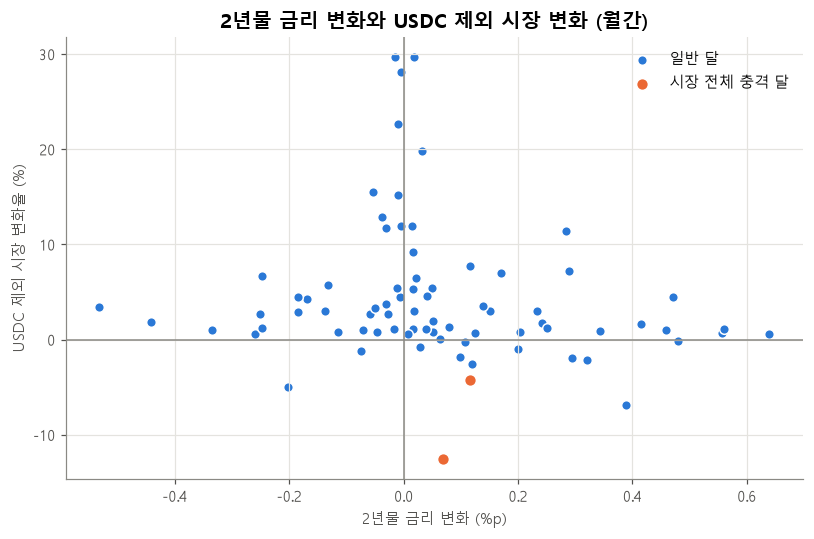

In [5]:
is_event = data["event_market"] == 1

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(data.loc[~is_event, "d_dgs2"], data.loc[~is_event, "y_ex_usdc"] * 100,
           s=40, color=COLORS[0], edgecolor="white", linewidth=1, label="일반 달")
ax.scatter(data.loc[is_event, "d_dgs2"], data.loc[is_event, "y_ex_usdc"] * 100,
           s=60, color=COLORS[1], edgecolor="white", linewidth=1, label="시장 전체 충격 달")
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1)

ax.set_title("2년물 금리 변화와 USDC 제외 시장 변화 (월간)")
ax.set_xlabel("2년물 금리 변화 (%p)")
ax.set_ylabel("USDC 제외 시장 변화율 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_scatter_dgs2_market.png", dpi=200)
plt.show()

**읽는 법**: 2년물이 거의 안 움직인 달(가로 0 근처)에 시장 성장률이 크게 흩어져 있다. 이건 대부분 2020~21년 급성장기다. 금리가 크게 움직인 달만 보면 약하게 오른쪽 아래로 기운 모양이다.

## 5. 왜 Newey-West 표준오차를 쓰나

**표준오차**: 추정값(b1)이 데이터가 조금 달랐다면 얼마나 달라졌을지, 즉 **불확실성의 크기**. 표준오차가 작을수록 추정값을 더 믿을 수 있고, 신뢰구간도 좁아진다.

보통 회귀(OLS)의 표준오차는 오차(ε)에 대해 두 가지를 가정한다.
1. **매달 오차가 서로 독립이다.** → 그런데 월간 경제 데이터는 이번 달의 '예상 밖 성장'이 다음 달에도 이어지기 쉽다(붐은 몇 달씩 간다). 이걸 **자기상관**이라고 한다.
2. **오차의 크기가 늘 비슷하다.** → 그런데 2020~21년에는 시장이 한 달에 20~30%씩 크기도 했고, 2024년에는 1~2%씩 움직였다. 시기마다 흔들림 크기가 다른 것을 **이분산**이라고 한다.

이 가정이 틀리면 보통 표준오차는 **틀린 값**이 나온다. 그러면 "의미 있다/없다" 판단도 틀린다.

**Newey-West(HAC) 표준오차**는 이 두 문제를 감안해서 표준오차를 다시 계산한다. (HAC = 이분산·자기상관에 강건하다는 뜻의 영어 약자)
- **계수(b1 값) 자체는 똑같다.** 바뀌는 건 표준오차와 신뢰구간뿐이다.
- "몇 달 전 오차까지 서로 이어져 있다고 볼지"(**시차 수**)를 정해야 한다. 관례적으로 쓰는 식: 시차 = ⌊4 × (관측치/100)^(2/9)⌋

이 셀이 하는 일: 관측치 수로 시차 수를 계산한다.

In [6]:
n_obs = len(data)
HAC_LAGS = int(np.floor(4 * (n_obs / 100) ** (2 / 9)))   # ⌊ ⌋ = 소수점 버림
print(f"관측치 {n_obs}개 → Newey-West 시차 = {HAC_LAGS}개월")

관측치 77개 → Newey-West 시차 = 3개월


## 6. 메인 회귀

### 회귀 함수 만들기
이 셀이 하는 일: "종속변수, 금리 변수, 데이터"를 주면 회귀를 돌려 결과를 돌려주는 함수를 만든다. 강건성 검정에서도 같은 함수를 계속 쓴다.
- `use_t=True`: 관측치가 적을 때(약 80개) 조금 더 보수적인(넓은) 신뢰구간을 쓰라는 설정.

In [7]:
CONTROLS = ["d_log_btc", "event_market"]


def run_regression(y, rate_var, df=data, hac_lags=HAC_LAGS):
    # y를 금리 변수 + 통제 변수로 회귀하고, Newey-West 표준오차로 결과를 돌려준다
    cols = [y, rate_var] + CONTROLS
    d = df[cols].dropna()                                  # 빈 칸 있는 달은 빼기 (앞뒤 시차 때문)
    X = sm.add_constant(d[[rate_var] + CONTROLS])          # 상수항 a 추가
    return sm.OLS(d[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags}, use_t=True)

### 메인 회귀 실행
이 셀이 하는 일: 메인 회귀식을 돌리고, 모든 계수를 한국어 표로 정리한다.
- **p값**: "실제로는 관계가 0인데 우연히 이만한 값이 나올 확률". 보통 0.05(5%)보다 작으면 "통계적으로 의미 있다(유의하다)"고 한다.
- **95% 신뢰구간**: 진짜 값이 들어 있을 것으로 보는 범위. 구간에 **0이 들어 있으면** "관계가 없다"는 가능성을 배제할 수 없다.
- **R²(결정계수)**: 시장 변화율의 흔들림 중 이 식이 설명하는 비율 (0~1).

In [8]:
main = run_regression("y_ex_usdc", "d_dgs2")

NAMES = {"const": "a (상수)", "d_dgs2": "b1 (2년물 변화)", "d_log_btc": "b2 (비트코인 변화율)",
         "event_market": "b3 (시장 충격 더미)"}
ci = main.conf_int()
main_table = pd.DataFrame({
    "추정값":         main.params,
    "표준오차(HAC)":  main.bse,
    "p값":           main.pvalues,
    "95% 하한":       ci[0],
    "95% 상한":       ci[1],
}).rename(index=NAMES)

print(f"관측치 {int(main.nobs)}개월 | R² = {main.rsquared:.3f}")
main_table

관측치 77개월 | R² = 0.165


,추정값,표준오차(HAC),p값,95% 하한,95% 상한
a (상수),0.0448,0.0134,0.0013,0.0181,0.0714
b1 (2년물 변화),-0.0394,0.0219,0.0762,-0.0831,0.0043
b2 (비트코인 변화율),0.1128,0.0598,0.0632,-0.0064,0.2319
b3 (시장 충격 더미),-0.1054,0.0334,0.0023,-0.1718,-0.0389


### b1 정리표
이 셀이 하는 일: 이번 분석의 핵심인 b1을 따로 표로 정리하고, **%로 바꾼 해석**도 붙인다.
- 로그 변화율 b1을 % 변화로 바꾸면: (e^(b1 × 금리 변화) − 1) × 100
- 연준이 한 번에 움직이는 폭인 **0.25%p**와, 큰 움직임인 **1%p** 두 가지로 보여준다.

In [9]:
b1, b1_low, b1_high = main.params["d_dgs2"], ci.loc["d_dgs2", 0], ci.loc["d_dgs2", 1]


def pct_effect(b, rate_change):
    # 금리가 rate_change(%p)만큼 변할 때 시장이 몇 % 변하는지
    return (np.exp(b * rate_change) - 1) * 100

b1_table = pd.DataFrame({
    "b1":                        [b1_low, b1, b1_high],
    "2년물 +0.25%p일 때 시장(%)":   [pct_effect(b, 0.25) for b in (b1_low, b1, b1_high)],
    "2년물 +1%p일 때 시장(%)":      [pct_effect(b, 1.0) for b in (b1_low, b1, b1_high)],
}, index=["95% 하한", "추정값", "95% 상한"])

print(f"b1 = {b1:.4f}, 표준오차(HAC) = {main.bse['d_dgs2']:.4f}, p값 = {main.pvalues['d_dgs2']:.3f}")
b1_table

b1 = -0.0394, 표준오차(HAC) = 0.0219, p값 = 0.076


,b1,2년물 +0.25%p일 때 시장(%),2년물 +1%p일 때 시장(%)
95% 하한,-0.0831,-2.0568,-7.9767
추정값,-0.0394,-0.9810,-3.8667
95% 상한,0.0043,0.1065,0.4268


**해석**
- b1은 **음수**다. 2년물이 오른 달에는 USDC 제외 시장이 덜 커지고, 내린 달에는 더 커지는 경향이다. 1%p 오르면 그 달 시장이 약 **3.9% 덜** 큰다.
- 하지만 95% 신뢰구간이 **0을 살짝 넘어간다**(상한 약 +0.004). p값도 약 0.08이라 5% 기준으로는 **"관계가 없다"는 가능성을 배제할 수 없다.** 10% 기준으로는 의미가 있다.
- 2년물이 한 달에 보통 ±0.2%p 움직인다는 점을 생각하면, 한 달 효과는 1% 안팎으로 **작은 편**이다.
- 비트코인(b2)은 양수다. 코인 시장이 오르면 스테이블코인 수요도 는다. 시장 충격 더미(b3)는 음수로, 충격이 있던 달에 시장이 약 10% 덜 컸다.

### 표준오차 비교: 보통 OLS vs Newey-West
이 셀이 하는 일: 같은 회귀에서 표준오차를 세 가지 방법으로 계산해 비교하고, 잔차의 자기상관도 확인한다.
- **잔차**: 실제 값 − 회귀식이 예측한 값. 오차(ε)를 데이터로 추정한 것이다.
- **White**: 이분산만 고려하는 방법

In [10]:
d_main = data[["y_ex_usdc", "d_dgs2"] + CONTROLS].dropna()
X_main = sm.add_constant(d_main[["d_dgs2"] + CONTROLS])
ols_plain = sm.OLS(d_main["y_ex_usdc"], X_main).fit()
ols_white = sm.OLS(d_main["y_ex_usdc"], X_main).fit(cov_type="HC1")

se_compare = pd.Series({
    "보통 OLS":                        ols_plain.bse["d_dgs2"],
    "White (이분산만)":                  ols_white.bse["d_dgs2"],
    f"Newey-West (시차 {HAC_LAGS})":     main.bse["d_dgs2"],
}, name="b1 표준오차").to_frame()

resid_acf = acf(ols_plain.resid, nlags=3)[1:]
print("잔차 자기상관 (1, 2, 3개월):", resid_acf.round(2))
se_compare

잔차 자기상관 (1, 2, 3개월): [0.65 0.49 0.48]


,b1 표준오차
보통 OLS,0.0360
White (이분산만),0.0206
Newey-West (시차 3),0.0219


**읽는 법 — Newey-West가 오히려 작게 나온 이유**
- Newey-West가 항상 표준오차를 **키우는 건 아니다.** 여기서는 보통 OLS(약 0.036)보다 **작게**(약 0.022) 나왔다.
- 이유는 이분산 쪽에 있다. 잔차가 큰 달(예상 밖으로 크게 성장한 달)은 대부분 **2020~21년 제로금리 시기**인데, 그때는 2년물이 거의 움직이지 않았다. b1의 불확실성은 "금리가 움직인 달"의 잔차가 좌우하므로, 큰 잔차가 금리가 조용한 달에 몰려 있으면 표준오차가 작아진다.
- 반면 **잔차의 자기상관은 크다**(1개월 0.6 안팎). 이번 달 예상 밖 성장이 다음 달로 이어진다는 뜻이다. Newey-West가 필요한 이유가 바로 이것이다.
- 자기상관이 3개월 뒤까지 꽤 남아 있어서, 시차 3개월로 충분한지 아래에서 시차를 늘려 확인한다.

### 시차 수에 따라 결과가 달라지나?
이 셀이 하는 일: Newey-West 시차를 3, 6, 12개월로 바꿔 b1의 표준오차와 신뢰구간을 비교한다.

In [11]:
lag_rows = {}
for lags in [HAC_LAGS, 6, 12]:
    r = run_regression("y_ex_usdc", "d_dgs2", hac_lags=lags)
    lo, hi = r.conf_int().loc["d_dgs2"]
    lag_rows[f"시차 {lags}개월"] = {"표준오차": r.bse["d_dgs2"], "95% 하한": lo, "95% 상한": hi, "p값": r.pvalues["d_dgs2"]}
pd.DataFrame(lag_rows).T

,표준오차,95% 하한,95% 상한,p값
시차 3개월,0.0219,-0.0831,0.0043,0.0762
시차 6개월,0.0248,-0.0889,0.0101,0.1167
시차 12개월,0.0294,-0.0981,0.0192,0.1842


**읽는 법**
- 시차를 늘리면 표준오차가 커지고 p값이 약 0.08 → 0.12 → 0.18로 올라간다. 자기상관을 더 길게 인정할수록 불확실성이 커진다.
- b1 값 자체는 그대로다. 결론도 같다: **방향은 음수지만, 0(관계 없음)을 통계적으로 배제할 수는 없다.**
- 메인 표에는 관례식대로 시차 3개월을 쓰지만, 실제 불확실성은 그보다 클 수 있다고 보는 게 안전하다.

## 7. 강건성 검정

**강건성 검정**: 설정을 하나씩 바꿔 봐도 결론(b1의 부호와 크기)이 유지되는지 확인하는 것. 한 가지 설정에서만 나오는 결과는 믿기 어렵다.

| 검정 | 바꾼 것 | 확인하려는 것 |
|---|---|---|
| (a) | 종속변수 → **전체 시장** (USDC 포함) | USDC를 빼는 선택이 결과를 좌우하나? |
| (b) | 2년물 변화 → **기준금리 변화** | 기대(2년물) 대신 현재 금리를 써도 같은가? |
| (c) | 2년물 변화 → **2년물 수준** | 금리 '변화'가 아니라 '높이'가 성장률에 영향을 주나? (기회비용 논리) |
| (d) | 2년물 변화를 **1·2개월 전**, **1·2개월 뒤** 값으로 | 시장이 금리보다 늦게(전) 또는 먼저(뒤) 반응하나? |
| (e) **추가 제안** | 기간을 **2022년 이후**로 | 2020~21년 급성장기가 결과를 끌고 가나? |

- (c)는 금리 단위가 달라서 b1을 다른 줄과 **직접 비교하면 안 된다**: "2년물이 1%p **높은** 달에 시장 성장률이 b1만큼 다르다"는 뜻이다.
- (d)에서 "뒤" 값은 마지막 1~2개월에 미래 값이 없어서 관측치가 1~2개 적다.

### 검정 목록 정의
이 셀이 하는 일: 메인과 각 검정을 (이름, 종속변수, 금리 변수, 데이터 기간) 목록으로 적어 둔다.

In [12]:
SPECS = [
    # (이름,                        종속변수,      금리 변수,         시작 시점)
    ("메인",                        "y_ex_usdc", "d_dgs2",        None),
    ("(a) 전체 시장",                "y_total",   "d_dgs2",        None),
    ("(b) 기준금리 변화",             "y_ex_usdc", "d_base",        None),
    ("(c) 2년물 수준",               "y_ex_usdc", "dgs2_level",    None),
    ("(d) 2년물 변화 1개월 전",       "y_ex_usdc", "d_dgs2_lag1",   None),
    ("(d) 2년물 변화 2개월 전",       "y_ex_usdc", "d_dgs2_lag2",   None),
    ("(d) 2년물 변화 1개월 뒤",       "y_ex_usdc", "d_dgs2_lead1",  None),
    ("(d) 2년물 변화 2개월 뒤",       "y_ex_usdc", "d_dgs2_lead2",  None),
    ("(e) 2022년 이후만 (추가)",      "y_ex_usdc", "d_dgs2",        "2022-01"),
]

### 하나씩 따로 돌려서 한 표로
이 셀이 하는 일: 목록의 회귀를 하나씩 돌려 b1, 표준오차, 95% 신뢰구간, p값, 관측치, R²를 한 표에 모은다.

In [13]:
robust_rows = {}
for name, y, rate_var, start in SPECS:
    df = data.loc[start:] if start else data
    r = run_regression(y, rate_var, df=df)
    lo, hi = r.conf_int().loc[rate_var]
    robust_rows[name] = {
        "금리 변수":      rate_var,
        "b1":           r.params[rate_var],
        "표준오차(HAC)": r.bse[rate_var],
        "95% 하한":      lo,
        "95% 상한":      hi,
        "p값":          r.pvalues[rate_var],
        "b2 (비트코인)":  r.params["d_log_btc"],
        "관측치":        int(r.nobs),
        "R²":           r.rsquared,
    }
robust = pd.DataFrame(robust_rows).T
robust

,금리 변수,b1,표준오차(HAC),95% 하한,95% 상한,p값,b2 (비트코인),관측치,R²
메인,d_dgs2,-0.0394,0.0219,-0.0831,0.0043,0.0762,0.1128,77,0.1651
(a) 전체 시장,d_dgs2,-0.0475,0.0285,-0.1043,0.0092,0.0995,0.0786,77,0.0896
(b) 기준금리 변화,d_base,-0.0753,0.0392,-0.1535,0.0028,0.0587,0.1074,77,0.1762
(c) 2년물 수준,dgs2_level,-0.0246,0.0064,-0.0373,-0.0118,0.0003,0.0964,77,0.4990
(d) 2년물 변화 1개월 전,d_dgs2_lag1,-0.0326,0.0317,-0.0957,0.0305,0.3070,0.1165,77,0.1591
(d) 2년물 변화 2개월 전,d_dgs2_lag2,-0.0572,0.0295,-0.1160,0.0017,0.0566,0.0920,77,0.1797
(d) 2년물 변화 1개월 뒤,d_dgs2_lead1,-0.0442,0.0222,-0.0885,0.0002,0.0508,0.1162,76,0.1699
(d) 2년물 변화 2개월 뒤,d_dgs2_lead2,-0.0166,0.0244,-0.0653,0.0322,0.5003,0.1206,75,0.1620
(e) 2022년 이후만 (추가),d_dgs2,-0.0122,0.0103,-0.0329,0.0085,0.2439,0.0894,57,0.4443


### 그림으로 비교
이 셀이 하는 일: 각 검정의 b1(점)과 95% 신뢰구간(가로 막대)을 한 그림에 그린다. 세로 점선은 0(관계 없음)이다.
- (c)는 단위가 달라서 그림에서 뺐다.

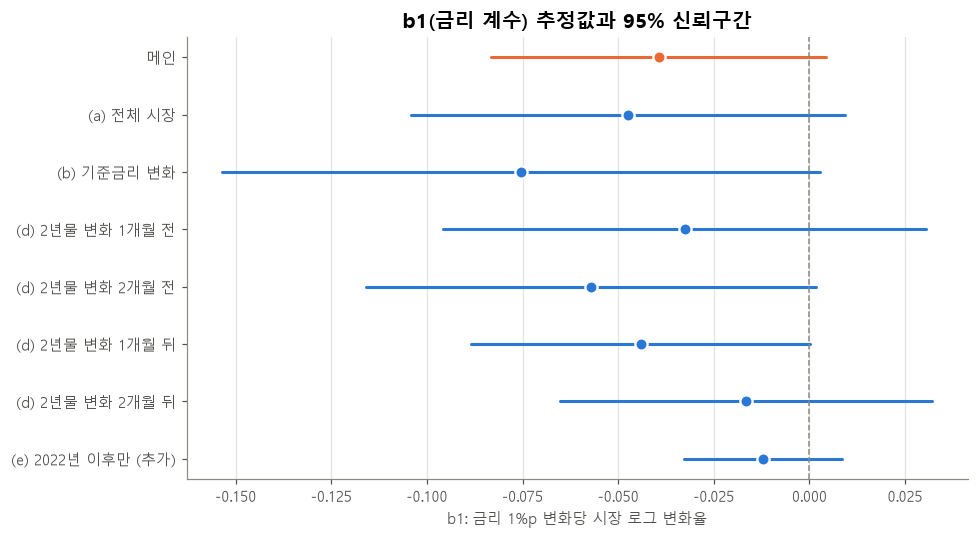

In [14]:
plot_rows = robust.drop(index="(c) 2년물 수준").iloc[::-1]   # 위에서부터 메인이 오도록 뒤집기
y_pos = np.arange(len(plot_rows))
is_main = plot_rows.index == "메인"

fig, ax = plt.subplots(figsize=(9, 5))
for y_i, (name, row) in zip(y_pos, plot_rows.iterrows()):
    color = COLORS[1] if name == "메인" else COLORS[0]
    ax.plot([row["95% 하한"], row["95% 상한"]], [y_i, y_i], color=color, linewidth=2, solid_capstyle="round")
    ax.plot(row["b1"], y_i, "o", color=color, markersize=8, markeredgecolor="white", markeredgewidth=1.5)

ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_rows.index)
ax.grid(axis="y", visible=False)

ax.set_title("b1(금리 계수) 추정값과 95% 신뢰구간")
ax.set_xlabel("b1: 금리 1%p 변화당 시장 로그 변화율")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_b1_robustness.png", dpi=200)
plt.show()

**읽는 법**
- **방향은 모든 검정에서 음수**다. "금리가 오르면 시장이 덜 크고, 내리면 더 큰다"는 방향은 설정을 바꿔도 유지된다.
- **크기는 꽤 흔들린다.** 대략 −0.08 ~ −0.01 사이이고, 대부분 신뢰구간이 0을 살짝 넘는다.
- (a) 전체 시장: 메인과 비슷하다(조금 더 음수). USDC를 빼는 선택이 결론을 바꾸지 않는다.
- (b) 기준금리: 계수가 더 크게 나온다(−0.075). 기준금리는 연준이 결정할 때만 움직여서 의미 있게 변한 달이 약 35%뿐이다(2년물은 약 68%). 두 금리의 월간 변화끼리 상관도 약 0.2로 낮다. 2년물이 기대를 먼저 반영하고 기준금리는 나중에 따라가기 때문이다. 그래서 두 계수의 크기를 그대로 비교하기는 어렵고, **방향이 같다**는 것이 핵심이다.
- (c) 수준: 유일하게 뚜렷이 유의하고 R²도 크다. 하지만 이건 "2020~21년 금리가 0이던 때 = 시장 급성장기"라는 **한 시기**가 만든 결과일 가능성이 크다. 금리가 낮았던 것 말고도 그때는 코인 붐이었다.
- (d) 시차: 2개월 전 변화(−0.057)와 1개월 뒤 변화(−0.044)도 같은 방향이다. 효과가 한 달에 몰리지 않고 **몇 달에 걸쳐 나타날** 수 있다는 신호다. 2개월 뒤는 거의 0이다.
- **(e) 2022년 이후만 쓰면 b1이 약 −0.012로 작아진다.** 메인 추정값의 상당 부분이 "급성장기가 끝나고 금리 인상이 시작된 2022년 초" 전환기에서 나온다는 뜻이다. 최근 시장에서는 관계가 더 약할 수 있다.

## 8. 잔차 확인: 이상한 달이 있나?

### 잔차 그래프
이 셀이 하는 일: 메인 회귀의 잔차(실제 − 예측)를 월별 막대로 그린다. 점선은 ±2 표준편차다. 이 선을 넘는 달은 **식이 설명하지 못한 큰 움직임**이 있었던 달이라 이름을 붙인다.

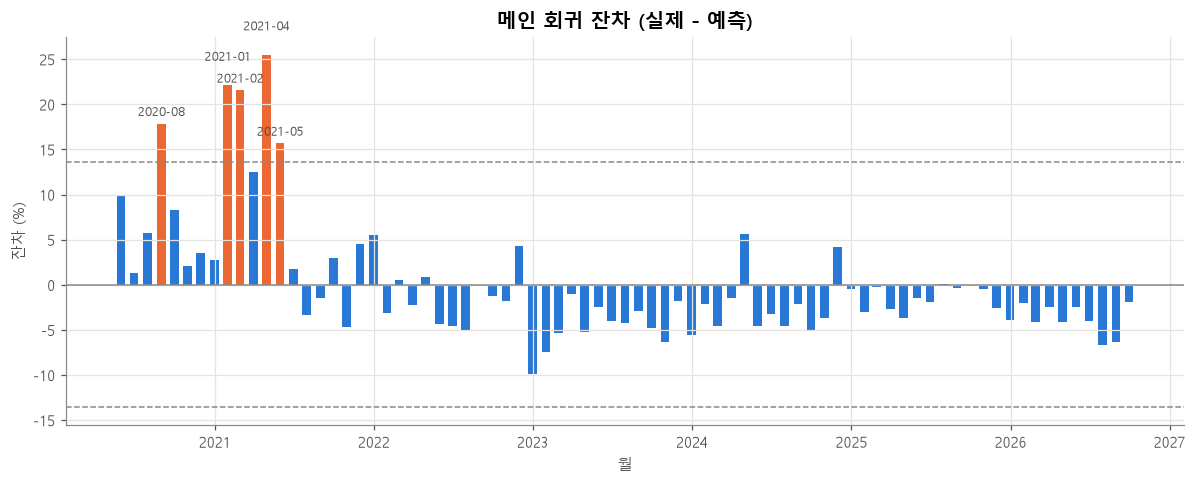

In [15]:
resid = main.resid * 100                 # % 단위로
resid_sd = resid.std()
outlier = resid.abs() > 2 * resid_sd

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(resid.index, resid.values, width=20,
       color=[COLORS[1] if o else COLORS[0] for o in outlier])
for sign in (1, -1):
    ax.axhline(sign * 2 * resid_sd, color=MUTED, linestyle="--", linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
for i, (date, value) in enumerate(resid[outlier].items()):
    ax.annotate(f"{date:%Y-%m}", (date, value), xytext=(0, 5 + 11 * (i % 2)),   # 이웃 이름이 겹치지 않게 높이 번갈아
                textcoords="offset points", ha="center", fontsize=8, color=TEXT_SUB)

ax.set_title("메인 회귀 잔차 (실제 - 예측)")
ax.set_xlabel("월")
ax.set_ylabel("잔차 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "3_residuals.png", dpi=200)
plt.show()

### 큰 잔차가 나온 달
이 셀이 하는 일: ±2 표준편차를 넘은 달의 실제 값, 예측 값, 잔차, 그리고 그달의 금리·비트코인 변화를 표로 본다.

In [16]:
outlier_table = pd.DataFrame({
    "실제(%)":        data.loc[outlier.index, "y_ex_usdc"] * 100,
    "예측(%)":        main.fittedvalues * 100,
    "잔차(%)":        resid,
    "2년물 변화(%p)":  data["d_dgs2"],
    "비트코인 변화(%)": data["d_log_btc"] * 100,
}).loc[outlier]
outlier_table

,실제(%),예측(%),잔차(%),2년물 변화(%p),비트코인 변화(%)
date,,,,,
2020-08-31,22.6659,4.8060,17.8600,-0.0106,2.5452
2021-01-31,28.0869,5.9685,22.1184,-0.0048,13.0585
2021-02-28,29.6630,8.0982,21.5648,-0.0157,31.5650
2021-04-30,29.6703,4.1746,25.4957,0.0179,-2.0563
2021-05-31,15.2396,-0.4349,15.6745,-0.0101,-43.9156


**읽는 법**
- 큰 잔차는 **모두 2020~21년**이고 모두 **양수**다. 식이 예측한 것보다 시장이 훨씬 빨리 컸다는 뜻이다. 그때는 금리가 0에 고정돼 있었으므로 금리로는 설명이 안 되고, 비트코인 변화만으로도 다 설명이 안 되는 **스테이블코인 급성장기**였다.
- 2022년 이후에는 ±2 표준편차를 넘는 달이 없다. 이벤트 더미가 큰 충격을 잘 흡수하고 있다.
- 대신 **2023년 이후 잔차가 대부분 음수**다. 식이 최근 달들을 **계속 과대 예측**한다는 뜻이다. 급성장기 때문에 상수 a(월 약 4.5%)가 커졌고, 최근 시장에는 너무 높은 기본 성장률이 깔려 있는 것이다. a는 **연 70%에 가까운 성장률이라 시뮬레이션에 그대로 쓰면 안 된다.** 6단계에서는 최근 기간의 성장률을 따로 정해야 한다.
- 이 패턴은 2020~21년과 그 이후의 **성격이 다르다**는 신호이기도 하다. 7번의 (e) 2022년 이후 추정이 메인과 다르게 나온 것과 같은 이야기다.
- 잔차가 몇 달씩 같은 방향(양수)으로 이어진 것이 5번에서 본 **자기상관**의 정체다.

## 9. 시뮬레이션용 시나리오 제안

b1의 방향(음수)과 범위(신뢰구간 약 −0.083 ~ +0.004)를 근거로 세 가지 시나리오를 둔다.

| 시나리오 | b1 | 의미 | 근거 |
|---|---|---|---|
| ① **보수** | 0 | 금리가 내려도 R은 금리와 상관없이 움직인다 | 신뢰구간이 0을 포함한다. 상한(+0.004)도 사실상 0이다. 2022년 이후 추정(−0.012)도 0에 가깝다 |
| ② **기본** | −0.039 | 2년물 1%p 하락 → 시장 약 +4% | 메인 회귀 추정값 |
| ③ **낙관** | −0.083 | 2년물 1%p 하락 → 시장 약 +9% | 95% 하한. 금리와 R의 반대 움직임이 가장 강한 경우 |

**왜 이 세 개인가?** 신뢰구간의 위쪽 끝은 0과 거의 같아서 ①이 그 역할을 겸한다. 그래서 세 시나리오가 **신뢰구간 전체를 덮는다.**

### 발행사 입장에서 무슨 차이인가
이 셀이 하는 일: "앞으로 3년간 2년물이 2%p 내리고, 준비금 수익률도 4% → 2%로 내린다"는 예시에서, 시나리오별로 시장(R)과 이익(r × R)이 얼마나 변하는지 계산한다.
- USDC 점유율은 그대로라고 가정한다(R의 변화율 = 시장 변화율).
- 간단한 예시라서 고정비 C와 다른 요인(비트코인, 추세)은 빼고 **금리 효과만** 본다.

In [17]:
SCENARIOS = {"① 보수": 0.0, "② 기본": b1, "③ 낙관": b1_low}
DGS2_CHANGE = -2.0             # 3년간 2년물 누적 변화 (%p)
R_YIELD_OLD, R_YIELD_NEW = 4.0, 2.0   # 준비금 수익률 (%)

scenario_rows = {}
for name, b in SCENARIOS.items():
    market_ratio = np.exp(b * DGS2_CHANGE)                       # 시장(R)이 몇 배가 되나
    profit_ratio = (R_YIELD_NEW / R_YIELD_OLD) * market_ratio    # 이익(r × R)이 몇 배가 되나
    scenario_rows[name] = {
        "b1":                 b,
        "R 변화(%)":           (market_ratio - 1) * 100,
        "이자수익 r×R 변화(%)":  (profit_ratio - 1) * 100,
        "R이 메워 준 몫(%p)":    (profit_ratio - R_YIELD_NEW / R_YIELD_OLD) * 100,
    }
pd.DataFrame(scenario_rows).T

,b1,R 변화(%),이자수익 r×R 변화(%),R이 메워 준 몫(%p)
① 보수,0.0000,0.0000,-50.0000,0.0000
② 기본,-0.0394,8.2063,-45.8968,4.1032
③ 낙관,-0.0831,18.0877,-40.9562,9.0438


**읽는 법**
- 금리가 반으로 줄면 이자수익은 R이 그대로일 때 **−50%**다(①).
- R이 금리 반대로 움직여도(②, ③) 메워 주는 몫은 **약 4~9%p**에 그친다. 이자수익은 여전히 **−41 ~ −46%** 줄어든다.
- 즉 **"금리가 내리면 발행량이 늘어 자연스럽게 헤지된다"는 효과는 있더라도 작다.** 금리 하락 위험을 막으려면 여전히 플로어가 필요하다. 이건 세 시나리오 모두에서 같은 결론이다.

### 정리와 다음 단계를 위한 메모
- **최적 정책은 ① 보수(b1 = 0)로 정한다.** 손실확률 기준에서는 자연 헤지를 기대하지 않는 쪽이 가장 보수적이다. 통계적으로도 배제되지 않고, 최근 기간 추정과도 가깝다. ② 기본과 ③ 낙관은 "자연 헤지가 있다면 플로어를 얼마나 덜 사도 되나"를 보는 민감도 분석으로 쓴다.
- **b1은 '그 달' 효과다.** 시뮬레이션에서는 매달 Δlog(R) = b1 × Δ(2년물)을 더해 가면 된다. 시차 검정에서 앞뒤 달에도 같은 방향의 효과가 보였으므로, 누적 효과는 이보다 조금 클 수 있다.
- **시뮬레이션의 금리 모형은 단기금리를 만든다.** 2년물 변화는 금리 모형(Vasicek·Hull-White)에서 단기금리로부터 계산할 수 있다(2년물 ≈ 단기금리의 함수).
- **상수 a(월 4.5%)는 쓰지 않는다.** 2020~21년 급성장기의 흔적이라 미래 추세로 쓰기에는 너무 크다.
- **USDC 점유율은 고정으로 가정했다.** SVB 같은 USDC 고유 충격은 점유율을 통해 R을 따로 흔들 수 있으므로, 시뮬레이션에서 별도 위험 요인으로 둘지 정해야 한다.

## 10. 자연 헤지 크기 (3년 경로 기준)

9번 계산은 "3년 뒤 한 시점"만 봤다. 실제 발행사의 이익은 3년 동안 **매달 쌓이는** 이자수익의 합이다. 그래서 금리가 서서히 내려가는 경로를 따라 3년 총 이자수익을 계산한다.

**가정**
- 3년(36개월) 동안 2년물이 **매달 같은 폭으로** 총 2%p 내린다.
- 준비금 수익률도 매달 같은 폭으로 **4% → 2%** 내린다.
- 시장(=R)은 매달 b1 × Δ(2년물)만큼 변한다. 금리 효과만 보려고 성장률 g와 고유 충격은 뺀다.
- 처음 R = 100 (단위는 상관없음). 이번 달 이자수익 = R × 이번 달 금리 ÷ 12

**비교 기준**: 금리가 3년 내내 4%이고 R도 100 그대로라면 3년 총 이자수익은 100 × 4% × 3 = **12**다.

이 셀이 하는 일: 세 b1 시나리오별로 3년 뒤 시장 증가율과 3년 총 이자수익(및 기준 대비 변화)을 계산한다.

In [18]:
MONTHS = 36
dgs2_path = np.linspace(0, -2.0, MONTHS + 1)[1:]        # 2년물 누적 변화: 매달 −2/36 %p씩
rate_path = np.linspace(4.0, 2.0, MONTHS + 1)[1:]       # 준비금 수익률: 4% → 2%
R0 = 100
BASE_TOTAL = R0 * 0.04 * 3                               # 금리 4% 유지 시 3년 총 이자수익 = 12

hedge_rows = {}
for name, b in SCENARIOS.items():
    R_path = R0 * np.exp(b * dgs2_path)                  # 매달 R
    income_total = np.sum(R_path * rate_path / 100 / 12)  # 3년 총 이자수익
    hedge_rows[name] = {
        "b1":                     b,
        "3년 뒤 시장 증가율(%)":      (R_path[-1] / R0 - 1) * 100,
        "3년 총 이자수익":            income_total,
        "금리 4% 유지 대비 변화(%)":   (income_total / BASE_TOTAL - 1) * 100,
    }
hedge = pd.DataFrame(hedge_rows).T
hedge["보수 대비 더 번 몫(%p)"] = hedge["금리 4% 유지 대비 변화(%)"] - hedge.loc["① 보수", "금리 4% 유지 대비 변화(%)"]
hedge

,b1,3년 뒤 시장 증가율(%),3년 총 이자수익,금리 4% 유지 대비 변화(%),보수 대비 더 번 몫(%p)
① 보수,0.0000,0.0000,8.9167,-25.6944,0.0000
② 기본,-0.0394,8.2063,9.2468,-22.9429,2.7515
③ 낙관,-0.0831,18.0877,9.6326,-19.7282,5.9663


**읽는 법**
- ① 보수: R이 그대로라서 금리 하락이 고스란히 이자수익 감소로 이어진다. 3년 총 이자수익이 12 → 약 8.9로, 기준 대비 약 **−26%**다.
- ② 기본, ③ 낙관: R이 3년 뒤 각각 약 +8%, +18% 커진다. 하지만 R은 **천천히** 늘고 금리는 처음부터 내리기 때문에, 3년 합계로 메워 주는 몫은 보수 대비 약 **+2.8%p, +6.0%p**에 그친다. 3년 뒤 한 시점만 본 9번 계산(4%p, 9%p)보다도 작다.
- **결론**: 자연 헤지는 있어도 이자수익 감소의 일부만 메운다. 9번의 한 시점 계산과 같은 결론이다.

---

# 3단계: 금리 모형 (Vasicek)

*원본 파일: `notebooks/03_rate_model.ipynb`*

# 03. 금리 모형 (Vasicek)

**목표:** 앞으로 3년 동안 금리가 어떻게 움직일 수 있는지, **수천 개의 가능한 경로**를 만드는 모형을 세운다. 이 경로들이 6단계 몬테카를로 시뮬레이션의 재료가 된다.
- 이번 노트북의 모형은 "실제로 일어날 법한" 금리 경로를 만드는 **시나리오 생성용**이다. 플로어 **가격**을 매기는 모형은 다음 단계에서 따로 다룬다.

## Vasicek 모형이란

$$dr = a\,(b - r)\,dt + \sigma\,dW$$

말로 풀면: **금리의 변화 = (평균으로 끌려가는 힘) + (무작위 흔들림)**

| 기호 | 이름 | 직관 |
|---|---|---|
| **b** | 장기 평균 | 금리가 오래 지나면 돌아가려는 **기준점** (%) |
| **a** | 평균회귀 속도 | 기준점으로 끌려가는 **힘의 세기**. 고무줄이 얼마나 팽팽한지 |
| **σ** | 변동성 | 매 순간 생기는 **무작위 흔들림**의 크기 (%p / √년) |

- 금리가 b보다 높으면 a(b − r) < 0이라 아래로 끌리고, 낮으면 위로 끌린다.
- dW는 "동전 던지기" 같은 무작위 충격이다. σ가 클수록 경로가 더 들쭉날쭉하다.

## 1. 준비

### 라이브러리와 경로
이 셀이 하는 일: 도구를 불러오고, 폴더 경로와 그래프 설정을 한다.

In [1]:
import sys
import inspect   # 함수의 코드를 화면에 출력하는 도구
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm   # 정규분포 계산용

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

### 금리 모형 함수 불러오기
이 셀이 하는 일: `src/rate_model.py`에 만들어 둔 추정·시뮬레이션 함수를 불러오고, **코드를 그대로 출력**해서 무엇을 하는지 본다.
- 이 함수들은 다음 단계(플로어 가격, 몬테카를로)에서도 계속 쓰기 때문에 `src/`에 따로 두었다.

In [2]:
from src.rate_model import fit_vasicek, sigma_from_resid, bond_B, simulate_vasicek, DT

print(inspect.getsource(fit_vasicek))
print(inspect.getsource(simulate_vasicek))

def fit_vasicek(r, dt=DT):
    """월간 금리 r(%, pandas Series)로 Vasicek 파라미터를 추정한다.

    r(t+1) = c + φ·r(t) + e 를 회귀(AR(1))한 뒤 Vasicek 파라미터로 바꾼다.
      a = −ln(φ) / dt,  b = c / (1 − φ),  σ = sd(e) · √(2a / (1 − φ²))
    반환: (파라미터 딕셔너리, 잔차 Series)
    """
    y = r.iloc[1:].to_numpy()    # 다음 달 금리
    x = r.iloc[:-1].to_numpy()   # 이번 달 금리
    res = sm.OLS(y, sm.add_constant(x)).fit()
    c, phi = res.params
    if not 0 < phi < 1:
        raise ValueError(f"φ = {phi:.4f}: 평균회귀가 없어 Vasicek으로 바꿀 수 없음")

    a = -np.log(phi) / dt
    b = c / (1 - phi)
    resid = pd.Series(res.resid, index=r.index[1:])
    sigma = sigma_from_resid(resid, a, phi)
    params = {
        "phi": phi, "a": a, "b": b, "sigma": sigma,
        "half_life_months": np.log(2) / a * 12,   # 평균과의 거리가 절반으로 줄어드는 데 걸리는 개월 수
        "n": len(y), "start": r.index[0].date(), "end": r.index[-1].date(),
    }
    return params, resid

def simulate_vasicek(r0, a, b, sigma, months=36, n_paths=1000, seed=42, dt=DT):
    """r0(%)에

## 2. 데이터: 월간 기준금리
이 셀이 하는 일: 01번에서 만든 일별 기준금리(2018년 4월부터 SOFR, 그 전은 DFF)를 **월평균**으로 바꾼다. 2026년 10월은 아직 다 끝나지 않은 달이라 9월까지만 쓴다.

**왜 월말 값이 아니라 월평균인가?**
- SOFR는 **월말에 튀는** 경향이 있다(01번 노트북 1-6에서 확인). 월말 하루 값을 쓰면 이 튐이 "금리 변동"으로 잘못 잡혀 σ가 부풀려진다. (4번에서 실제로 비교한다)
- 02번 회귀에서도 금리는 월평균을 썼다. 같은 기준을 맞추는 의미도 있다.

In [3]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")

monthly_avg = rates["base_rate"].resample("ME").mean().loc[:"2026-09-30"]   # 월평균
monthly_end = rates["base_rate"].resample("ME").last().loc[:"2026-09-30"]   # 비교용: 월말 값

print("월간 기준금리:", monthly_avg.index[0].date(), "~", monthly_avg.index[-1].date(), f"({len(monthly_avg)}개월)")
monthly_avg.tail(3)

월간 기준금리: 2000-01-31 ~ 2026-09-30 (321개월)


date
2026-07-31   3.6200
2026-08-31   3.6419
2026-09-30   3.7464
Freq: ME, Name: base_rate, dtype: float64

## 3. AR(1) 회귀로 Vasicek 추정하기

Vasicek 모형을 한 달 간격으로 보면 아래 모양이 된다. "다음 달 금리를 이번 달 금리로 설명하는" 단순 회귀다. 이것을 **AR(1)**(1차 자기회귀: 자기 자신의 바로 전 값으로 설명)이라고 한다.

$$r_{t+1} = c + \varphi \, r_t + e_{t+1}$$

회귀로 c, φ, 잔차 e의 표준편차를 구하면 Vasicek 파라미터로 바꿀 수 있다.

| Vasicek | 계산식 | 직관 |
|---|---|---|
| a | −ln(φ) ÷ (1/12) | φ가 1에 가까울수록(금리가 지난달과 비슷할수록) a가 작다 = 천천히 돌아간다 |
| b | c ÷ (1 − φ) | 금리가 더 이상 안 변하는 지점 (r = c + φr 을 풀면 나옴) |
| σ | sd(e) × √(2a ÷ (1 − φ²)) | 매달 예상 밖 변화의 크기를 '연 단위'로 바꾼 것 |

- **반감기** = ln(2) ÷ a: 금리가 평균에서 벗어났을 때, 그 거리가 **절반으로 줄어드는 데 걸리는 시간**.

## 4. 추정: 메인(2000년~)과 민감도(2008년~)
이 셀이 하는 일: 두 기간으로 추정하고, 참고로 **월말 값**으로 추정한 결과도 함께 표로 비교한다.

In [4]:
fits = {
    "메인 (2000~, 월평균)":    fit_vasicek(monthly_avg.loc["2000":]),
    "민감도 (2008~, 월평균)":  fit_vasicek(monthly_avg.loc["2008":]),
    "참고 (2000~, 월말 값)":   fit_vasicek(monthly_end.loc["2000":]),
}

param_table = pd.DataFrame({name: p for name, (p, resid) in fits.items()}).T
param_table = param_table[["start", "end", "n", "phi", "a", "half_life_months", "b", "sigma"]]
param_table.columns = ["시작", "끝", "관측치", "φ", "a (평균회귀 속도)", "반감기(개월)", "b (장기 평균, %)", "σ (변동성)"]
param_table

,시작,끝,관측치,φ,a (평균회귀 속도),반감기(개월),"b (장기 평균, %)",σ (변동성)
"메인 (2000~, 월평균)",2000-01-31,2026-09-30,320,0.9923,0.0930,89.4674,1.3155,0.6366
"민감도 (2008~, 월평균)",2008-01-31,2026-09-30,224,0.9945,0.0666,124.9385,1.3272,0.6164
"참고 (2000~, 월말 값)",2000-01-31,2026-09-30,320,0.9875,0.1509,55.1127,1.5752,0.9211


**파라미터 읽는 법 (메인 기준)**
- **φ ≈ 0.992**: 이번 달 금리가 다음 달 금리를 거의 그대로 결정한다. 금리는 매우 '끈적한' 변수다.
- **a ≈ 0.09, 반감기 ≈ 89개월(약 7.5년)**: 금리가 장기 평균보다 2%p 높으면, 무작위 충격이 없다고 할 때 약 7.5년 뒤에 1%p 차이로 줄어든다. 평균으로 돌아가는 힘이 **약하다.** 3년 안에는 거리의 약 25%만 줄어든다.
- **b ≈ 1.3%**: 2000년 이후 금리가 돌아가려는 기준점. 낮아 보이는 이유는 **제로금리 기간이 약 9년**(2008~15년, 2020~22년)이나 되기 때문이다.
- **σ ≈ 0.64**: 무작위 흔들림만으로 1년에 약 ±0.64%p(1 표준편차), 한 달로 치면 약 ±0.18%p 움직인다.

**민감도 (2008년~)**: a가 더 작고(반감기 약 10년), b는 거의 같다(1.3%). 2008년 이후는 제로금리 비중이 더 커서 "평균으로 돌아가는 힘"이 더 약하게 잡힌다.

**참고 (월말 값)**: σ가 약 0.92로 월평균보다 **약 45% 크다.** 월말에 튀는 SOFR가 변동성으로 잘못 잡힌 결과다. 그래서 월평균을 쓴다.

> **주의:** φ가 1에 아주 가까울 때 AR(1) 추정은 a를 **크게(평균회귀를 빠르게)** 잡는 경향이 알려져 있다. 실제 평균회귀는 이보다 더 느릴 수 있다.

## 5. 최근 3년 변동성
이 셀이 하는 일: a와 b는 메인 추정값을 그대로 두고, **최근 36개월 잔차만으로** σ를 다시 계산한다.
- 장기와 최근 중 무엇을 쓸지에 따라 경로의 퍼짐이 달라진다.

In [5]:
main_p, main_resid = fits["메인 (2000~, 월평균)"]
recent_resid = main_resid.iloc[-36:]
sigma_recent = sigma_from_resid(recent_resid, main_p["a"], main_p["phi"])

pd.DataFrame({
    "기간":      [f"{main_resid.index[0]:%Y-%m} ~ {main_resid.index[-1]:%Y-%m}",
                 f"{recent_resid.index[0]:%Y-%m} ~ {recent_resid.index[-1]:%Y-%m}"],
    "σ":        [main_p["sigma"], sigma_recent],
    "한 달 흔들림(%p, 1σ)": [main_p["sigma"] * np.sqrt(DT), sigma_recent * np.sqrt(DT)],
}, index=["장기 (메인)", "최근 3년"])

,기간,σ,"한 달 흔들림(%p, 1σ)"
장기 (메인),2000-02 ~ 2026-09,0.6366,0.1838
최근 3년,2023-10 ~ 2026-09,0.3154,0.0910


**읽는 법**
- 최근 3년 σ(약 0.32)는 장기 σ(약 0.64)의 **절반**이다. 최근 3년에는 2008년이나 2020년 같은 급격한 인하가 없었기 때문이다.
- 최근 σ를 쓰면 **급락 위험이 작게** 잡힌다. 플로어는 바로 그 급락을 막는 도구다.

**결정: 기본은 장기 σ ≈ 0.64, 민감도는 최근 3년 σ ≈ 0.32.** 시나리오와 플로어 가격 계산에 **같은 σ**를 쓴다. σ가 다르면 플로어가 인위적으로 싸거나 비싸 보이기 때문이다.

## 5-2. 장기 평균 b: FOMC 전망

추정된 b ≈ 1.3%는 제로금리 약 9년에 끌려 내려간 값이다. 이 값을 쓰면 모든 경로가 아래로 끌려가서, 시장 선도금리(지금은 SOFR보다 높음)와 크게 어긋난다.

**결정: 기본 b = FOMC 장기 정책금리 전망 중위값, 스트레스 b = 과거 추정치 1.32%.** a와 σ는 추정값을 그대로 쓴다.
- **FOMC 장기 정책금리 전망**: 연준 위원들이 분기마다 "충격이 없을 때 장기적으로 적정한 기준금리"를 적어 내는 값(점도표)의 중위값이다. FRED 시리즈 `FEDTARMDLR`.

이 셀이 하는 일: FRED에서 `FEDTARMDLR`을 받아(`data/raw/fred/`) 최근 값들을 보여주고, 가장 최근 값을 기본 b로 정한다.
- 01번 노트북의 다운로드 함수와 같은 것을 `src/fred.py`에 두고 불러 쓴다.

In [6]:
from src.fred import download_fred, read_fred

download_fred("FEDTARMDLR")          # 이미 받은 파일이 있으면 건너뜀
fomc = read_fred("FEDTARMDLR").dropna()

b_fomc, b_fomc_date = fomc.iloc[-1], fomc.index[-1]
b_stress = main_p["b"]
print(f"기본 b (FOMC 장기 전망, {b_fomc_date:%Y-%m-%d} 발표) = {b_fomc:.2f}%")
print(f"스트레스 b (2000~ 과거 추정) = {b_stress:.2f}%")
fomc.tail(8).to_frame("FOMC 장기 전망 중위값(%)")

FEDTARMDLR 이미 받은 파일이 있어 건너뜀
기본 b (FOMC 장기 전망, 2026-09-16 발표) = 3.20%
스트레스 b (2000~ 과거 추정) = 1.32%


,FOMC 장기 전망 중위값(%)
observation_date,
2024-12-18,3.0000
2025-03-19,3.0000
2025-06-18,3.0000
2025-09-17,3.0000
2025-12-10,3.0000
2026-03-18,3.1000
2026-06-17,3.1000
2026-09-16,3.2000


## 6. 검증: 모형의 2년물 민감도 vs 실제 데이터

Vasicek 모형에서 2년물 금리는 단기금리 r의 함수다.

$$y_{2Y} = \frac{-\ln A(2) + B(2)\,r}{2}, \qquad B(\tau) = \frac{1 - e^{-a\tau}}{a}$$

따라서 **단기금리가 1%p 변하면 2년물은 B(2)/2 %p 변한다.** 이 값을 실제 데이터의 "Δ2년물을 ΔSOFR로 회귀한 기울기"와 비교한다.
- 이 값이 맞아야, 3단계 발행량 모형(Δ2년물 → 시장 변화)에 금리 모형을 연결할 수 있다.

### 모형 값
이 셀이 하는 일: 메인·민감도 추정의 a로 B(2)/2를 계산한다.

In [7]:
model_slope = {name: bond_B(2, p["a"]) / 2 for name, (p, _) in fits.items() if "월평균" in name}
pd.Series(model_slope, name="모형 B(2)/2").to_frame()

,모형 B(2)/2
"메인 (2000~, 월평균)",0.9125
"민감도 (2008~, 월평균)",0.9363


### 데이터 기울기
이 셀이 하는 일: SOFR가 있는 기간(2018-05 ~ 2026-09)의 월평균 데이터로 Δ2년물 = α + β·ΔSOFR 회귀를 돌린다. 변화 간격을 1개월, 3개월, 12개월로 바꿔 본다.
- 3개월·12개월은 기간이 겹치지 않게 3개월·12개월마다 하나씩만 쓴다. 그래서 관측치가 적다.
- 표준오차는 02번처럼 Newey-West로 계산한다.

In [8]:
sofr_2y = rates[["SOFR", "DGS2"]].resample("ME").mean().loc["2018-05":"2026-09"]

slope_rows = {}
for k in [1, 3, 12]:
    changes = sofr_2y.diff(k).dropna().iloc[::k]    # k개월 변화, 겹치지 않게
    res = sm.OLS(changes["DGS2"], sm.add_constant(changes["SOFR"])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    lo, hi = res.conf_int().loc["SOFR"]
    slope_rows[f"{k}개월 변화"] = {"데이터 기울기 β": res.params["SOFR"], "95% 하한": lo, "95% 상한": hi,
                                "관측치": int(res.nobs), "R²": res.rsquared}
slope_table = pd.DataFrame(slope_rows).T
slope_table["모형 B(2)/2 (메인)"] = model_slope["메인 (2000~, 월평균)"]
slope_table

,데이터 기울기 β,95% 하한,95% 상한,관측치,R²,모형 B(2)/2 (메인)
1개월 변화,0.4461,0.2034,0.6888,100.0000,0.1665,0.9125
3개월 변화,0.5587,0.3801,0.7372,33.0000,0.3446,0.9125
12개월 변화,0.5178,0.3068,0.7289,8.0000,0.5148,0.9125


**읽는 법**
- 모형은 "SOFR가 1%p 움직이면 2년물이 약 **0.91%p**" 움직인다고 본다. 실제 데이터는 약 **0.45~0.56%p**다. 모형이 2년물 반응을 **약 2배 크게** 본다. 신뢰구간도 0.91에 닿지 않는다.
- 이유
  1. **기대 선행**: 2년물은 앞으로의 금리 변화를 미리 반영한다. 그래서 SOFR가 실제로 움직이는 달에는 이미 상당 부분 움직인 뒤다. 1요인 모형은 이를 담지 못한다(CLAUDE.md에 적어 둔 한계).
  2. 평균회귀가 약하게 추정돼서(a 작음) B(2)/2가 1에 가깝게 나온다. 실제 시장은 "지금 금리 변화가 오래가지 않는다"고 더 강하게 보는 셈이다.
- **3단계와 연결할 때의 의미**: b1 = 0(보수) 시나리오에는 영향이 없다. b1 ≠ 0(기본·낙관)에서 모형 공식을 그대로 쓰면 2년물 변화가 실제보다 크게 잡혀 **자연 헤지를 약 2배 과대평가**하게 된다.

**결정: Δ2년물 = 0.5 × Δ단기금리 (데이터 기울기)를 쓴다.** 모형 공식(0.91)과 어긋나는 점은 1요인 모형의 한계로 기록한다.

## 7. 시험 시뮬레이션

### 경로 만들기
이 셀이 하는 일: **현재 SOFR**에서 시작해 **기본 설정**(a = 메인 추정, b = FOMC 장기 전망, σ = 장기 0.64)으로 3년(36개월) 금리 경로 1,000개를 만든다.
- 매달: 다음 달 금리 = 장기 평균 쪽으로 조금 이동 + 무작위 충격
- `seed=42`: 무작위 숫자를 매번 똑같이 뽑게 하는 설정. 다시 실행해도 같은 결과가 나온다.

In [9]:
sofr = rates["SOFR"].dropna()
r0, r0_date = sofr.iloc[-1], sofr.index[-1]

paths = simulate_vasicek(r0, main_p["a"], b_fomc, main_p["sigma"], months=36, n_paths=1000, seed=42)
expected_end = b_fomc + (r0 - b_fomc) * np.exp(-main_p["a"] * 3)   # 이론상 3년 뒤 평균

print(f"시작: SOFR {r0:.2f}% ({r0_date:%Y-%m-%d}) | 경로 {paths.shape[0]}개 × {paths.shape[1] - 1}개월")
print(f"3년 뒤 평균: 시뮬레이션 {paths[:, -1].mean():.2f}% / 이론값 {expected_end:.2f}%")

시작: SOFR 3.93% (2026-10-26) | 경로 1000개 × 36개월
3년 뒤 평균: 시뮬레이션 3.80% / 이론값 3.75%


### 경로 그래프
이 셀이 하는 일: 경로 50개를 옅은 선으로, 1,000개 경로의 **가운데 90% 범위**(5~95%)를 음영으로, 중앙값을 진한 선으로 그린다.

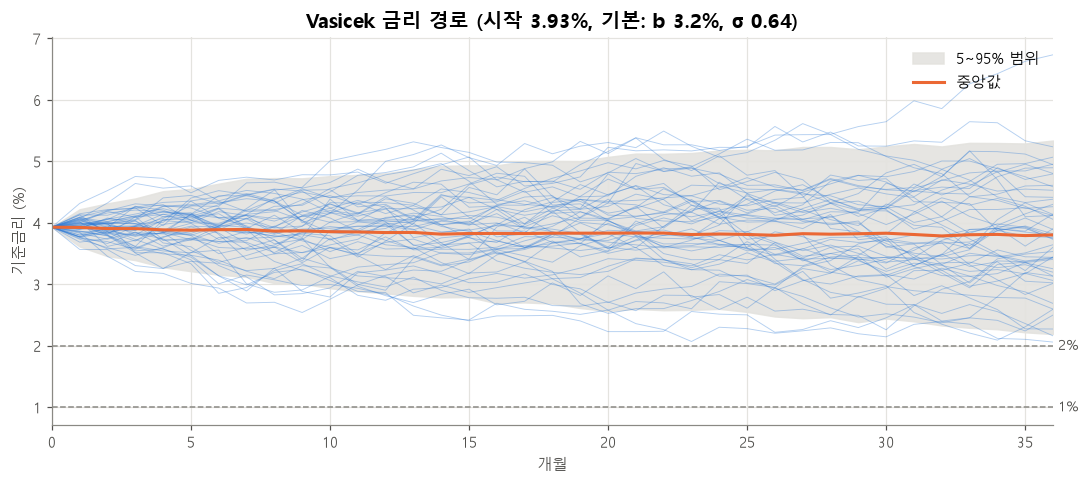

In [10]:
months = np.arange(paths.shape[1])
p5, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(months, p5, p95, color=SHADE, alpha=0.9, label="5~95% 범위")
for path in paths[:50]:
    ax.plot(months, path, color=COLORS[0], linewidth=0.6, alpha=0.35)
ax.plot(months, p50, color=COLORS[1], linewidth=2, label="중앙값")
for level in (2, 1):
    ax.axhline(level, color=MUTED, linestyle="--", linewidth=1)
    ax.text(36, level, f" {level}%", va="center", color=TEXT_SUB, fontsize=9)

ax.set_xlim(0, 36)
ax.set_title(f"Vasicek 금리 경로 (시작 {r0:.2f}%, 기본: b {b_fomc:.1f}%, σ {main_p['sigma']:.2f})")
ax.set_xlabel("개월")
ax.set_ylabel("기준금리 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "4_vasicek_paths.png", dpi=200)
plt.show()

### 3년 뒤 금리 분포
이 셀이 하는 일: 1,000개 경로의 36개월 뒤 금리를 히스토그램으로 그린다.
- **히스토그램**: 값을 구간으로 나눠 각 구간에 몇 개가 들어가는지 막대로 그린 그림.

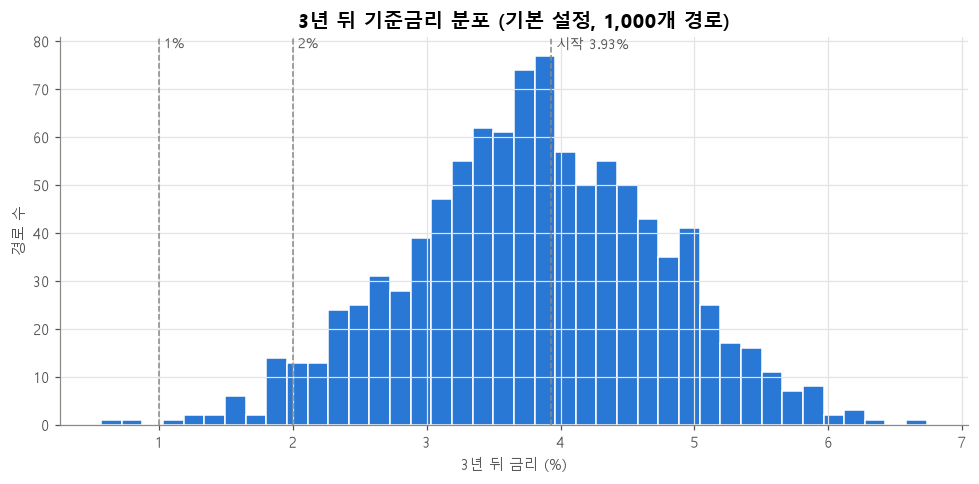

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(paths[:, -1], bins=40, color=COLORS[0], edgecolor="white", linewidth=1)
for level, label in [(r0, f"시작 {r0:.2f}%"), (2, "2%"), (1, "1%")]:
    ax.axvline(level, color=MUTED, linestyle="--", linewidth=1)
    ax.text(level, ax.get_ylim()[1], f" {label}", va="top", color=TEXT_SUB, fontsize=9)

ax.set_title("3년 뒤 기준금리 분포 (기본 설정, 1,000개 경로)")
ax.set_xlabel("3년 뒤 금리 (%)")
ax.set_ylabel("경로 수")
fig.tight_layout()
fig.savefig(FIG_DIR / "4_vasicek_terminal_hist.png", dpi=200)
plt.show()

### 금리가 2%, 1%, 0% 아래로 떨어지는 비율
이 셀이 하는 일: 여러 파라미터 조합으로 각각 1,000개 경로를 만들고 비율을 비교한다. 위 세 줄은 추정 그대로의 조합, 아래 세 줄은 **결정된 설정**(기본·민감도·스트레스)이다.
- 스트레스(b 1.32%, σ 0.64)는 a·b·σ가 "메인 (2000~)"과 같아서 결과도 같다. 비교하기 쉽게 이름을 붙여 따로 둔다.
- **"3년 안에 한 번이라도"**: 경로 중 어느 달이라도 그 아래로 내려간 적이 있는 비율 → 발행사가 한동안 저금리를 겪을 확률
- **"3년 뒤"**: 36개월째 값이 그 아래인 비율

In [12]:
PARAM_SETS = {
    "메인 (2000~)":           (main_p["a"], main_p["b"], main_p["sigma"]),
    "민감도 (2008~)":         (fits["민감도 (2008~, 월평균)"][0]["a"], fits["민감도 (2008~, 월평균)"][0]["b"],
                              fits["민감도 (2008~, 월평균)"][0]["sigma"]),
    "메인 + 최근 3년 σ":       (main_p["a"], main_p["b"], sigma_recent),
    "▶ 기본 (FOMC b, σ 0.64)":       (main_p["a"], b_fomc, main_p["sigma"]),
    "▶ 민감도 (FOMC b, σ 0.32)":      (main_p["a"], b_fomc, sigma_recent),
    "▶ 스트레스 (b 1.32%, σ 0.64)":   (main_p["a"], b_stress, main_p["sigma"]),
}

sim_rows = {}
sims = {}
for name, (a, b, sigma) in PARAM_SETS.items():
    sim = simulate_vasicek(r0, a, b, sigma, months=36, n_paths=1000, seed=42)
    sims[name] = sim
    path_min, end = sim.min(axis=1), sim[:, -1]
    sim_rows[name] = {
        "3년 뒤 5%":          np.percentile(end, 5),
        "3년 뒤 중앙값":        np.median(end),
        "3년 뒤 95%":         np.percentile(end, 95),
        "3년 안 <2% (%)":     (path_min < 2).mean() * 100,
        "3년 안 <1% (%)":     (path_min < 1).mean() * 100,
        "3년 안 <0% (%)":     (path_min < 0).mean() * 100,
        "3년 뒤 <2% (%)":     (end < 2).mean() * 100,
    }
pd.DataFrame(sim_rows).T

,3년 뒤 5%,3년 뒤 중앙값,3년 뒤 95%,3년 안 <2% (%),3년 안 <1% (%),3년 안 <0% (%),3년 뒤 <2% (%)
메인 (2000~),1.7326,3.3453,4.8801,12.4000,1.0000,0.0000,8.4000
민감도 (2008~),1.9007,3.5093,5.0593,9.0000,0.7000,0.0000,6.3000
메인 + 최근 3년 σ,2.5203,3.3192,4.0796,0.5000,0.0000,0.0000,0.3000
"▶ 기본 (FOMC b, σ 0.64)",2.1912,3.8039,5.3388,5.3000,0.3000,0.0000,3.1000
"▶ 민감도 (FOMC b, σ 0.32)",2.9789,3.7779,4.5383,0.0000,0.0000,0.0000,0.0000
"▶ 스트레스 (b 1.32%, σ 0.64)",1.7326,3.3453,4.8801,12.4000,1.0000,0.0000,8.4000


**읽는 법**
- **▶ 기본**(b 3.2%): 3년 뒤 중앙값이 약 3.8%로 시작(3.93%)과 비슷하다. 장기 평균이 시작점에 가까워서 아래로 끌어내리는 힘이 약하다. 3년 안에 한 번이라도 **2% 아래**로 가는 경로는 약 **5%**, **1% 아래**는 약 0.3%다.
- **▶ 스트레스**(b 1.32%): 경로가 1.3% 쪽으로 끌려 내려가서 중앙값이 약 3.3%로 낮아지고, 2% 아래 경로가 약 **12%**로 두 배 이상 많다.
- **▶ 민감도**(σ 0.32): 경로가 좁아져서 3년 안에 2% 아래로 가는 경로가 **하나도 없다.** σ 선택이 저금리 위험의 크기를 b보다 더 크게 좌우한다.

## 8. 음수 금리

### 음수 경로가 있나?
이 셀이 하는 일: 위 조합들에서 0% 아래로 내려간 경로 수를 세고, Vasicek 공식으로 **이론상 확률**도 계산한다.
- Vasicek 모형은 금리가 정규분포를 따라서 **음수가 될 수 있다.** 3년 뒤 금리의 평균과 표준편차를 알면 0 아래일 확률을 바로 계산할 수 있다.

In [13]:
neg_rows = {}
for name, (a, b, sigma) in PARAM_SETS.items():
    mean_3y = b + (r0 - b) * np.exp(-a * 3)
    sd_3y = sigma * np.sqrt((1 - np.exp(-2 * a * 3)) / (2 * a))
    neg_rows[name] = {
        "음수 경로 수 (1,000개 중)": int((sims[name].min(axis=1) < 0).sum()),
        "3년 뒤 평균(%)":          mean_3y,
        "3년 뒤 표준편차(%p)":      sd_3y,
        "이론상 3년 뒤 <0% 확률(%)": norm.cdf(0, mean_3y, sd_3y) * 100,
    }
pd.DataFrame(neg_rows).T

,"음수 경로 수 (1,000개 중)",3년 뒤 평균(%),3년 뒤 표준편차(%p),이론상 3년 뒤 <0% 확률(%)
메인 (2000~),0.0000,3.2937,0.9653,0.0322
민감도 (2008~),0.0000,3.4588,0.9694,0.0180
메인 + 최근 3년 σ,0.0000,3.2937,0.4782,0.0000
"▶ 기본 (FOMC b, σ 0.64)",0.0000,3.7523,0.9653,0.0051
"▶ 민감도 (FOMC b, σ 0.32)",0.0000,3.7523,0.4782,0.0000
"▶ 스트레스 (b 1.32%, σ 0.64)",0.0000,3.2937,0.9653,0.0322


**결과**: 지금 시작점(약 3.9%)과 추정된 파라미터에서는 1,000개 경로 중 음수로 내려가는 경로가 **없거나 극히 드물다.** 이론상 확률도 0.1% 미만이다. 다만 시작 금리가 낮을 때나 σ를 크게 잡는 민감도 분석에서는 생길 수 있으므로 처리 방법을 미리 정해 두는 게 좋다.

**처리 방법 선택지**

| | 방법 | 장점 | 단점 |
|---|---|---|---|
| ① | **그대로 둔다** | 모형이 그대로 유지되고, 다음 단계의 바슐리에 플로어 가격(음수 금리 허용)과 일관된다 | 미국은 마이너스 기준금리를 쓴 적이 없다 |
| ② | **이익 계산에서만 0으로 막는다** (준비금 수익률 = max(r, 0)) | 금리 경로와 플로어 정산은 모형대로 두고, 발행사 수익만 현실적으로 계산한다 | 금리 경로와 수익 계산의 규칙이 달라진다 |
| ③ | **경로 자체를 0에서 자른다** (r = max(r, 0)) | 단순하다 | 평균이 위로 치우치고 다음 달 계산에도 영향을 줘서 모형이 왜곡된다 |
| ④ | **음수가 안 나오는 모형으로 바꾼다** (CIR 등) | 이론적으로 깔끔하다 | 더 복잡하다. 금리가 낮을수록 변동성이 작아지는 성질이 생겨 저금리 위험이 작게 잡힐 수 있다 |

**결정: ②.** 확률이 매우 작아 결과에 주는 영향은 미미하다. 플로어 정산은 모형 금리(음수 포함)로, 준비금 수익은 0 아래로 내려가지 않게 계산하면 둘 다 현실과 맞는다.

## 9. 파라미터 저장
이 셀이 하는 일: 다음 단계에서 쓸 수 있게 파라미터와 시작 금리를 `data/processed/vasicek_params.csv`로 저장한다.

In [14]:
save = pd.DataFrame({name: {"a": a, "b": b, "sigma": sigma} for name, (a, b, sigma) in PARAM_SETS.items()}).T
save["r0"] = r0
save["r0_date"] = r0_date.date()
save.index.name = "param_set"
save.to_csv(PROC_DIR / "vasicek_params.csv")
save

,a,b,sigma,r0,r0_date
param_set,,,,,
메인 (2000~),0.0930,1.3155,0.6366,3.9300,2026-10-26
민감도 (2008~),0.0666,1.3272,0.6164,3.9300,2026-10-26
메인 + 최근 3년 σ,0.0930,1.3155,0.3154,3.9300,2026-10-26
"▶ 기본 (FOMC b, σ 0.64)",0.0930,3.2000,0.6366,3.9300,2026-10-26
"▶ 민감도 (FOMC b, σ 0.32)",0.0930,3.2000,0.3154,3.9300,2026-10-26
"▶ 스트레스 (b 1.32%, σ 0.64)",0.0930,1.3155,0.6366,3.9300,2026-10-26


## 10. 정리: 결정된 설정

| 항목 | 기본 | 민감도·스트레스 |
|---|---|---|
| a | 0.093 (2000~ 추정, 반감기 약 7.5년) | — |
| b | FOMC 장기 전망 중위값 3.2% (2026-09-16 발표) | 스트레스: 1.32% (과거 추정) |
| σ | 0.64 (장기) — 시나리오·플로어 가격 공통 | 민감도: 0.32 (최근 3년) |
| 시작 금리 | SOFR 3.93% (2026-10-26) | — |
| 2년물 연결 | Δ2년물 = 0.5 × Δ단기금리 (데이터 기울기) | 모형 공식 0.91과 어긋남 = 한계 |
| 음수 금리 | 경로·정산은 그대로, 이자수익만 max(r, 0) | — |

**설정별 저금리 위험 (3년 안에 한 번이라도)**

| | 2% 아래 | 1% 아래 |
|---|---|---|
| 기본 | 약 5% | 약 0.3% |
| 스트레스 | 약 12% | 약 1% |
| 민감도 (σ 0.32) | 0% | 0% |

**남은 한계**
- 기본 b(3.2%)는 시작 금리(3.93%)보다 낮아서, 시나리오는 여전히 **완만한 하락**을 예상한다. 반면 시장 수익률곡선은 2년물(4.68%)이 SOFR보다 높아 **상승**을 반영한다. 다음 단계에서 플로어 가격은 시장 선도금리로 매기므로, 이 차이가 "시나리오상 손실 위험 vs 시장 가격"의 차이로 나타난다.
- 1요인 Vasicek이라 기대 선행·기간 프리미엄을 담지 못한다.

---

# 4단계: 플로어 가격 산출 (바슐리에)

*원본 파일: `notebooks/04_floor_pricing.ipynb`*

# 04. 플로어 가격 계산

**목표:** 지금 시장 금리 기준으로, 발행사가 금리 플로어를 사려면 **얼마를 내야 하는지** 가격표를 만든다.

## 플로어란
- **금리 플로어**: 기준금리(SOFR)가 행사가 K보다 **낮아지면** 그 차이만큼 돈을 받는 계약. 금리 하락에 대한 보험이다.
- **플로어렛**: 플로어를 분기 단위로 쪼갠 조각 하나. 분기마다 정산 금액 = 명목금액 × 0.25년 × max(K − 그 분기 SOFR, 0)
- **플로어 가격** = 모든 플로어렛 가격의 합. 3년 플로어는 분기 12개짜리 플로어렛 묶음이다.
- **프리미엄**: 플로어를 살 때 처음에 한 번 내는 가격.

## 계산 순서
1. 현재 미국채 수익률곡선 → **할인계수**(미래 1원의 오늘 가치)와 **분기별 선도금리**(지금 시장이 "그 분기에 적용될 금리"로 보는 값)
2. 분기마다 **바슐리에 공식**으로 플로어렛 가격 → 합쳐서 플로어 가격
3. 행사가 K × 만기 × σ 가격표
4. 검증: 플로어 − 캡 = 리시버 스왑

## 1. 준비
이 셀이 하는 일: 도구를 불러오고, 경로와 그래프 설정을 한다.

In [1]:
import sys
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

### 가격 계산 함수 불러오기
이 셀이 하는 일: `src/floor_pricing.py`에 만들어 둔 함수를 불러오고, 핵심 두 함수의 코드를 출력해서 본다. (다음 단계에서 전략별 비용을 계산할 때도 같은 함수를 쓴다)

In [2]:
from src.floor_pricing import build_curve, bachelier, price_floor, equivalent_sigma, monthly_forwards, TAU
from src.rate_model import simulate_market_consistent

print(inspect.getsource(bachelier))
print(inspect.getsource(price_floor))

def bachelier(F, K, sigma, T, kind="floor"):
    """바슐리에(정규) 모형의 옵션 값 (할인 전, % 단위).

    floor(풋):  (K − F)·Φ(d) + σ√T·φ(d),  d = (K − F) / (σ√T)
    cap(콜):    (F − K)·Φ(−d) + σ√T·φ(d)
    """
    s = sigma * np.sqrt(T)
    d = (K - F) / s
    if kind == "floor":
        return (K - F) * norm.cdf(d) + s * norm.pdf(d)
    return (F - K) * norm.cdf(-d) + s * norm.pdf(d)

def price_floor(curve, K, maturity, sigma, notional=100, tau=TAU, a=None):
    """만기 maturity(년)까지의 분기 플로어렛을 모두 더해 플로어·캡·리시버 스왑 가치를 낸다.

    SOFR 플로어는 분기 동안의 SOFR를 복리로 평균해 분기 끝에 정산한다(후취).
    분기 중에도 금리가 움직이므로, 옵션 만기를 '분기 시작 + 분기 길이의 1/3'로 잡아 그 몫을 반영한다.
    a: 주면 플로어렛마다 등가 σ(평균회귀 반영)를 쓴다 (메인). None이면 σ를 그대로 쓴다 (부록).
    반환: (요약 딕셔너리, 플로어렛 표)
    """
    legs = curve[curve["end"] <= maturity + 1e-9].copy()
    legs["T_eff"] = legs["start"] + tau / 3
    legs["sigma"] = equivalent_sigma(legs["T_eff"], a, sigma) if a is not None else sigma
    scale = notional / 100 * tau * legs["D_end"]            # 명목 × 기간 × 할인 (금리 % → 금액

## 2. 현재 수익률곡선
이 셀이 하는 일: 8개 만기 국채 금리가 모두 있는 **가장 최근 날짜**의 수익률곡선과, 같은 날 SOFR를 가져온다.

In [3]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")

CURVE_IDS = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
MATURITIES = np.array([1 / 12, 0.25, 0.5, 1, 2, 3, 5, 10])   # 년

curve_row = rates[CURVE_IDS].dropna().iloc[-1]
curve_date = curve_row.name
sofr_today = rates.loc[curve_date, "SOFR"]

print(f"곡선 날짜: {curve_date:%Y-%m-%d} | 같은 날 SOFR: {sofr_today:.2f}%")
pd.DataFrame({"만기(년)": MATURITIES, "국채 수익률(%)": curve_row.values}, index=CURVE_IDS).T

곡선 날짜: 2026-10-26 | 같은 날 SOFR: 3.93%


,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS10
만기(년),0.0833,0.2500,0.5000,1.0000,2.0000,3.0000,5.0000,10.0000
국채 수익률(%),4.1100,4.2200,4.3500,4.4700,4.6800,4.7900,4.8400,5.0000


### 국채와 SOFR의 차이 (한계 확인)
SOFR 플로어의 가격은 원래 **SOFR 스왑 곡선**으로 매겨야 한다. 무료로 구하기 어려워서 **국채 곡선을 대신** 쓴다.

이 셀이 하는 일: 단기 국채 금리와 SOFR의 차이를 계산해, 이 대용이 얼마나 어긋나는지 본다.

In [4]:
gap = pd.Series({
    "1개월 국채 − SOFR (bp)": (curve_row["DGS1MO"] - sofr_today) * 100,
    "3개월 국채 − SOFR (bp)": (curve_row["DGS3MO"] - sofr_today) * 100,
}, name=f"{curve_date:%Y-%m-%d}")
gap.to_frame()

,2026-10-26
1개월 국채 − SOFR (bp),18.0000
3개월 국채 − SOFR (bp),29.0000


**읽는 법**: 지금은 단기 국채가 SOFR보다 **약 20~30bp 높다.** 국채 곡선을 그대로 쓰면 선도금리가 SOFR 기준보다 그만큼 높게 잡혀서, 금리가 K 아래로 내려갈 가능성이 작게 계산된다. 그러면 **플로어 가격이 실제보다 싸게** 나온다.

### 보정 방법 (메인 설정)
- **1개월 국채 − SOFR 차이(약 18bp)를 곡선 전체에서 뺀다.** 가장 짧은 만기라 기간 프리미엄이 가장 적게 섞여 있고, 빼고 나면 **첫 달 선도금리가 현재 SOFR와 같아져서** 곡선의 출발점이 맞는다.
- 3개월 국채 기준(약 29bp)으로 빼면 가격이 조금 더 비싸진다. 5번 비교표에서 참고로 보여준다.
- 한계: 모든 만기에서 국채−SOFR 차이가 같다고 가정하는 **간단 보정**이다.

In [5]:
SHIFT_BP = gap["1개월 국채 − SOFR (bp)"]
print(f"곡선 보정: 모든 만기에서 {SHIFT_BP:.0f}bp를 뺀다")

곡선 보정: 모든 만기에서 18bp를 뺀다


## 3. 할인계수와 분기 선도금리

- **할인계수 D(t)**: t년 뒤에 받을 1원이 오늘 얼마의 가치인지. 금리가 4.5%면 1년 뒤 1원 ≈ 오늘 0.956원.
- **선도금리 F**: 오늘 시장 금리로 계산한 "미래 어느 분기에 적용될 금리". 두 시점의 할인계수 비율로 구한다.

$$F_i = \frac{1}{0.25}\left(\frac{D(t_{i-1})}{D(t_i)} - 1\right)$$

직관: "1년 동안 맡기는 것"과 "9개월 맡기고 남은 3개월을 다시 맡기는 것"의 결과가 같아야 한다. 그 조건을 만족하는 마지막 3개월의 금리가 선도금리다.

### 보간: 직선 대신 PCHIP
국채 금리는 8개 만기에만 있어서, 그 사이(예: 1.25년) 값은 **이어 붙여서(보간)** 구해야 한다.
- **직선 보간**: 점과 점을 자로 잇는다. 간단하지만 만기 지점(예: 2년)에서 기울기가 갑자기 바뀌어 **선도금리가 계단처럼 꺾인다.**
- **PCHIP 보간**: 점들을 지나면서 **꺾이지 않게 부드럽게** 잇는 방법. 점과 점 사이에서 원래 값보다 튀어 오르거나 내려가지도 않는다. 선도금리가 매끄럽게 나온다.

### 메인 곡선 만들기
이 셀이 하는 일: **보정(−18bp) + PCHIP**으로 3년치 분기 할인계수와 선도금리를 계산한다. 이것이 메인 가격 계산에 쓰는 곡선이다.

In [6]:
curve = build_curve(curve_row.values, MATURITIES, horizon=3.0, shift_bp=SHIFT_BP, method="pchip")
curve

,start,end,zero_end,D_end,forward
분기,,,,,
1,0.0000,0.2500,4.0197,0.9900,4.0400
2,0.2500,0.5000,4.1271,0.9796,4.2570
3,0.5000,0.7500,4.1917,0.9691,4.3443
4,0.7500,1.0000,4.2446,0.9584,4.4278
5,1.0000,1.2500,4.3012,0.9477,4.5531
6,1.2500,1.5000,4.3573,0.9367,4.6651
7,1.5000,1.7500,4.4085,0.9258,4.7434
8,1.7500,2.0000,4.4501,0.9148,4.7696
9,2.0000,2.2500,4.4848,0.9040,4.7905


### 보정 전후 비교
이 셀이 하는 일: 세 가지 곡선의 분기 선도금리를 한 그래프에 그린다.
- 보정 전 (직선 보간) → PCHIP만 적용 → **보정 + PCHIP (메인)**

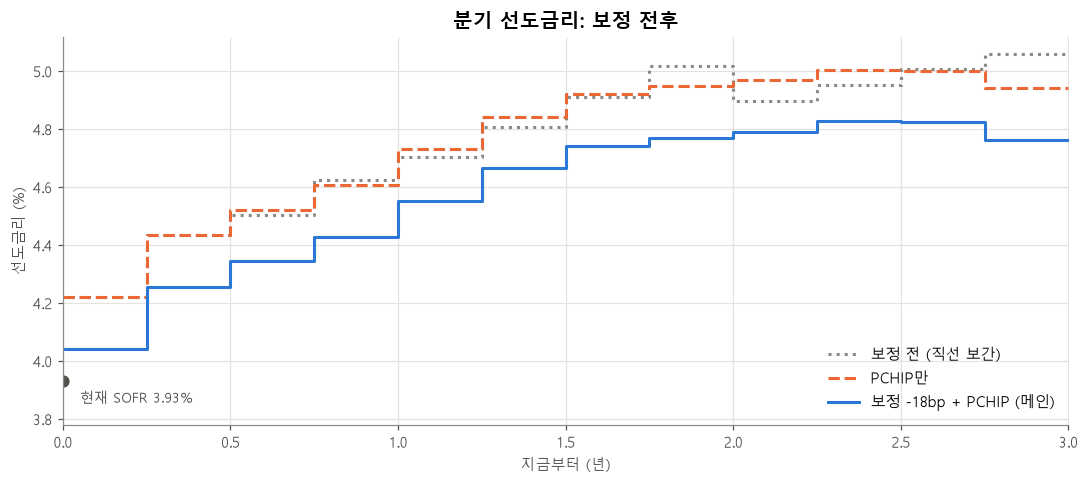

첫 분기 선도금리: 보정 전 4.22% → 메인 4.04%
2년 전후 분기: 직선 5.02% → 4.90% | PCHIP 4.77% → 4.79%


In [7]:
curve_linear = build_curve(curve_row.values, MATURITIES, horizon=3.0)
curve_pchip = build_curve(curve_row.values, MATURITIES, horizon=3.0, method="pchip")

def step_xy(c):
    # 분기마다 평평한 계단 모양으로 그리기 위한 x, y
    return np.r_[c["start"], 3.0], np.r_[c["forward"], c["forward"].iloc[-1]]

fig, ax = plt.subplots()
for c, color, style, label in [
    (curve_linear, MUTED, ":", "보정 전 (직선 보간)"),
    (curve_pchip, COLORS[1], "--", "PCHIP만"),
    (curve, COLORS[0], "-", f"보정 -{SHIFT_BP:.0f}bp + PCHIP (메인)"),
]:
    x, y = step_xy(c)
    ax.step(x, y, where="post", color=color, linestyle=style, linewidth=2, label=label)
ax.plot(0, sofr_today, "o", color=TEXT_SUB, markersize=7)
ax.annotate(f" 현재 SOFR {sofr_today:.2f}%", (0, sofr_today), xytext=(8, -14), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_xlim(0, 3)
ax.set_ylim(bottom=sofr_today - 0.15)   # 현재 SOFR 글씨가 잘리지 않게 아래 여백
ax.set_title("분기 선도금리: 보정 전후")
ax.set_xlabel("지금부터 (년)")
ax.set_ylabel("선도금리 (%)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "5_forward_curves.png", dpi=200)
plt.show()

print(f"첫 분기 선도금리: 보정 전 {curve_linear['forward'].iloc[0]:.2f}% → 메인 {curve['forward'].iloc[0]:.2f}%")
print(f"2년 전후 분기: 직선 {curve_linear['forward'].iloc[7]:.2f}% → {curve_linear['forward'].iloc[8]:.2f}% | "
      f"PCHIP {curve['forward'].iloc[7]:.2f}% → {curve['forward'].iloc[8]:.2f}%")

**읽는 법**
- **PCHIP**: 직선 보간 때 2년 지점에서 생기던 꺾임(약 5.02% → 4.90%)이 사라지고 선도금리가 매끄럽게 이어진다.
- **보정**: 곡선 전체가 18bp 내려간다. 첫 분기 선도금리가 약 4.04%로, 현재 SOFR(3.93%)와 국채 곡선(4.22%) 사이에 온다.
- 메인 시나리오는 **시장 일치 모형**(경로 평균 = 이 선도금리)이다. 그래서 이전에 걱정했던 "시나리오는 금리 하락, 가격은 금리 상승" 같은 기준 차이가 없다. (Vasicek b 기준 비교는 부록용으로 03번에 있다)

## 4. 바슐리에 공식으로 플로어렛 가격 매기기

**바슐리에(정규) 모형**: 금리가 앞으로 **정규분포**로 퍼진다고 보고 옵션 가격을 계산하는 공식. 블랙 모형(로그정규)과 달리 금리가 0 근처이거나 음수여도 쓸 수 있고, σ를 %p(= bp) 단위로 쓴다. 03번 Vasicek의 σ(0.64%p/√년)를 그대로 넣을 수 있다.

$$\text{플로어렛} = N \times 0.25 \times D(t_i) \times \Big[(K - F)\,\Phi(d) + \sigma\sqrt{T}\,\varphi(d)\Big], \quad d = \frac{K - F}{\sigma\sqrt{T}}$$

| 기호 | 뜻 |
|---|---|
| N × 0.25 × D | 명목금액 × 분기 길이 × 할인계수 (금리 %를 오늘 금액으로 바꾸는 부분) |
| K − F | 행사가가 선도금리보다 얼마나 높은지 (높을수록 '돈이 되는' 플로어) |
| σ√T | 정산 때까지 금리가 퍼질 수 있는 폭 (1 표준편차) |
| Φ, φ | 표준정규분포의 누적확률, 밀도 |

- 직관: 대괄호 안은 "**K − SOFR가 양수일 때의 평균 이익**"이다. 첫째 항은 지금 선도금리 기준 이익, 둘째 항은 금리가 흔들려서 생기는 **추가 기회의 값**(시간가치)이다.
- **T(옵션 만기)**: SOFR 플로어는 분기 동안의 SOFR를 복리로 평균해 **분기 끝에** 정산한다. 분기 중에도 금리가 움직이므로, T를 '분기 시작 + 분기 길이의 1/3'로 잡아 그 몫을 반영한다. (평균의 변동성은 하루치 변동성의 약 1/3이라는 근사)
- **σ (메인: 등가 σ)**: 메인 시나리오(시장 일치 모형)의 금리 충격은 **평균회귀**를 해서, T년 뒤 퍼짐이 σ√T보다 조금 작다. 시나리오와 가격이 **같은 퍼짐**을 쓰도록 플로어렛마다 아래 **등가 σ**를 넣는다. (9번에서 자세히)

$$\sigma_{\text{등가}}(T) = \sigma\sqrt{\frac{1 - e^{-2aT}}{2aT}}, \qquad \sigma = 0.64,\; a = 0.093$$

### 예시: 3년, K 3.5% 플로어의 분기별 조각 (메인 설정)
이 셀이 하는 일: 03번 추정값(a, σ)을 정하고, 플로어 하나를 12개 플로어렛으로 나눠 각각의 가격을 표로 본다.

In [8]:
A, SIGMA = 0.093, 0.64   # 03번 노트북 추정값 (평균회귀 속도, 변동성)

example, legs = price_floor(curve, K=3.5, maturity=3, sigma=SIGMA, a=A)

legs_view = legs[["start", "end", "forward", "D_end", "T_eff", "sigma", "floorlet"]].copy()
legs_view.columns = ["시작(년)", "끝(년)", "선도금리(%)", "할인계수", "옵션만기 T", "등가 σ", "플로어렛 가격"]
print(f"플로어 가격(명목 100) = {example['floor']:.4f}  (= {example['floor'] * 100:.2f}bp)")
legs_view

플로어 가격(명목 100) = 0.0455  (= 4.55bp)


,시작(년),끝(년),선도금리(%),할인계수,옵션만기 T,등가 σ,플로어렛 가격
분기,,,,,,,
1,0.0000,0.2500,4.0400,0.9900,0.0833,0.6375,0.0000
2,0.2500,0.5000,4.2570,0.9796,0.3333,0.6302,0.0006
3,0.5000,0.7500,4.3443,0.9691,0.5833,0.6230,0.0018
4,0.7500,1.0000,4.4278,0.9584,0.8333,0.6160,0.0028
5,1.0000,1.2500,4.5531,0.9477,1.0833,0.6091,0.0030
6,1.2500,1.5000,4.6651,0.9367,1.3333,0.6023,0.0032
7,1.5000,1.7500,4.7434,0.9258,1.5833,0.5956,0.0035
8,1.7500,2.0000,4.7696,0.9148,1.8333,0.5891,0.0043
9,2.0000,2.2500,4.7905,0.9040,2.0833,0.5827,0.0051


**읽는 법**: 뒤쪽 분기일수록 플로어렛이 비싸다. 금리가 흔들릴 시간이 길어서(등가 σ는 조금씩 작아지지만 σ√T 전체는 커짐) K 아래로 내려갈 가능성이 커지기 때문이다. 다만 뒤로 갈수록 선도금리도 높아져서(K에서 더 멀어져서) 그 효과가 일부 상쇄된다.

## 5. 가격표

### 계산
이 셀이 하는 일: 행사가 5개 × 만기 3개 × 설정 3개 = 45개 플로어의 가격을 계산한다. 같은 조합의 캡과 리시버 스왑 가치도 함께 계산해 둔다(7번 검증용).
- **▶ 메인**: 등가 σ (σ 0.64, a 0.093)
- 부록: σ 0.64 고정 (평균회귀 무시), σ 0.32 고정 (최근 3년 변동성)
- 가격 단위: **명목금액 100 기준**. 예: 0.05 = 명목의 0.05% → 명목 100억 원이면 500만 원.

In [9]:
STRIKES = [1.5, 2.0, 2.5, 3.0, 3.5]
MATURITIES_FLOOR = [1, 2, 3]
SETTINGS = {
    "▶ 메인: 등가 σ":      dict(sigma=SIGMA, a=A),
    "부록: σ 0.64 고정":   dict(sigma=SIGMA),
    "부록: σ 0.32 고정":   dict(sigma=0.32),
}

rows = []
for setting, kw in SETTINGS.items():
    for K in STRIKES:
        for T in MATURITIES_FLOOR:
            res, _ = price_floor(curve, K=K, maturity=T, **kw)
            rows.append({"설정": setting, "K(%)": K, "만기(년)": T, **res})
grid = pd.DataFrame(rows)
grid["annual_cost_bp"] = grid["floor"] / grid["만기(년)"] * 100   # 연간 비용 (명목 대비 bp/년)
print("계산한 플로어 수:", len(grid))

계산한 플로어 수: 45


### 가격표 (명목금액 100 기준)
이 셀이 하는 일: 설정별로 "행 = 행사가, 열 = 만기" 가격표를 보여준다. 첫 번째가 메인, 나머지 둘은 부록용이다.

In [10]:
price_tables = {name: grid[grid["설정"] == name].pivot(index="K(%)", columns="만기(년)", values="floor")
                for name in SETTINGS}
for name, table in price_tables.items():
    print(f"■ {name}  (플로어 가격, 명목 100 기준)")
    print(table.map(lambda v: f"{v:.4f}").to_string(), end="\n\n")

■ ▶ 메인: 등가 σ  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0000
2.0000  0.0000  0.0000  0.0002
2.5000  0.0000  0.0003  0.0017
3.0000  0.0003  0.0026  0.0094
3.5000  0.0052  0.0192  0.0455

■ 부록: σ 0.64 고정  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0002
2.0000  0.0000  0.0001  0.0008
2.5000  0.0000  0.0006  0.0041
3.0000  0.0004  0.0042  0.0174
3.5000  0.0061  0.0254  0.0664

■ 부록: σ 0.32 고정  (플로어 가격, 명목 100 기준)
만기(년)        1       2       3
K(%)                          
1.5000  0.0000  0.0000  0.0000
2.0000  0.0000  0.0000  0.0000
2.5000  0.0000  0.0000  0.0000
3.0000  0.0000  0.0000  0.0000
3.5000  0.0000  0.0001  0.0009



**읽는 법**
- **메인**에서 가장 비싼 3년·K 3.5%가 명목 100당 약 **0.046**(약 4.6bp)이다. 행사가(1.5~3.5%)가 모두 보정 선도금리(약 4.0~4.8%)보다 아래에 있는 **외가격**(지금 기준으로는 돈이 안 되는) 플로어라 전체적으로 싸다.
- K 2.5% 이하이거나 만기 1년인 플로어는 사실상 0에 가깝다.
- 부록 σ 0.64 고정은 같은 3년·K 3.5%가 0.066으로 더 비싸다(평균회귀를 무시해 퍼짐을 크게 봄). σ 0.32 고정은 거의 0이다.

### 보정 전후 가격 비교
이 셀이 하는 일: 같은 플로어(메인 등가 σ, 만기 3년)를 곡선 만드는 방법만 바꿔 가격을 비교한다. 곡선 보정이 가격에 얼마나 영향을 주는지 본다.

In [11]:
curve_shift3m = build_curve(curve_row.values, MATURITIES, horizon=3.0, method="pchip",
                            shift_bp=gap["3개월 국채 − SOFR (bp)"])
CURVES = {
    "보정 전 (직선)":                curve_linear,
    "PCHIP만":                     curve_pchip,
    "▶ 메인 (−1개월 차이 + PCHIP)":   curve,
    "참고 (−3개월 차이 + PCHIP)":     curve_shift3m,
}
compare = pd.DataFrame({name: {K: price_floor(c, K=K, maturity=3, sigma=SIGMA, a=A)[0]["floor"] for K in STRIKES}
                        for name, c in CURVES.items()})
compare.index.name = "K(%)"
compare.map(lambda v: f"{v:.4f}")

,보정 전 (직선),PCHIP만,▶ 메인 (−1개월 차이 + PCHIP),참고 (−3개월 차이 + PCHIP)
K(%),,,,
1.5000,0.0000,0.0000,0.0000,0.0000
2.0000,0.0001,0.0001,0.0002,0.0004
2.5000,0.0008,0.0009,0.0017,0.0025
3.0000,0.0049,0.0051,0.0094,0.0134
3.5000,0.0259,0.0263,0.0455,0.0633


**읽는 법**
- **PCHIP만** 바꾸면 가격은 거의 그대로다(+1~2%). 꺾임은 사라지지만 곡선 높이는 비슷하기 때문이다.
- **보정(−18bp)**이 가격을 약 **1.8~2배**로 올린다(3년·K 3.5%: 0.026 → 0.046). 3개월 기준(−29bp)으로 보정하면 0.063으로 더 오른다.
- 외가격 플로어는 선도금리가 조금만 내려가도 가격이 크게 변한다. 그래서 국채−SOFR 보정 폭이 결과에 꽤 중요하다.

## 6. 연간 비용으로 환산
이 셀이 하는 일: 프리미엄 ÷ 만기 = **1년에 명목금액의 몇 bp를 내는 셈인지**로 바꾼다. 만기가 다른 플로어를 같은 기준으로 비교하기 위해서다.
- 1bp = 0.01%. 명목 100억 원이면 1bp = 100만 원.
- 비교 기준: 준비금 수익률이 약 4%라면 1년 이자수익은 명목의 **400bp**다.

In [12]:
cost_tables = {name: grid[grid["설정"] == name].pivot(index="K(%)", columns="만기(년)", values="annual_cost_bp")
               for name in SETTINGS}
for name, table in cost_tables.items():
    print(f"■ {name}  (연간 비용, bp/년)")
    print(table.map(lambda v: f"{v:.3f}").to_string(), end="\n\n")

■ ▶ 메인: 등가 σ  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.001
2.0000  0.000  0.001  0.008
2.5000  0.001  0.013  0.055
3.0000  0.033  0.128  0.313
3.5000  0.517  0.959  1.518

■ 부록: σ 0.64 고정  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.005
2.0000  0.000  0.003  0.028
2.5000  0.002  0.029  0.137
3.0000  0.045  0.210  0.579
3.5000  0.607  1.269  2.214

■ 부록: σ 0.32 고정  (연간 비용, bp/년)
만기(년)       1      2      3
K(%)                       
1.5000  0.000  0.000  0.000
2.0000  0.000  0.000  0.000
2.5000  0.000  0.000  0.000
3.0000  0.000  0.000  0.001
3.5000  0.002  0.006  0.029



**읽는 법**
- **메인**에서 가장 비싼 3년·K 3.5%가 **연 약 1.5bp**이고, 1년·K 3.5%는 연 약 0.5bp다. 이자수익(약 400bp)과 비교하면 매우 작다.
- 메인 설정의 **거래비용(연 2bp)**과 비교해 보자. 메인 가격표에서는 **모든 조합의 프리미엄이 거래비용보다 작다.** 지금은 **헤지 비용의 대부분이 프리미엄이 아니라 거래비용**이라는 뜻이다.
- 만기가 길수록 연간 비용이 커진다. 뒤쪽 분기 플로어렛이 더 비싸기 때문이다. 같은 K라도 1년과 3년의 연간 비용이 3배 이상 차이가 나서(K 3.5%: 0.5 vs 1.5bp), **만기 선택**이 비용에 직접 영향을 준다.

## 7. 검증: 플로어 − 캡 = 리시버 스왑

같은 행사가 K, 같은 만기의 **플로어를 사고 캡을 팔면**, 금리가 어디로 가든 매 분기 (K − SOFR)를 받는다.
- 금리 < K: 플로어에서 K − SOFR를 받는다
- 금리 > K: 캡에서 SOFR − K를 낸다 = (K − SOFR)를 받는 것과 같다

이것은 "**고정금리 K를 받고 변동금리를 내는 스왑**(리시버 스왑)"과 정확히 같다. 그래서 가격도 같아야 한다.

$$\text{플로어} - \text{캡} = \sum_i N \times 0.25 \times D(t_i) \times (K - F_i)$$

- 이 관계는 σ나 모형과 상관없이 성립해야 한다. 성립하지 않으면 계산에 실수가 있다는 뜻이다.

이 셀이 하는 일: 30개 조합 모두에서 (플로어 − 캡)과 리시버 스왑 가치를 비교하고, 스왑 가치를 **다른 방법**(연금계수 × (K − 스왑금리))으로도 계산해 맞춰 본다.
- **스왑금리 S**: 리시버 스왑 가치가 0이 되는 고정금리 = 선도금리들의 가중평균
- **연금계수**: 분기마다 1%p씩 받을 때의 현재가치 합 = Σ 0.25 × D(t_i)

In [13]:
grid["floor_minus_cap"] = grid["floor"] - grid["cap"]
grid["parity_error"] = grid["floor_minus_cap"] - grid["receiver_swap"]

swap_rate = {T: (curve.loc[curve["end"] <= T + 1e-9].eval("0.25 * D_end * forward").sum()
                 / curve.loc[curve["end"] <= T + 1e-9].eval("0.25 * D_end").sum()) for T in MATURITIES_FLOOR}
grid["swap_by_annuity"] = grid["annuity"] * (grid["K(%)"] - grid["만기(년)"].map(swap_rate))

print("스왑금리:", {f"{T}년": f"{s:.3f}%" for T, s in swap_rate.items()})
print(f"(플로어 − 캡) − 리시버 스왑 의 최대 오차: {grid['parity_error'].abs().max():.2e}")
print(f"리시버 스왑 두 계산법의 최대 차이:       {(grid['receiver_swap'] - grid['swap_by_annuity']).abs().max():.2e}")
grid.loc[grid["설정"] == "▶ 메인: 등가 σ", ["K(%)", "만기(년)", "floor", "cap", "floor_minus_cap", "receiver_swap"]].head(6)

스왑금리: {'1년': '4.266%', '2년': '4.469%', '3년': '4.575%'}
(플로어 − 캡) − 리시버 스왑 의 최대 오차: 1.78e-15
리시버 스왑 두 계산법의 최대 차이:       1.78e-15


,K(%),만기(년),floor,cap,floor_minus_cap,receiver_swap
0,1.5000,1,0.0000,2.6944,-2.6944,-2.6944
1,1.5000,2,0.0000,5.6574,-5.6574,-5.6574
2,1.5000,3,0.0000,8.5892,-8.5892,-8.5892
3,2.0000,1,0.0000,2.2073,-2.2073,-2.2073
4,2.0000,2,0.0000,4.7047,-4.7046,-4.7046
5,2.0000,3,0.0002,7.1926,-7.1924,-7.1924


**읽는 법**: 오차가 컴퓨터 계산 오차 수준(10⁻¹⁵ 정도)이라 관계가 **정확히 성립**한다. 리시버 스왑 가치는 모두 음수다. 스왑금리(약 4.3~4.6%)가 모든 K보다 높아서, 낮은 고정금리를 받는 쪽이 손해이기 때문이다. 캡이 비싸고 플로어가 싼 것도 같은 이유다.

## 8. 가격은 K, σ, 만기에 따라 어떻게 변하나
이 셀이 하는 일: 가격표보다 넓은 범위에서 세 요인을 하나씩 바꿔 가며 플로어 가격을 그린다. (메인 등가 σ 기준, 명목 100당 bp로 표시)
- 행사가는 선도금리 근처(4~5%)까지 넓혀야 모양이 잘 보여서 1.5~5.5%로 그린다.

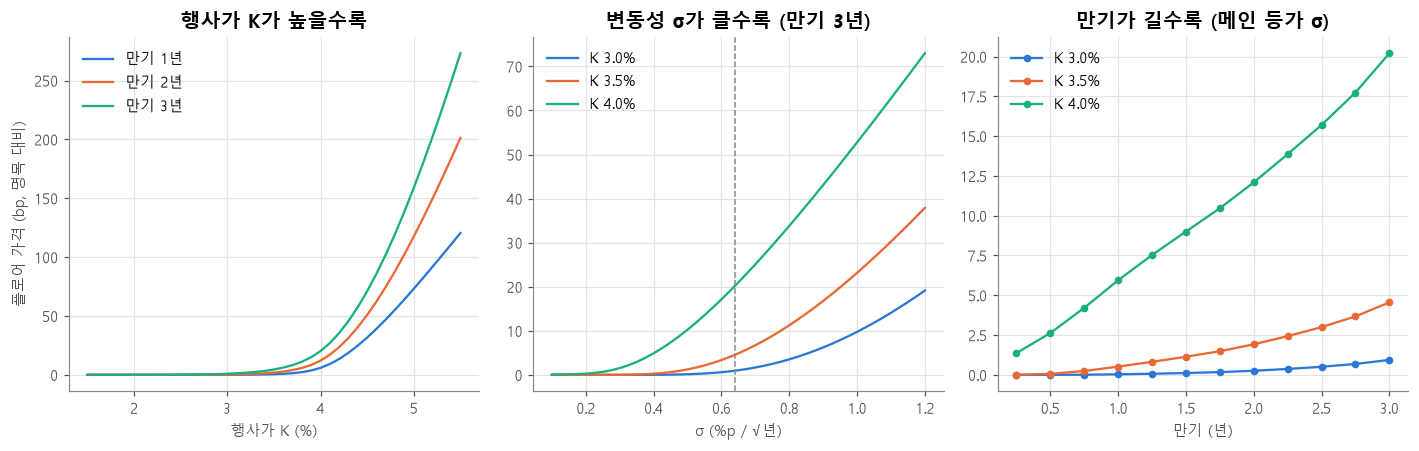

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

# (1) 행사가 K
k_grid = np.linspace(1.5, 5.5, 41)
for T, color in zip(MATURITIES_FLOOR, COLORS):
    prices = [price_floor(curve, K=k, maturity=T, sigma=SIGMA, a=A)[0]["floor"] * 100 for k in k_grid]
    axes[0].plot(k_grid, prices, color=color, label=f"만기 {T}년")
axes[0].set_title("행사가 K가 높을수록")
axes[0].set_xlabel("행사가 K (%)")
axes[0].set_ylabel("플로어 가격 (bp, 명목 대비)")
axes[0].legend(loc="upper left")

# (2) 변동성 σ
s_grid = np.linspace(0.1, 1.2, 45)
for K, color in zip([3.0, 3.5, 4.0], COLORS):
    prices = [price_floor(curve, K=K, maturity=3, sigma=s, a=A)[0]["floor"] * 100 for s in s_grid]
    axes[1].plot(s_grid, prices, color=color, label=f"K {K}%")
axes[1].axvline(SIGMA, color=MUTED, linestyle="--", linewidth=1)
axes[1].set_title("변동성 σ가 클수록 (만기 3년)")
axes[1].set_xlabel("σ (%p / √년)")
axes[1].legend(loc="upper left")

# (3) 만기
t_steps = np.arange(0.25, 3.01, 0.25)
for K, color in zip([3.0, 3.5, 4.0], COLORS):
    prices = [price_floor(curve, K=K, maturity=T, sigma=SIGMA, a=A)[0]["floor"] * 100 for T in t_steps]
    axes[2].plot(t_steps, prices, color=color, marker="o", markersize=4, label=f"K {K}%")
axes[2].set_title("만기가 길수록 (메인 등가 σ)")
axes[2].set_xlabel("만기 (년)")
axes[2].legend(loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "5_floor_sensitivity.png", dpi=200)
plt.show()

**직관적 의미**
- **행사가 K ↑ → 가격 ↑ (점점 가파르게)**: K가 높을수록 더 높은 금리 수준부터 보호해 주는 보험이라 비싸다. 선도금리에서 멀리 떨어진 낮은 K는 거의 공짜에 가깝고, K가 선도금리(4~5%)에 가까워질수록 가격이 **빠르게** 오른다. 보험으로 치면 "자기부담금이 작을수록 보험료가 비싼" 것과 같다.
- **σ ↑ → 가격 ↑**: 금리가 크게 흔들릴수록 K 아래로 떨어질 가능성이 커진다. 지금처럼 외가격인 플로어는 σ에 특히 **민감**하다. σ가 두 배가 되면 가격은 몇 배~수십 배가 된다. σ를 무엇으로 정하느냐가 가격을 크게 좌우하는 이유다.
- **만기 ↑ → 가격 ↑**: 보호받는 분기 수가 늘고, 먼 분기일수록 금리가 흔들릴 시간이 길어 플로어렛 하나하나도 비싸다. 그래서 만기가 2배가 되면 가격은 2배보다 더 커지고, **연간 비용**(6번)도 만기가 길수록 커진다.

## 9. 시장 일치 시뮬레이션과 맞는지 점검

메인 시나리오는 `src/rate_model.py`의 **시장 일치 모형**으로 만든다.

$$r(t) = f(0, t) + x(t), \qquad dx = -a\,x\,dt + \sigma\,dW,\quad x(0) = 0$$

- f(0, t): 위에서 만든 **보정 곡선의 선도금리**
- x(t): 평균 0으로 돌아가는 무작위 충격 (03번 추정값 a = 0.093, σ = 0.64)
- 그래서 경로들의 **평균 = 선도금리**가 되고, 시나리오와 플로어 가격이 같은 기준 위에 선다.

시뮬레이션 분석은 05번에서 한다. 여기서는 함수가 제대로 작동하는지만 두 가지로 확인한다.

### 점검 ① 경로 평균 = 선도금리?
이 셀이 하는 일: 보정 곡선으로 월별 선도금리를 만들고, 경로 20,000개의 달별 평균과 비교한다.

In [15]:
fwd_monthly = monthly_forwards(curve_row.values, MATURITIES, months=36, shift_bp=SHIFT_BP, method="pchip")
check_paths = simulate_market_consistent(fwd_monthly, A, SIGMA, n_paths=20000, seed=42)

gap_mean = np.abs(check_paths.mean(axis=0) - fwd_monthly)
print(f"첫 달 선도금리 {fwd_monthly[0]:.2f}% (현재 SOFR {sofr_today:.2f}%) | 36개월째 {fwd_monthly[-1]:.2f}%")
print(f"경로 평균과 선도금리의 최대 차이: {gap_mean.max():.4f}%p  (0에 가까우면 정상)")

첫 달 선도금리 3.93% (현재 SOFR 3.93%) | 36개월째 4.69%
경로 평균과 선도금리의 최대 차이: 0.0086%p  (0에 가까우면 정상)


### 점검 ② 왜 등가 σ인가 (결정 근거)
시장 일치 모형의 충격 x(t)는 **평균회귀**를 해서, T년 뒤 퍼짐이 σ√T보다 조금 작다.

$$\text{T년 뒤 표준편차} = \sigma\sqrt{\frac{1 - e^{-2aT}}{2a}} = \underbrace{\sigma\sqrt{\frac{1 - e^{-2aT}}{2aT}}}_{\text{등가 σ}} \times \sqrt{T}$$

σ 0.64를 모든 만기에 그대로 쓰면(부록 가격표) 시나리오보다 퍼짐을 크게 보게 된다. 시뮬레이션과 **완전히** 같은 퍼짐을 쓰도록 메인 가격표는 플로어렛마다 이 등가 σ를 넣었다. → **결정: 가격 σ = 등가 σ.**

이 셀이 하는 일: 등가 σ가 만기에 따라 얼마인지 보고, 3년 플로어 가격을 메인(등가 σ)과 부록(σ 0.64 고정)으로 비교한다.

In [16]:
print("등가 σ:", {f"{T}년": round(float(equivalent_sigma(T, A, SIGMA)), 3) for T in [0.5, 1, 2, 3]})

three_year = grid[grid["만기(년)"] == 3].pivot(index="K(%)", columns="설정", values="floor")
sigma_compare = three_year[["▶ 메인: 등가 σ", "부록: σ 0.64 고정"]].copy()
sigma_compare["메인 ÷ 부록 − 1 (%)"] = (sigma_compare.iloc[:, 0] / sigma_compare.iloc[:, 1] - 1) * 100
sigma_compare.index.name = "K(%) · 만기 3년"
sigma_compare

등가 σ: {'0.5년': 0.625, '1년': 0.611, '2년': 0.585, '3년': 0.56}


설정,▶ 메인: 등가 σ,부록: σ 0.64 고정,메인 ÷ 부록 − 1 (%)
K(%) · 만기 3년,,,
1.5000,0.0000,0.0002,-80.5262
2.0000,0.0002,0.0008,-71.1736
2.5000,0.0017,0.0041,-59.5447
3.0000,0.0094,0.0174,-46.0068
3.5000,0.0455,0.0664,-31.4214


**읽는 법**
- **점검 ①**: 경로 평균이 선도금리와 0.01%p 안에서 같다. 첫 달 선도금리도 3.93%로 현재 SOFR와 같다. 함수가 의도대로 작동한다.
- **점검 ②**: 평균회귀 때문에 등가 σ는 1년 0.61, 3년 0.56으로 0.64보다 작다. 그래서 메인(등가 σ) 3년 플로어는 σ 0.64 고정보다 **31~80% 싸다**(외가격일수록 차이가 크다). σ 0.64 고정 가격은 시나리오보다 퍼짐을 크게 본 값이라 부록용으로만 남긴다.

## 10. 정리

**메인 설정**: 미국채 곡선 − 18bp(1개월 국채 − SOFR) + PCHIP 보간, 바슐리에 + **등가 σ**(σ 0.64, a 0.093). 첫 달 선도금리 = 현재 SOFR 3.93%.

**메인 가격 요약 (명목 100 기준)**

| | 1년 | 3년 | 3년 연간 비용 |
|---|---|---|---|
| K 3.5% | 0.005 | 0.046 | 연 1.5bp |
| K 3.0% | 0.0003 | 0.009 | 연 0.3bp |
| K 2.5% 이하 | ≈ 0 | 0.002 이하 | 연 0.06bp 이하 |

- **지금은 플로어가 싸다.** 보정 후에도 선도금리(4.0~4.8%)가 모든 행사가보다 높다. 시장은 금리 상승을 반영하고 있다.
- **만기에 따라 연간 비용이 크게 다르다.** 같은 K 3.5%라도 1년은 연 0.5bp, 3년은 연 1.5bp다.
- 모든 조합에서 프리미엄이 **거래비용(연 2bp)**보다 작다.
- 부록: σ 0.64 고정 가격표(평균회귀 무시)는 메인보다 31~80% 비싸다. σ 0.32 고정은 거의 0이다.

**한계 (기록)**
1. **국채−SOFR 보정이 단순하다**: 모든 만기에서 차이가 18bp로 같다고 본다. 보정 폭이 가격을 크게 바꾼다(3개월 기준 29bp면 3년·K 3.5%가 0.046 → 0.063).
2. **이표채 수익률을 영금리로 근사, 분기 = 0.25년**: 3년 이내·완만한 곡선이라 오차는 몇 bp 수준으로 본다.
3. **SOFR 후취 정산을 "T = 분기 시작 + 분기/3"로 근사**했다.
4. **σ 하나로 모든 행사가를 계산**: 실제 시장에서는 행사가마다 변동성이 다르다(변동성 스마일). 또 과거 데이터로 추정한 σ라서 시장 내재변동성과 다를 수 있다.

---

# 5단계: 몬테카를로 시뮬레이션 + 최적 정책

*원본 파일: `notebooks/05_simulation.ipynb`*

# 05. 몬테카를로 시뮬레이션: 플로어 운용 정책 비교

**질문:** 발행사가 어떤 플로어 전략을 쓰면 **"3년 중 한 해라도 적자"일 확률을 5% 이하**로 지키면서 **헤지 비용을 가장 적게** 쓸 수 있나? 발행사 규모에 따라 답이 달라지나?

- **몬테카를로 시뮬레이션**: 미래 금리 경로를 무작위로 수천~수만 개 만들어, 각 경로에서 발행사 손익을 계산한 뒤 그 **분포**를 보는 방법.

**메인 설정 (CLAUDE.md "최종 범위")**

| 항목 | 설정 |
|---|---|
| 금리 | 시장 일치 모형 r(t) = f(0, t) + x(t), a = 0.093, σ = 0.64. 월간 36개월, 경로 10,000개 |
| 곡선 | 미국채 − 18bp(1개월 국채 − SOFR), PCHIP 보간 |
| 준비금 수익률 | max(r, 0) − 0.15%p (Circle 실제 수익률 검증 결과) |
| 발행사 손익 | 매달 (1 − s) × 준비금 수익률 × R ÷ 12 − C ÷ 12. C·s는 Circle 값 |
| 발행량 | **R 고정 (g = 0)**, b1 = 0. 최근 24개월 성장률(연 30%)은 비교용 |
| 규모 | r* 기준: 신규 진입 4.5%, Circle 수준 3.6%, 대형 2.5% → R 역산 |
| 플로어 | 명목 N = h × R. 정산: 매달 N × max(K − r, 0) ÷ 12. 가격: 바슐리에 + 등가 σ |
| 행사가 | 규모마다 r* − 1%, r* − 0.5%, r*, r* + 0.5% |
| 거래비용 | 연 2bp × N |
| 전략 | 무헤지 + K 4개 × h(1 − s = 37.5%, 50%, 100%) × 만기(1년 롤링, 3년) = 25개 |
| 평가 | **한 해라도 연간 적자인 경로 비율** = 손실확률, 총 헤지 비용(보험료·거래비용). 3년 누적 기준은 참고 |

## 1. 준비
이 셀이 하는 일: 도구와 함수를 불러오고 경로·그래프 설정을 한다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
from src.floor_pricing import build_curve, price_floor, price_floor_later, monthly_forwards
from src.rate_model import simulate_market_consistent
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. 입력값

### Circle 기준 고정비 C와 배분율 s
이 셀이 하는 일: 01번 노트북 3번 섹션에서 저장한 값을 읽는다.

In [2]:
circle = pd.read_csv(PROC_DIR / "circle_params.csv", index_col=0)["value"]
C = float(circle["C_musd_per_year"]) * 1e6      # 달러/년
S = float(circle["s"])                          # 배분율
YIELD_GAP = 0.15                                # 준비금 수익률 = max(r, 0) − 0.15%p
print(f"고정비 C = {C / 1e6:,.0f} 백만 달러/년 | 배분율 s = {S:.3f} → 발행사 몫 1 − s = {1 - S:.3f}")

고정비 C = 962 백만 달러/년 | 배분율 s = 0.625 → 발행사 몫 1 − s = 0.375


### 성장률
이 셀이 하는 일: 메인은 **g = 0**(발행량이 3년간 그대로)이다. 비교용으로 USDC 제외 시장의 최근 24개월 평균 성장률도 계산해 둔다.
- g = 0을 메인으로 하는 이유: 손실확률은 **성장이 멈췄을 때**도 버틸 수 있는지를 봐야 한다. 최근 24개월은 금리 인하기와 GENIUS법이 겹친 특수한 성장기였다.

In [3]:
monthly = pd.read_parquet(PROC_DIR / "usdc_rates_monthly.parquet").loc[:"2026-09-30"]
ex_usdc = monthly["stable_total_bn"] - monthly["usdc_bn"]
G_MAIN = 0.0
G_RECENT = np.log(ex_usdc).diff().iloc[-24:].mean()
print(f"메인 g = 0 | 비교용 최근 24개월 g = {G_RECENT:.4f}/월 (연 {np.exp(G_RECENT * 12) - 1:+.1%})")

메인 g = 0 | 비교용 최근 24개월 g = 0.0219/월 (연 +30.1%)


### 금리 곡선과 모형 파라미터
이 셀이 하는 일: 04번과 같은 방법으로 보정 곡선(−18bp, PCHIP)을 만들고, 분기 곡선(플로어 가격용)과 월별 선도금리(시뮬레이션용)를 준비한다.

In [4]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")
CURVE_IDS = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
MATURITIES = np.array([1 / 12, 0.25, 0.5, 1, 2, 3, 5, 10])

curve_row = rates[CURVE_IDS].dropna().iloc[-1]
sofr_today = rates.loc[curve_row.name, "SOFR"]
SHIFT_BP = (curve_row["DGS1MO"] - sofr_today) * 100

A, SIGMA = 0.093, 0.64          # 03번 추정 (평균회귀 속도, 변동성)
MONTHS, N_PATHS = 36, 10_000

curve = build_curve(curve_row.values, MATURITIES, horizon=3.0, shift_bp=SHIFT_BP, method="pchip")
fwd = monthly_forwards(curve_row.values, MATURITIES, months=MONTHS, shift_bp=SHIFT_BP, method="pchip")
print(f"곡선 날짜 {curve_row.name:%Y-%m-%d} | 보정 {SHIFT_BP:.0f}bp | 첫 달 선도금리 {fwd[0]:.2f}% → 36개월째 {fwd[-1]:.2f}%")

곡선 날짜 2026-10-26 | 보정 18bp | 첫 달 선도금리 3.93% → 36개월째 4.69%

## 3. 발행사 3개 규모

고정비 C와 배분율 s는 Circle과 같고 **준비금 R만 다르게** 둔다. 손익분기 금리 r*가 목표값이 되도록 R을 거꾸로 계산한다.

$$r^* = \frac{C}{(1 - s)\,R} \quad\Rightarrow\quad R = \frac{C}{(1 - s)\,r^*}$$

- **r\* (손익분기 금리)**: 발행사 몫의 준비금 수익률이 이보다 낮으면 적자가 나는 수준.
- 준비금 수익률이 기준금리보다 0.15%p 낮으므로, **기준금리로 보면** 손익분기점은 r* + 0.15%p다.

| 규모 | r* | 의미 |
|---|---|---|
| 신규 진입 | 4.5% | 아직 작아서 고정비 부담이 큰 발행사. 지금 금리(3.93%)보다 높다 |
| Circle 수준 | 3.6% | 실제 Circle의 r* (01번 3번 섹션 값 기준) |
| 대형 | 2.5% | 규모가 커서 고정비 부담이 작은 발행사 |

이 셀이 하는 일: 세 규모의 R과 r*, 기준금리 기준 손익분기점, 그리고 규모별 행사가 4개를 표로 보여준다.

In [5]:
TARGET_RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}       # %
R0 = {size: C / ((1 - S) * rstar / 100) for size, rstar in TARGET_RSTAR.items()}
STRIKE_OFFSETS = [-1.0, -0.5, 0.0, 0.5]                                   # r* 기준 행사가 차이 (%p)
STRIKES = {size: [round(rstar + off, 2) for off in STRIKE_OFFSETS] for size, rstar in TARGET_RSTAR.items()}

usdc_now = pd.read_parquet(PROC_DIR / "usdc_rates.parquet")["usdc_bn"].iloc[-1] * 1e9
pd.DataFrame({
    "R (10억 달러)":              {k: v / 1e9 for k, v in R0.items()},
    "r* (%)":                    TARGET_RSTAR,
    "기준금리 기준 손익분기점 (%)":    {k: v + YIELD_GAP for k, v in TARGET_RSTAR.items()},
    "행사가 K (%)":                {k: ", ".join(f"{x:.1f}" for x in v) for k, v in STRIKES.items()},
}).assign(**{"참고: 실제 USDC (10억 달러)": [np.nan, usdc_now / 1e9, np.nan]})

,R (10억 달러),r* (%),기준금리 기준 손익분기점 (%),행사가 K (%),참고: 실제 USDC (10억 달러)
신규 진입,56.9957,4.5000,4.6500,"3.5, 4.0, 4.5, 5.0",NaN
Circle 수준,71.2447,3.6000,3.7500,"2.6, 3.1, 3.6, 4.1",71.7120
대형,102.5923,2.5000,2.6500,"1.5, 2.0, 2.5, 3.0",NaN


## 4. 금리 경로

이 셀이 하는 일: 시장 일치 모형으로 36개월 금리 경로 10,000개를 만든다. 경로 평균 = 선도금리가 되도록 만든 모형이다.

In [6]:
paths = simulate_market_consistent(fwd, A, SIGMA, n_paths=N_PATHS, seed=42)   # (10000, 37): 0~36개월
r = paths[:, :MONTHS]                                                          # 0~35개월: 매달 적용 금리
x_state = paths - fwd[np.newaxis, :]                                           # 경로별 충격 x(t)

pd.DataFrame({
    "5%":    np.percentile(paths, 5, axis=0),
    "중앙값":  np.median(paths, axis=0),
    "95%":   np.percentile(paths, 95, axis=0),
    "선도금리": fwd,
}).iloc[[0, 12, 24, 36]].rename(index=lambda m: f"{m}개월")

,5%,중앙값,95%,선도금리
0개월,3.9300,3.9300,3.9300,3.9300
12개월,3.4987,4.4847,5.5045,4.4950
24개월,3.4186,4.7453,6.1166,4.7528
36개월,3.1077,4.6924,6.2970,4.6939


### 금리 분포와 세 규모의 손익분기점
이 셀이 하는 일: 경로의 5~95% 범위와 중앙값을 그리고, 세 규모의 **기준금리 기준 손익분기점**(r* + 0.15%p)을 가로선으로 겹쳐 그린다. 금리가 선 아래로 내려가는 달에는 그 규모의 발행사가 그 달 적자다.

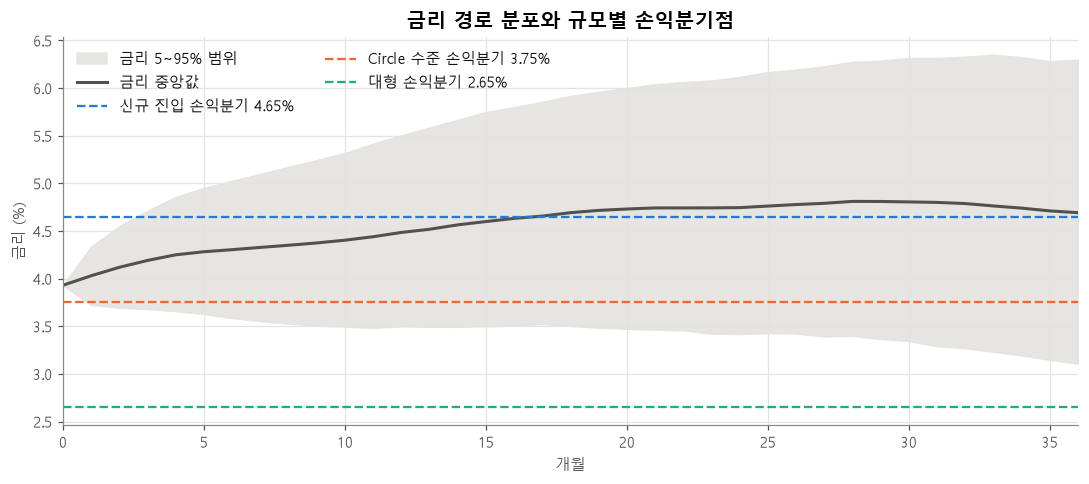

In [7]:
months_axis = np.arange(MONTHS + 1)
p5, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(months_axis, p5, p95, color=SHADE, alpha=0.9, label="금리 5~95% 범위")
ax.plot(months_axis, p50, color=TEXT_SUB, linewidth=2, label="금리 중앙값")
for (size, rstar), color in zip(TARGET_RSTAR.items(), COLORS):
    ax.axhline(rstar + YIELD_GAP, color=color, linestyle="--", label=f"{size} 손익분기 {rstar + YIELD_GAP:.2f}%")

ax.set_xlim(0, MONTHS)
ax.set_title("금리 경로 분포와 규모별 손익분기점")
ax.set_xlabel("개월")
ax.set_ylabel("금리 (%)")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "6_rates_vs_rstar.png", dpi=200)
plt.show()

## 5. 발행사 연간 손익 (무헤지)

$$\pi_{\text{월}} = (1 - s)\,\big(\max(r, 0) - 0.15\big)\,\frac{R}{12} - \frac{C}{12}$$

- 1년차 = 0~11개월, 2년차 = 12~23개월, 3년차 = 24~35개월의 월 손익을 더한 값.
- **손실확률(메인)**: 세 해 중 **한 해라도** 연간 손익이 0보다 작은 경로의 비율. 3년을 합치면 초반 이익이 뒤의 손실을 덮어 위험이 작게 보이기 때문이다.
- **참고**: 3년 누적 손익(할인 없이 합산)이 0보다 작은 경로의 비율.

이 셀이 하는 일: 경로별 월 손익을 연 단위로 묶는 함수와, 규모별 무헤지 결과를 만든다.

In [8]:
k = np.arange(MONTHS)                     # 0~35개월
YEAR_OF_MONTH = k // 12                   # 0, 1, 2년차


def to_years(monthly_cash):
    # (경로, 36개월) → (경로, 3년) 연간 합계
    return np.stack([monthly_cash[:, YEAR_OF_MONTH == y].sum(axis=1) for y in range(3)], axis=1)


def base_annual(R_start, g=G_MAIN):
    # 무헤지 연간 손익 (경로, 3년), 달러
    R_t = R_start * np.exp(g * k)
    reserve_yield = np.maximum(r, 0) - YIELD_GAP               # %
    income = (1 - S) * reserve_yield / 100 * R_t / 12
    return to_years(income - C / 12)


def loss_probs(annual):
    # (한 해라도 적자 확률, 3년 누적 적자 확률) — %
    return (annual < 0).any(axis=1).mean() * 100, (annual.sum(axis=1) < 0).mean() * 100

base = {size: base_annual(R_start) for size, R_start in R0.items()}
pd.DataFrame({
    "평균 연간 손익 (백만 달러)":     {s_: v.mean() / 1e6 for s_, v in base.items()},
    "한 해라도 적자 (%)":          {s_: loss_probs(v)[0] for s_, v in base.items()},
    "참고: 3년 누적 적자 (%)":      {s_: loss_probs(v)[1] for s_, v in base.items()},
})

,평균 연간 손익 (백만 달러),한 해라도 적자 (%),참고: 3년 누적 적자 (%)
신규 진입,-18.2753,90.1900,56.5100
Circle 수준,217.5454,16.5300,7.2100
대형,736.3509,0.7900,0.0200


## 6. 플로어

- **정산**: 매달 N × max(K − r, 0) ÷ 12. 금리가 K 아래인 달에 그 차이만큼 받는다.
- **거래비용**: 매년 N × 2bp.
- **보험료**:
  - **3년 만기**: 처음에 3년짜리를 한 번 산다. 가격은 지금 곡선으로 정해져 모든 경로에서 같다.
  - **1년 롤링**: 0, 12, 24개월에 1년짜리를 새로 산다. 12·24개월에는 **그때의 금리 상태**로 가격이 정해지므로 경로마다 다르다. (그때 선도금리 ≈ 지금 선도금리 + x(t)·e^(−a(T − t)))
- **연간 손익에 보험료를 나누는 방법**: 보험료는 보호받는 기간에 고르게 나눠 비용으로 잡는다. 3년 만기는 매년 1/3씩, 1년 롤링은 산 해에 전부. (회계에서 보험료를 기간에 나눠 비용 처리하는 것과 같다. 3년 만기 보험료를 1년차에 다 넣으면 1년차만 불리해진다)

이 셀이 하는 일: 한 전략의 경로별 연간 (보험료, 거래비용, 정산액)을 계산하는 함수를 만든다.

In [9]:
TC_BP_PER_YEAR = 2.0


def floor_annual(R_start, K, h, tenor):
    # 반환: 보험료(경로, 3년), 거래비용(3년), 정산액(경로, 3년) — 달러
    N = h * R_start
    payoff = to_years(N * np.maximum(K - r, 0) / 100 / 12)
    tcost = np.full(3, N * TC_BP_PER_YEAR / 10_000)
    if tenor == "3년":
        total = price_floor(curve, K, 3, SIGMA, a=A)[0]["floor"] * N / 100
        premium = np.full((N_PATHS, 3), total / 3)                 # 3년에 고르게 나눔
    else:   # 1년 롤링: 0, 12, 24개월에 1년짜리 매입
        premium = np.stack([price_floor_later(curve, year, x_state[:, 12 * year], K, 1, SIGMA, A) * N / 100
                            for year in range(3)], axis=1)
    return premium, tcost, payoff

### 25개 전략 정의
이 셀이 하는 일: 규모마다 무헤지 + K 4개 × h 3개 × 만기 2개 = 25개 전략 목록을 만든다. 전략 이름에는 r* 대비 행사가 위치를 적는다.
- 헤지 비율 h 후보: **1 − s(≈ 37.5%, 발행사 몫)**, 50%, 100%

In [10]:
HEDGE_RATIOS = [round(1 - S, 3), 0.5, 1.0]   # 1 − s ≈ 0.375 (발행사 몫), 50%, 100%
TENORS = ["1년 롤링", "3년"]


def strategies_for(size):
    rstar = TARGET_RSTAR[size]
    items = [("무헤지", None, None, None, None)]
    for off, K in zip(STRIKE_OFFSETS, STRIKES[size]):
        for h in HEDGE_RATIOS:
            for tenor in TENORS:
                items.append((f"K r*{off:+.1f} ({K:.1f}%) h{h * 100:g} {tenor}", K, off, h, tenor))
    return items

print(len(strategies_for("대형")), "개 전략 (예: 대형)")

25 개 전략 (예: 대형)


## 7. 시뮬레이션 실행
이 셀이 하는 일: 규모 3개 × 전략 25개 = 75개 조합마다 경로 1만 개의 연간 손익을 계산하고 결과를 표로 모은다. 비교용 성장률(연 30%)로도 같은 계산을 해 둔다.

$$\text{연간 손익} = \text{무헤지 연간 손익} + \text{플로어 정산액} - \text{보험료(나눈 몫)} - \text{거래비용}$$

In [11]:
def run_all(g):
    records = []
    for size, R_start in R0.items():
        base_y = base_annual(R_start, g=g)
        for name, K, off, h, tenor in strategies_for(size):
            if K is None:
                premium, tcost, payoff = np.zeros((N_PATHS, 3)), np.zeros(3), np.zeros((N_PATHS, 3))
            else:
                premium, tcost, payoff = floor_annual(R_start, K, h, tenor)
            annual = base_y + payoff - premium - tcost
            any_year, cumulative = loss_probs(annual)
            records.append({
                "규모": size, "전략": name, "K": K, "K−r*": off, "h": h, "만기": tenor,
                "손실확률(%)":          any_year,
                "참고: 3년 누적(%)":     cumulative,
                "보험료(백만$)":         premium.sum(axis=1).mean() / 1e6,
                "거래비용(백만$)":        tcost.sum() / 1e6,
                "총 헤지 비용(백만$)":     (premium.sum(axis=1).mean() + tcost.sum()) / 1e6,
                "평균 정산액(백만$)":      payoff.sum(axis=1).mean() / 1e6,
            })
    return pd.DataFrame(records)

results = run_all(G_MAIN)
results_g30 = run_all(G_RECENT)
print("계산한 조합:", len(results), "(메인) +", len(results_g30), "(비교용 g)")

계산한 조합: 75 (메인) + 75 (비교용 g)


## 8. 평가

### 규모별 결과표
이 셀이 하는 일: 규모마다 25개 전략의 손실확률과 비용(보험료·거래비용 나눠서)을 보여준다.

In [12]:
SHOW = ["전략", "손실확률(%)", "참고: 3년 누적(%)", "보험료(백만$)", "거래비용(백만$)", "총 헤지 비용(백만$)", "평균 정산액(백만$)"]
for size in R0:
    print(f"■ {size}  (R = {R0[size] / 1e9:.1f}bn 달러, r* {TARGET_RSTAR[size]}%)")
    print(results.loc[results["규모"] == size, SHOW].to_string(index=False, float_format=lambda v: f"{v:,.2f}"), end="\n\n")

■ 신규 진입  (R = 57.0bn 달러, r* 4.5%)
                         전략  손실확률(%)  참고: 3년 누적(%)  보험료(백만$)  거래비용(백만$)  총 헤지 비용(백만$)  평균 정산액(백만$)
                        무헤지    90.19         56.51      0.00       0.00          0.00         0.00
K r*-1.0 (3.5%) h37.5 1년 롤링    91.41         57.98     10.43      12.82         23.26        11.02
   K r*-1.0 (3.5%) h37.5 3년    91.73         58.81      9.73      12.82         22.56        11.02
  K r*-1.0 (3.5%) h50 1년 롤링    91.67         58.49     13.91      17.10         31.01        14.69
     K r*-1.0 (3.5%) h50 3년    92.21         59.60     12.98      17.10         30.08        14.69
 K r*-1.0 (3.5%) h100 1년 롤링    92.92         60.38     27.82      34.20         62.02        29.38
    K r*-1.0 (3.5%) h100 3년    93.98         62.69     25.96      34.20         60.15        29.38
K r*-0.5 (4.0%) h37.5 1년 롤링    92.96         59.05     45.55      12.82         58.37        48.03
   K r*-0.5 (4.0%) h37.5 3년    93.41         61.67     43.19      12.82    

### 효율적 투자선
- **효율적인 전략**: 다른 어떤 전략과 비교해도 "비용도 더 들고 손실확률도 더 높은" 경우가 아닌 전략.
- **비효율 전략**: 비용과 손실확률이 모두 같거나 나쁘고, 하나는 확실히 나쁜 다른 전략이 있는 전략. 고를 이유가 없다.

이 셀이 하는 일: 규모마다 비효율 전략을 표시하고, x축 = 총 헤지 비용, y축 = 손실확률로 그린다. 세 그래프는 **같은 축 범위**로 나란히 둔다. 5% 기준선과 최적 정책(★)도 표시한다.

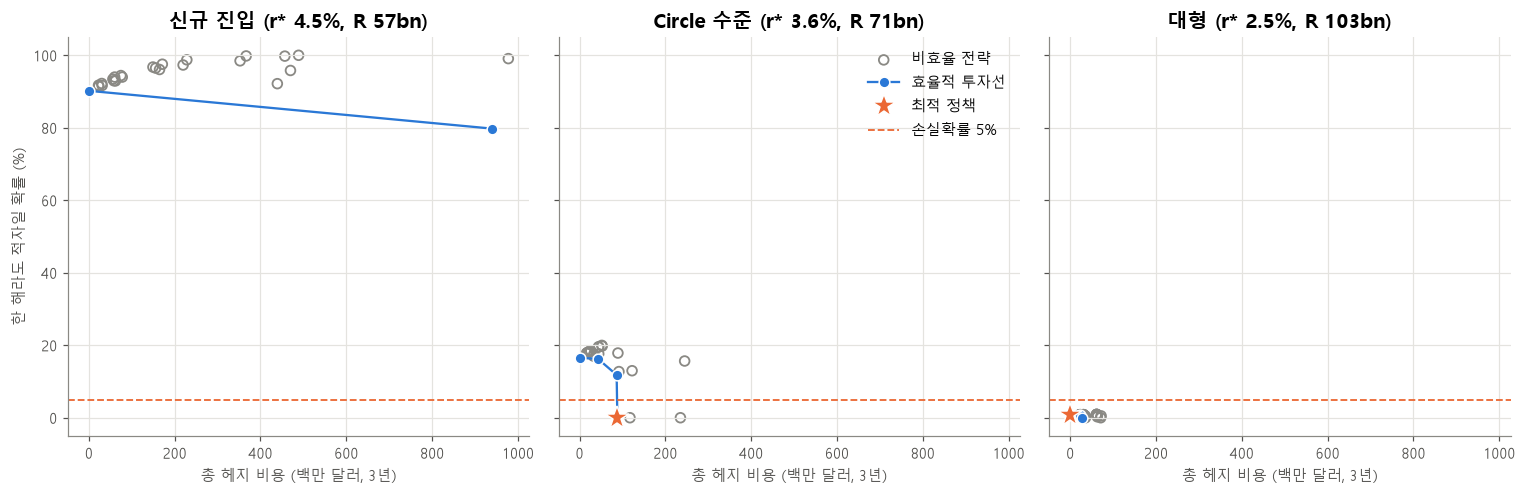

In [13]:
def mark_efficient(df):
    cost, loss = df["총 헤지 비용(백만$)"].to_numpy(), df["손실확률(%)"].to_numpy()
    return np.array([not ((cost <= cost[i]) & (loss <= loss[i]) & ((cost < cost[i]) | (loss < loss[i]))).any()
                     for i in range(len(df))])


def pick_optimal(df):
    ok = df[df["손실확률(%)"] <= 5]
    return ok.sort_values(["총 헤지 비용(백만$)", "손실확률(%)"]).iloc[0] if len(ok) else None

results["효율적"] = False
for size in R0:
    idx = results["규모"] == size
    results.loc[idx, "효율적"] = mark_efficient(results[idx])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, size in zip(axes, R0):
    sub = results[results["규모"] == size]
    eff, ineff = sub[sub["효율적"]].sort_values("총 헤지 비용(백만$)"), sub[~sub["효율적"]]
    ax.scatter(ineff["총 헤지 비용(백만$)"], ineff["손실확률(%)"], s=40, facecolor="none",
               edgecolor=MUTED, linewidth=1.2, label="비효율 전략")
    ax.plot(eff["총 헤지 비용(백만$)"], eff["손실확률(%)"], color=COLORS[0], marker="o",
            markersize=7, markeredgecolor="white", label="효율적 투자선")
    best = pick_optimal(sub)
    if best is not None:
        ax.plot(best["총 헤지 비용(백만$)"], best["손실확률(%)"], marker="*", markersize=16,
                color=COLORS[1], markeredgecolor="white", linestyle="none", label="최적 정책")
    ax.axhline(5, color=COLORS[1], linestyle="--", linewidth=1.2, label="손실확률 5%")
    ax.set_title(f"{size} (r* {TARGET_RSTAR[size]}%, R {R0[size] / 1e9:.0f}bn)")
    ax.set_xlabel("총 헤지 비용 (백만 달러, 3년)")
axes[0].set_ylabel("한 해라도 적자일 확률 (%)")
axes[1].legend(loc="upper right")   # 네 가지 표시가 모두 있는 그래프에 범례
fig.tight_layout()
fig.savefig(FIG_DIR / "6_efficient_frontier.png", dpi=200)
plt.show()

### 규모별 최적 정책
이 셀이 하는 일: 규모마다 무헤지 손실확률과, **손실확률 5% 이하 중 총 헤지 비용이 가장 작은 전략**(최적 정책)을 표로 정리한다. 5% 이하 전략이 없으면 "없음"이라고 쓰고, 참고로 손실확률이 가장 낮은 전략을 함께 보여준다.

In [14]:
def optimal_table(res):
    rows = {}
    for size in R0:
        sub = res[res["규모"] == size]
        unhedged = sub.loc[sub["전략"] == "무헤지", "손실확률(%)"].iloc[0]
        best = pick_optimal(sub)
        lowest = sub.sort_values(["손실확률(%)", "총 헤지 비용(백만$)"]).iloc[0]
        pick = best if best is not None else lowest
        rows[size] = {
            "무헤지 손실확률(%)": unhedged,
            "최적 전략":         best["전략"] if best is not None else f"없음 (최저: {lowest['전략']})",
            "손실확률(%)":       pick["손실확률(%)"],
            "보험료(백만$)":      pick["보험료(백만$)"],
            "거래비용(백만$)":     pick["거래비용(백만$)"],
            "총 비용(백만$)":     pick["총 헤지 비용(백만$)"],
            "총 비용(R 대비 bp/년)": pick["총 헤지 비용(백만$)"] * 1e6 / R0[size] / 3 * 10_000,
        }
    return pd.DataFrame(rows).T

optimal = optimal_table(results)
optimal

,무헤지 손실확률(%),최적 전략,손실확률(%),보험료(백만$),거래비용(백만$),총 비용(백만$),총 비용(R 대비 bp/년)
신규 진입,90.1900,없음 (최저: K r*+0.5 (5.0%) h100 3년),79.7600,905.5887,34.1974,939.7862,54.9624
Circle 수준,16.5300,K r*+0.5 (4.1%) h37.5 3년,0.0000,72.1710,16.0301,88.2010,4.1267
대형,0.7900,무헤지,0.7900,0.0000,0.0000,0.0000,0.0000


### 1년 롤링 vs 3년 만기
이 셀이 하는 일: 같은 K·h에서 두 만기의 손실확률과 비용을 나란히 비교한다.

In [15]:
hedged = results[results["K"].notna()]
tenor_compare = hedged.pivot_table(index=["규모", "K−r*", "h"], columns="만기",
                                   values=["손실확률(%)", "보험료(백만$)", "총 헤지 비용(백만$)"])
tenor_compare = tenor_compare.reindex(columns=["1년 롤링", "3년"], level=1).reindex(list(R0), level=0)
tenor_compare.round(2)

보험료(백만$)          손실확률(%)         총 헤지 비용(백만$)  \
만기                          1년 롤링       3년   1년 롤링      3년        1년 롤링   
규모        K−r*    h                                                       
신규 진입     -1.0000 0.3750  10.4300   9.7300 91.4100 91.7300      23.2600   
                  0.5000  13.9100  12.9800 91.6700 92.2100      31.0100   
                  1.0000  27.8200  25.9600 92.9200 93.9800      62.0200   
          -0.5000 0.3750  45.5500  43.1900 92.9600 93.4100      58.3700   
                  0.5000  60.7300  57.5900 93.9800 94.4000      77.8300   
                  1.0000 121.4700 115.1900 96.4600 96.7500     155.6600   
          0.0000  0.3750 158.4500 151.9100 97.5300 96.0700     171.2700   
                  0.5000 211.2700 202.5500 98.7400 97.3100     228.3700   
                  1.0000 422.5300 405.1000 99.7600 92.1600     456.7300   
          0.5000  0.3750 353.7700 339.6000 99.8100 98.4600     366.5900   
                  0.5000 471.6900 452.7900 99.9900 95.8000     488.7900   
                  1.0000 943.3800 905.5900 99.0700 79.7600     977.5800   
Circle 수준 -1.0000 0.3750   0.7000   0.6300 17.7800 17.8200      16.7300   
                  0.5000   0.9300   0.8500 18.1900 18.2100      22.3000   
                  1.0000   1.8600   1.6900 19.5200 19.5600      44.6100   
          -0.5000 0.3750   3.7800   3.4800 18.0200 18.0300      19.8100   
                  0.5000   5.0500   4.6400 18.3900 18.4500      26.4200   
                  1.0000  10.0900   9.2700 19.7800 19.9600      52.8400   
          0.0000  0.3750  17.5500  16.4300 17.5000 17.0200      33.5800   
                  0.5000  23.4000  21.9000 17.6300 16.2300      44.7700   
                  1.0000  46.8000  43.8100 17.8500 11.8100      89.5500   
          0.5000  0.3750  75.8500  72.1700 12.7300  0.0000      91.8800   
                  0.5000 101.1400  96.2300 12.9700  0.0000     122.5100   
                  1.0000 202.2700 192.4600 15.6500  0.0000     245.0200   
대형        -1.0000 0.3750   0.0100   0.0100  0.8400  0.8400      23.1000   
                  0.5000   0.0200   0.0200  0.8400  0.8400      30.7900   
                  1.0000   0.0300   0.0300  0.9000  0.9000      61.5900   
          -0.5000 0.3750   0.1100   0.0900  0.8400  0.8400      23.1900   
                  0.5000   0.1400   0.1300  0.8500  0.8400      30.9200   
                  1.0000   0.2800   0.2500  0.9200  0.9000      61.8400   
          0.0000  0.3750   0.7000   0.6400  0.8100  0.7200      23.7900   
                  0.5000   0.9400   0.8500  0.7700  0.6100      31.7100   
                  1.0000   1.8700   1.7000  0.6600  0.2600      63.4300   
          0.5000  0.3750   3.9400   3.6100  0.5000  0.0000      27.0200   
                  0.5000   5.2500   4.8100  0.4300  0.0000      36.0300   
                  1.0000  10.5100   9.6200  0.5100  0.0000      72.0600   

                                   
만기                             3년  
규모        K−r*    h                
신규 진입     -1.0000 0.3750  22.5600  
                  0.5000  30.0800  
                  1.0000  60.1500  
          -0.5000 0.3750  56.0200  
                  0.5000  74.6900  
                  1.0000 149.3800  
          0.0000  0.3750 164.7400  
                  0.5000 219.6500  
                  1.0000 439.3000  
          0.5000  0.3750 352.4200  
                  0.5000 469.8900  
                  1.0000 939.7900  
Circle 수준 -1.0000 0.3750  16.6600  
                  0.5000  22.2200  
                  1.0000  44.4400  
          -0.5000 0.3750  19.5100  
                  0.5000  26.0100  
                  1.0000  52.0200  
          0.0000  0.3750  32.4600  
                  0.5000  43.2800  
                  1.0000  86.5500  
          0.5000  0.3750  88.2000  
                  0.5000 117.6000  
                  1.0000 235.2000  
대형        -1.0000 0.3750  23.0900  
                  0.5000  30.7900  
                  1.0000  61.5900  
          -0.5000 0

### 점검: 해마다의 적자확률과 보험료 배분 방식
1년 롤링과 3년 만기의 차이가 어디서 나오는지 보기 위해, Circle 수준에서 몇 가지 전략의 **해별 적자확률**을 본다. 3년 만기 보험료를 고르게 나누지 않고 **1년차에 전부** 비용으로 잡았을 때도 계산한다(배분 가정에 결론이 좌우되는지 확인).

이 셀이 하는 일: Circle 수준에서 무헤지와 세 전략의 1·2·3년차 적자확률, 그리고 한 해라도 적자일 확률을 표로 만든다.

In [16]:
R_circle = R0["Circle 수준"]
base_circle = base_annual(R_circle)
check_rows = {"무헤지": base_circle}
for K, h in [(4.1, round(1 - S, 3)), (4.1, 0.5), (3.6, 1.0)]:
    for tenor in TENORS:
        premium, tcost, payoff = floor_annual(R_circle, K, h, tenor)
        check_rows[f"K {K}% h{h * 100:g} {tenor}"] = base_circle + payoff - premium - tcost
        if tenor == "3년":   # 보험료를 1년차에 전부
            upfront = np.zeros_like(premium)
            upfront[:, 0] = premium.sum(axis=1)
            check_rows[f"K {K}% h{h * 100:g} 3년 (보험료 1년차에 전부)"] = base_circle + payoff - upfront - tcost

pd.DataFrame({name: {"1년차 적자(%)": (a[:, 0] < 0).mean() * 100, "2년차 적자(%)": (a[:, 1] < 0).mean() * 100,
                     "3년차 적자(%)": (a[:, 2] < 0).mean() * 100, "한 해라도 적자(%)": (a < 0).any(axis=1).mean() * 100}
              for name, a in check_rows.items()}).T.round(2)

,1년차 적자(%),2년차 적자(%),3년차 적자(%),한 해라도 적자(%)
무헤지,6.1400,8.7300,11.0600,16.5300
K 4.1% h37.5 1년 롤링,0.0000,6.5300,9.8100,12.7300
K 4.1% h37.5 3년,0.0000,0.0000,0.0000,0.0000
K 4.1% h37.5 3년 (보험료 1년차에 전부),0.0000,0.0000,0.0000,0.0000
K 4.1% h50 1년 롤링,0.0000,6.4000,9.4800,12.9700
K 4.1% h50 3년,0.0000,0.0000,0.0000,0.0000
K 4.1% h50 3년 (보험료 1년차에 전부),0.1300,0.0000,0.0000,0.1300
K 3.6% h100 1년 롤링,3.5400,9.0200,11.2400,17.8500
K 3.6% h100 3년,5.9600,4.0300,3.7500,11.8100
K 3.6% h100 3년 (보험료 1년차에 전부),16.6100,1.9300,1.8600,18.5600


**읽는 법**
- 무헤지는 해가 갈수록 적자확률이 커진다(약 6% → 9% → 11%). 시간이 지날수록 금리가 더 넓게 퍼지기 때문이다.
- **1년 롤링**은 1년차는 막지만 **2·3년차 적자가 남는다.** 금리가 이미 내려간 뒤 다시 사면, 그만큼 보험료가 올라 보호 효과를 상쇄한다. 불이 난 뒤에 화재보험을 새로 드는 것과 같다.
- **3년 만기**는 지금 가격으로 3년 보호를 **고정**한다. 보험료를 1년차에 전부 잡아도 K 4.1%·h 50%는 한 해라도 적자 확률이 약 0.1%로 5% 기준을 통과한다. 결론이 배분 가정에 좌우되지 않는다.

### 비교: 성장률 연 30%(최근 24개월)라면
이 셀이 하는 일: 같은 계산을 최근 24개월 성장률로 한 결과를 한 줄로 요약한다.

In [17]:
opt_g30 = optimal_table(results_g30)
print("g 연 30%: " + " | ".join(
    f"{size} 무헤지 {row['무헤지 손실확률(%)']:.1f}% → 최적 {row['최적 전략']}" for size, row in opt_g30.iterrows()))

g 연 30%: 신규 진입 무헤지 34.8% → 최적 K r*+0.0 (4.5%) h37.5 3년 | Circle 수준 무헤지 0.5% → 최적 무헤지 | 대형 무헤지 0.0% → 최적 무헤지


**읽는 법**
- **신규 진입 (r* 4.5%)**: 무헤지 손실확률이 약 **90%**다. 기준금리 기준 손익분기점(4.65%)이 1년차 선도금리(3.9~4.4%)보다 높아서, 적자가 "드문 위험"이 아니라 **예상되는 결과**다. 플로어는 공정한 가격의 보험이라 평균 손익을 올려 주지 못한다(평균 정산액 ≈ 보험료). 그래서 어떤 전략으로도 5%에 닿지 못한다. 가장 낮은 K 5.0%·h 100%·3년도 약 80%이고, 비용은 R의 연 약 55bp다.
- **Circle 수준 (r* 3.6%)**: 무헤지 약 **16.5%**로 5% 기준을 넘는다. **최적 정책은 K 4.1%(r* + 0.5)·h 50%·3년 만기**로, 손실확률 0%, 비용은 약 1.2억 달러(보험료 약 0.96억 + 거래비용 약 0.21억)다. R 대비 연 약 5.5bp다.
  - **h 50%로 충분한 이유**: 발행사는 준비금 이자의 37.5%(1 − s)만 가진다. 금리가 1%p 내리면 손실은 R × 0.375 × 1%이고, h 50% 플로어의 정산은 R × 0.5 × 1%라 손실보다 크다. h 100%는 **과잉 헤지**라 비용만 두 배다.
  - **K가 r* 이하이면 부족하다**: 기준금리 기준 손익분기점이 r* + 0.15%p(3.75%)라서, K 3.6% 이하 플로어는 금리가 3.6~3.75%일 때의 적자를 막지 못한다(K 3.6%·h 100%·3년도 약 12%).
- **대형 (r* 2.5%)**: 무헤지 약 0.8%로 이미 기준을 통과한다. 최적 정책은 무헤지다.
- **1년 롤링 vs 3년 만기**: 같은 K·h라도 3년 만기가 손실확률을 훨씬 크게 낮춘다(Circle 수준 K 4.1%·h 50%: 롤링 약 13% vs 3년 0%). 보험료도 3년 만기가 약 5~10% 싸다.
- **성장률 연 30%라면**: 신규 진입도 무헤지 약 35% → K 4.5%·h 50%·3년으로 5% 달성이 가능하고, Circle 수준·대형은 무헤지로 충분하다. 성장이 계속된다는 가정이 결론을 크게 바꾼다.

## 9. 결과 요약

| 규모 | R | 무헤지 손실확률 | 최적 정책 | 손실확률 | 비용 (보험료 + 거래비용) |
|---|---|---|---|---|---|
| 신규 진입 (r* 4.5%) | 570억 달러 | 약 90% | **없음** (최저: K 5.0%·h 100%·3년, 약 80%) | — | — |
| Circle 수준 (r* 3.6%) | 712억 달러 | 약 16.5% | **K 4.1%·h 50%·3년** | 0% | 약 1.18억 달러 (0.96 + 0.21), R의 연 5.5bp |
| 대형 (r* 2.5%) | 1,026억 달러 | 약 0.8% | 무헤지 | 0.8% | 0 |

**핵심 메시지 판단**
- **메시지 3 (플로어 최적 운용)**: **드러난다.** Circle 수준에서 무헤지는 5% 기준을 넘고, 효율적 투자선 위에서 "r*보다 약간 높은 K, 발행사 몫(1 − s)에 맞춘 h 50%, 3년 만기"가 R의 연 약 5.5bp로 기준을 맞춘다.
- **메시지 4 (만기 선택, 작은 발행사)**: **부분적으로 드러난다.** 만기 선택은 결정적이다(같은 K·h에서 롤링 13% vs 3년 0%). 작은 발행사일수록 필요한 비용이 커지는 것도 맞다(대형 0 → Circle 연 5.5bp → 신규 진입 연 55bp 이상). 다만 신규 진입은 "비싸다"를 넘어 **플로어로는 해결이 안 된다.** 손익분기점이 선도금리보다 높으면 공정한 가격의 보험은 평균 적자를 메워 주지 못한다. 또 "지금 플로어가 싸다"는 낮은 K에만 해당하고, 실제로 필요한 K(손익분기 근처)는 싸지 않다.

---

# 6단계: 강건성 검증

*원본 파일: `notebooks/06_robustness.ipynb`*

# 06. 강건성 점검

**목적:** 05번의 핵심 결론이 **가정을 바꿔도 유지되는지** 확인한다.
- **강건성(robustness)**: 가정이나 숫자를 조금 바꿔도 결론이 흔들리지 않는 성질. 강건하지 않은 결론은 "그 가정에서만" 맞는 결론이다.

**점검할 핵심 결론 (Circle 수준 발행사, r* 3.6%)**

| | 결론 | 05번 메인 결과 |
|---|---|---|
| ① | 무헤지는 손실확률 5%를 넘는다 | 16.5% |
| ② | 최적 헤지 비율 h는 100%가 아니라 회사 몫(1 − s = 37.5%) 근처다 | h 37.5% |
| ③ | 3년 만기가 1년 롤링보다 손실확률이 낮다 | 0% vs 12.7% (K 4.1%·h 37.5%) |
| ④ | 최적 행사가 K는 손익분기 r* 이상이다 | K 4.1% = r* + 0.5 |

**점검 순서**
1. 시뮬레이션 오차: 신뢰구간, 난수 시드 5번 반복
2. 금리 모형 파라미터(a, σ)의 불확실성
3. 가정 변경 7가지 (Circle 수준만, 하나씩 따로)
4. 결론 ①~④ 유지 여부 ○/× 표
5. 부록: 1차 설정과 바꾼 이유

## 0. 준비
이 셀이 하는 일: 도구를 불러온다. 05번의 계산을 함수로 묶어 둔 `src/issuer_sim.py`를 쓴다(여러 설정을 반복해서 돌리기 위해).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
from src.issuer_sim import (load_market, load_issuer, simulate_rates, evaluate_strategies,
                            pick_optimal, wilson_interval)
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

### 메인 설정 다시 만들기
이 셀이 하는 일: 05번과 같은 입력(곡선, C·s, 세 규모)을 준비하고, 메인 설정으로 다시 계산해 **05번 결과와 똑같이 나오는지** 확인한다.

In [2]:
market = load_market()
C, S = load_issuer()
RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}
R = {size: C / ((1 - S) * rstar / 100) for size, rstar in RSTAR.items()}
A, SIGMA, N_PATHS = 0.093, 0.64, 10_000
CIRCLE = "Circle 수준"

main_paths = simulate_rates(market, A, SIGMA, n_paths=N_PATHS, seed=42)
main_res, main_flags = {}, {}
for size in RSTAR:
    main_res[size], main_flags[size] = evaluate_strategies(main_paths, market, R[size], C, S, RSTAR[size], A, SIGMA)

best = pick_optimal(main_res[CIRCLE])
unhedged = main_res[CIRCLE].set_index("전략").loc["무헤지", "손실확률(%)"]
print(f"Circle 수준 무헤지 {unhedged:.2f}% | 최적 {best['전략']} → 손실확률 {best['손실확률(%)']:.2f}%, "
      f"비용 {best['총 헤지 비용(백만$)']:.1f}백만 달러   (05번: 16.53%, K 4.1% h37.5 3년, 0.00%, 88.2)")

Circle 수준 무헤지 16.53% | 최적 K r*+0.5 (4.10%) h37.5 3년 → 손실확률 0.00%, 비용 88.2백만 달러   (05번: 16.53%, K 4.1% h37.5 3년, 0.00%, 88.2)


## 1. 시뮬레이션 오차

경로 1만 개로 계산한 손실확률도 **표본에서 나온 추정값**이라 오차가 있다. 경로를 다시 뽑으면 조금 다른 값이 나온다.

### 1-1. 95% 신뢰구간
- 손실확률 p는 "1만 번 중 몇 번 적자가 났나"라서, 동전 던지기와 같은 방식으로 오차를 계산할 수 있다(이항분포).
- **Wilson 구간**: 비율의 신뢰구간을 구하는 방법. 0% 근처에서도 음수가 나오지 않아 여기에 맞다.
- **롤링 vs 3년 차이**: 같은 경로에서 계산했으므로, 경로마다 (롤링 적자 여부 − 3년 적자 여부)의 평균과 그 표준오차로 차이의 신뢰구간을 구한다. 0을 포함하지 않으면 차이가 우연이 아니다.

이 셀이 하는 일: 규모별 무헤지, Circle 최적 전략, 같은 K·h의 롤링과 3년 손실확률에 95% 신뢰구간을 붙인다.

In [3]:
def ci_row(flag):
    p = flag.mean()
    lo, hi = wilson_interval(p, len(flag))
    return {"손실확률(%)": p * 100, "95% 하한(%)": lo * 100, "95% 상한(%)": hi * 100}

rows = {f"{size} 무헤지": ci_row(main_flags[size]["무헤지"]) for size in RSTAR}
roll_name = best["전략"].replace("3년", "1년 롤링")
rows[f"Circle 최적: {best['전략']}"] = ci_row(main_flags[CIRCLE][best["전략"]])
rows[f"Circle 같은 K·h: {roll_name}"] = ci_row(main_flags[CIRCLE][roll_name])

diff = main_flags[CIRCLE][roll_name].astype(float) - main_flags[CIRCLE][best["전략"]].astype(float)
d_mean, d_se = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
rows["차이: 롤링 − 3년"] = {"손실확률(%)": d_mean * 100, "95% 하한(%)": (d_mean - 1.96 * d_se) * 100,
                        "95% 상한(%)": (d_mean + 1.96 * d_se) * 100}
pd.DataFrame(rows).T

,손실확률(%),95% 하한(%),95% 상한(%)
신규 진입 무헤지,90.190,89.591,90.758
Circle 수준 무헤지,16.530,15.815,17.271
대형 무헤지,0.790,0.634,0.983
Circle 최적: K r*+0.5 (4.10%) h37.5 3년,0.000,0.000,0.038
Circle 같은 K·h: K r*+0.5 (4.10%) h37.5 1년 롤링,12.730,12.091,13.398
차이: 롤링 − 3년,12.730,12.077,13.383


**읽는 법**
- **Circle 수준 무헤지 16.5%**의 95% 신뢰구간은 약 15.8~17.3%다. 5%보다 한참 위라서, 결론 ①은 시뮬레이션 오차 때문에 바뀔 수 없다.
- **대형 무헤지 0.8%**(0.6~1.0%)도 5%와 거리가 멀다.
- **Circle 최적 전략 0%**: 1만 경로 중 적자가 한 번도 없었다. 신뢰구간 상한도 약 0.04%다.
- **롤링 − 3년 차이**는 약 12.7%p이고, 95% 신뢰구간(12.1~13.4%p)이 0과 멀다. 같은 경로에서 비교했으므로 이 차이는 우연이 아니다(결론 ③).

### 1-2. 난수 시드를 바꿔 5번 반복
- **난수 시드**: 무작위 숫자를 뽑는 출발점. 시드를 바꾸면 완전히 다른 경로 1만 개가 나온다.

이 셀이 하는 일: 시드 1~5로 경로를 새로 뽑아, 규모별 무헤지 손실확률과 최적 전략이 바뀌는지 본다.

In [4]:
seed_rows = []
for seed in range(1, 6):
    paths_seed = simulate_rates(market, A, SIGMA, n_paths=N_PATHS, seed=seed)
    for size in RSTAR:
        res_seed, _ = evaluate_strategies(paths_seed, market, R[size], C, S, RSTAR[size], A, SIGMA)
        opt = pick_optimal(res_seed)
        seed_rows.append({
            "시드": seed, "규모": size,
            "무헤지(%)": res_seed.set_index("전략").loc["무헤지", "손실확률(%)"],
            "최적 전략": opt["전략"] if opt is not None else "없음",
            "최적 손실확률(%)": opt["손실확률(%)"] if opt is not None else np.nan,
        })
seeds = pd.DataFrame(seed_rows)
seeds.pivot(index="시드", columns="규모", values=["무헤지(%)", "최적 전략"]).reindex(columns=list(RSTAR), level=1)

무헤지(%)                 최적 전략                                
규모  신규 진입 Circle 수준    대형 신규 진입                  Circle 수준   대형
시드                                                             
1  90.050    17.690 0.770    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
2  90.230    17.000 0.790    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
3  89.830    17.250 0.670    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
4  89.760    16.620 0.550    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
5  89.960    16.630 0.670    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지

**읽는 법**: 시드를 바꿔도 Circle 수준 무헤지는 약 16.6~17.7%, 최적 전략은 **5번 모두 K 4.1%·h 37.5%·3년**이다. 신규 진입은 5번 모두 "없음", 대형은 5번 모두 무헤지(0.55~0.79%)다. 시뮬레이션 오차로 최적 정책이 바뀌지 않는다.

## 2. 금리 모형 파라미터의 불확실성

03번에서 a(평균회귀 속도)와 σ(변동성)를 **하나의 숫자**로 추정했지만, 이것도 데이터에서 나온 추정값이라 오차가 있다.

- **a**: AR(1) 회귀 r(t+1) = c + φ·r(t) 의 φ로 계산한다(a = −ln φ ÷ (1/12)). φ의 신뢰구간 양 끝을 a로 바꾸면 a의 신뢰구간이 된다. φ가 1에 가까울수록 a는 0에 가깝다.
- **σ**: 잔차의 분산이 카이제곱분포를 따른다고 보고 신뢰구간을 구한다.
- 표준오차는 두 가지로 본다: 보통 OLS, 그리고 02번에서 쓴 **Newey-West(HAC)**(잔차가 서로 이어지거나 크기가 들쭉날쭉해도 맞는 방법).

이 셀이 하는 일: 03번과 같은 월평균 기준금리(2000-01 ~ 2026-09)로 AR(1)을 다시 돌려, φ·a·σ의 추정값, 표준오차, 95% 신뢰구간을 계산한다.

In [5]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")
r_monthly = rates["base_rate"].resample("ME").mean().loc["2000":"2026-09"]
y, x = r_monthly.iloc[1:].to_numpy(), r_monthly.iloc[:-1].to_numpy()
DT = 1 / 12

param_rows = {}
for label, fit_kw in [("보통 OLS", {}), ("Newey-West (시차 6)", {"cov_type": "HAC", "cov_kwds": {"maxlags": 6}})]:
    res = sm.OLS(y, sm.add_constant(x)).fit(**fit_kw)
    phi, se_phi = res.params[1], res.bse[1]
    phi_lo, phi_hi = res.conf_int()[1]
    to_a = lambda p: -np.log(p) / DT
    param_rows[label] = {
        "φ": phi, "φ 표준오차": se_phi, "φ 95% 하한": phi_lo, "φ 95% 상한": phi_hi,
        "a": to_a(phi), "a 표준오차": se_phi / (phi * DT),                  # 델타법: 작은 변화의 비례 관계
        "a 95% 하한": to_a(phi_hi), "a 95% 상한": to_a(phi_lo),
    }
param_table = pd.DataFrame(param_rows).T

ols = sm.OLS(y, sm.add_constant(x)).fit()
phi, n = ols.params[1], len(y)
a_hat = -np.log(phi) / DT
resid_sd = ols.resid.std(ddof=2)
to_sigma = np.sqrt(2 * a_hat / (1 - phi ** 2))
sigma_lo = np.sqrt((n - 2) * resid_sd ** 2 / chi2.ppf(0.975, n - 2)) * to_sigma
sigma_hi = np.sqrt((n - 2) * resid_sd ** 2 / chi2.ppf(0.025, n - 2)) * to_sigma
A_LO, A_HI = param_table.loc["보통 OLS", ["a 95% 하한", "a 95% 상한"]]

print(f"σ = {resid_sd * to_sigma:.3f}, 95% 신뢰구간 {sigma_lo:.3f} ~ {sigma_hi:.3f}  "
      f"(잔차 초과첨도 {pd.Series(ols.resid).kurt():.1f}: 꼬리가 두꺼워 실제 불확실성은 이보다 클 수 있음)")
param_table

σ = 0.638, 95% 신뢰구간 0.592 ~ 0.691  (잔차 초과첨도 7.9: 꼬리가 두꺼워 실제 불확실성은 이보다 클 수 있음)


,φ,φ 표준오차,φ 95% 하한,φ 95% 상한,a,a 표준오차,a 95% 하한,a 95% 상한
보통 OLS,0.992,0.005,0.982,1.002,0.093,0.061,-0.027,0.214
Newey-West (시차 6),0.992,0.009,0.975,1.009,0.093,0.106,-0.113,0.302


**a의 신뢰구간이 0을 포함한다** (보통 OLS 약 −0.03 ~ 0.21, Newey-West는 더 넓다).

**무슨 뜻인가?**
- a = 0이면 금리에 **평균으로 돌아가는 힘이 없다.** 금리가 한번 내려가면 다시 올라올 이유 없이 그 근처를 떠돈다(**랜덤워크**: 술 취한 사람의 걸음처럼 매번 무작위로 움직이고 돌아올 곳이 없는 움직임).
- 26년치 데이터로도 "금리가 평균으로 돌아온다"는 것을 통계적으로 **확신할 수 없다**는 뜻이다. 금리는 아주 느리게 움직여서, 한 번 오르고 내리는 사이클이 5~10년씩 걸린다. 26년이면 그런 사이클을 몇 번밖에 못 본다.
- a의 하한이 **음수**라는 것은 금리가 평균에서 점점 멀어지는(폭발하는) 모형인데, 경제적으로 말이 되지 않는다. 그래서 3번 점검에서 a의 하한은 **0(랜덤워크)**으로 둔다.
- 발행사에게 a = 0은 **나쁜 쪽**이다. 금리가 내려가도 다시 올라온다는 보장이 없어서, 저금리가 오래 이어질 수 있다. 3-(d)에서 이 경우를 직접 확인한다.

**σ의 신뢰구간**(약 0.59 ~ 0.69)은 상대적으로 좁다. 다만 잔차 꼬리가 두꺼워서(급격한 인하 몇 번) 실제 불확실성은 이보다 크다. 그래서 3-(b)에서 σ를 절반(0.32)으로 크게 바꿔 본다.

## 3. 가정 변경 (Circle 수준만, 하나씩 따로)

| 설정 | 바꾼 것 | 나머지 |
|---|---|---|
| 메인 | — | 시장 일치 모형, a 0.093, σ 0.64, 거래비용 2bp, h 37.5·50·100% (전략 25개) |
| (a) 스트레스 세계 C | 금리가 장기 평균 **1.32%**로 끌려가는 Vasicek (현재 SOFR에서 시작). **플로어 가격은 시장 곡선 그대로** | 메인과 같음 |
| (b) σ 0.32 | 시나리오와 가격 모두 σ 0.32 (최근 3년) | |
| (c) 거래비용 0bp / 5bp | 연 거래비용 | |
| (d) a 하한 / 상한 | 시나리오와 가격 모두 a = 0(랜덤워크) / a = 신뢰구간 상한 | |
| (e) h 50·100%만 | 헤지 비율 후보에서 37.5%를 빼고 이전 세트(50·100%)만 → 전략 17개 | |

**결론 판단 기준**
- ①: 무헤지 손실확률 > 5% → ○
- ②: 최적 전략의 h < 100% → ○ (최적이 무헤지면 판단 대상 없음 "—")
- ③: 최적 전략의 K·h에서(최적이 무헤지면 메인 최적 조합 **K r* + 0.5·h 37.5%**에서) 3년 손실확률 < 1년 롤링 손실확률 → ○
- ④: 최적 전략의 K ≥ r* → ○ (최적이 무헤지면 "—")

이 셀이 하는 일: 설정 목록을 정의하고, 각 설정으로 Circle 수준의 25개(또는 17개) 전략을 계산한다.

In [6]:
SETTINGS = {
    "메인":                  dict(),
    "(a) 스트레스 세계 C":      dict(world="vasicek", b=1.32),
    "(b) σ 0.32":           dict(sigma=0.32),
    "(c) 거래비용 0bp":        dict(tc=0.0),
    "(c) 거래비용 5bp":        dict(tc=5.0),
    f"(d) a 하한 → 0":       dict(a=max(A_LO, 0.0)),
    f"(d) a 상한 {A_HI:.3f}": dict(a=A_HI),
    "(e) h 50·100%만":        dict(h=(0.5, 1.0)),                  # 이전 h 세트
}

setting_results = {}
for name, kw in SETTINGS.items():
    a, sigma = kw.get("a", A), kw.get("sigma", SIGMA)
    paths = simulate_rates(market, a, sigma, n_paths=N_PATHS, seed=42, world=kw.get("world", "market"), b=kw.get("b"))
    res, _ = evaluate_strategies(paths, market, R[CIRCLE], C, S, RSTAR[CIRCLE], a, sigma,
                                 tc_bp=kw.get("tc", 2.0), hedge_ratios=kw.get("h"))
    setting_results[name] = res
print("계산한 설정:", list(setting_results))

계산한 설정: ['메인', '(a) 스트레스 세계 C', '(b) σ 0.32', '(c) 거래비용 0bp', '(c) 거래비용 5bp', '(d) a 하한 → 0', '(d) a 상한 0.214', '(e) h 50·100%만']


### 설정별 결과와 결론 ①~④
이 셀이 하는 일: 설정마다 무헤지 손실확률, 최적 전략, 롤링 vs 3년 비교를 정리하고 결론 ①~④를 ○/×/— 로 판정한다.

In [7]:
def judge(res):
    unh = res.set_index("전략").loc["무헤지", "손실확률(%)"]
    opt = pick_optimal(res)
    hedged_opt = opt is not None and opt["전략"] != "무헤지"
    # ③ 비교할 K·h: 헤지가 최적이면 그 조합, 아니면 메인 최적 조합(K r*+0.5, h 1 − s)
    off, h = (opt["K−r*"], opt["h"]) if hedged_opt else (0.5, round(1 - S, 3))
    pair = res[(res["K−r*"] == off) & (res["h"] == h)].set_index("만기")["손실확률(%)"]
    return {
        "무헤지(%)": unh,
        "최적 전략": opt["전략"] if opt is not None else "없음",
        "최적 손실확률(%)": opt["손실확률(%)"] if opt is not None else np.nan,
        "최적 비용(백만$)": opt["총 헤지 비용(백만$)"] if opt is not None else np.nan,
        "비교 K·h": f"K r*{off:+.1f}, h {h * 100:g}%",
        "롤링(%)": pair["1년 롤링"], "3년(%)": pair["3년"],
        "①": "○" if unh > 5 else "×",
        "②": ("○" if opt["h"] < 1.0 else "×") if hedged_opt else "—",
        "③": "○" if pair["3년"] < pair["1년 롤링"] else "×",
        "④": ("○" if opt["K−r*"] >= 0 else "×") if hedged_opt else "—",
    }

verdict = pd.DataFrame({name: judge(res) for name, res in setting_results.items()}).T
verdict

,무헤지(%),최적 전략,최적 손실확률(%),최적 비용(백만$),비교 K·h,롤링(%),3년(%),①,②,③,④
메인,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,88.201,"K r*+0.5, h 37.5%",12.730,0.000,○,○,○,○
(a) 스트레스 세계 C,76.060,K r*+0.5 (4.10%) h37.5 3년,0.000,88.201,"K r*+0.5, h 37.5%",68.180,0.000,○,○,○,○
(b) σ 0.32,1.070,무헤지,1.070,0.000,"K r*+0.5, h 37.5%",0.520,0.000,×,—,○,—
(c) 거래비용 0bp,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,72.171,"K r*+0.5, h 37.5%",12.000,0.000,○,○,○,○
(c) 거래비용 5bp,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,112.246,"K r*+0.5, h 37.5%",13.870,0.000,○,○,○,○
(d) a 하한 → 0,19.150,K r*+0.5 (4.10%) h37.5 3년,0.000,100.300,"K r*+0.5, h 37.5%",15.910,0.000,○,○,○,○
(d) a 상한 0.214,13.640,K r*+0.5 (4.10%) h37.5 3년,0.000,75.812,"K r*+0.5, h 37.5%",8.980,0.000,○,○,○,○
(e) h 50·100%만,16.530,K r*+0.5 (4.10%) h50 3년,0.000,117.601,"K r*+0.5, h 50%",12.970,0.000,○,○,○,○


### 결론 유지 표
이 셀이 하는 일: 결론 ①~④의 ○/× 만 모아 한눈에 보는 표와, 설정마다 네 결론이 모두 유지되는지를 정리한다. 판정 결과는 `data/processed/robustness_verdict.csv`로 저장한다.

In [8]:
marks = verdict[["①", "②", "③", "④"]].copy()
marks["네 결론 모두 유지"] = marks.apply(lambda row: "○" if (row == "○").all() else "×", axis=1)
n_hold, n_all = (marks["네 결론 모두 유지"] == "○").sum(), len(marks)
print(f"네 가지 결론은 {n_all}개 설정 중 {n_hold}개에서 모두 유지된다.")
verdict.to_csv(PROC_DIR / "robustness_verdict.csv")   # 07번(최종 그래프)에서 사용
marks

네 가지 결론은 8개 설정 중 7개에서 모두 유지된다.


,①,②,③,④,네 결론 모두 유지
메인,○,○,○,○,○
(a) 스트레스 세계 C,○,○,○,○,○
(b) σ 0.32,×,—,○,—,×
(c) 거래비용 0bp,○,○,○,○,○
(c) 거래비용 5bp,○,○,○,○,○
(d) a 하한 → 0,○,○,○,○,○
(d) a 상한 0.214,○,○,○,○,○
(e) h 50·100%만,○,○,○,○,○


### 그림: 설정별 무헤지 vs 최적 전략 손실확률
이 셀이 하는 일: 설정마다 무헤지(회색)와 최적 전략(파랑) 손실확률을 막대로 그리고, 5% 기준선을 긋는다.

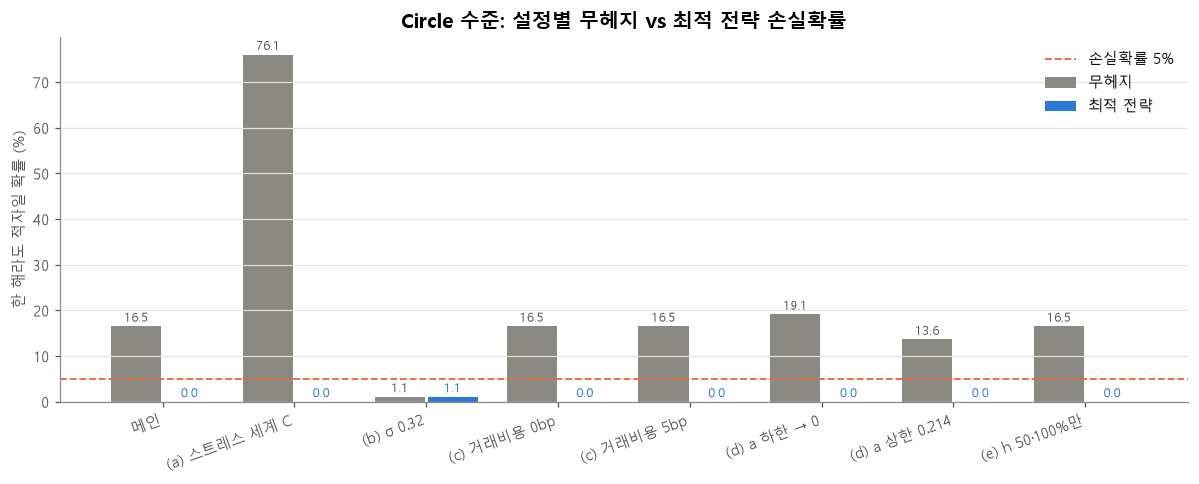

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
xpos = np.arange(len(verdict))
ax.bar(xpos - 0.2, verdict["무헤지(%)"].astype(float), width=0.38, color=MUTED, label="무헤지")
ax.bar(xpos + 0.2, verdict["최적 손실확률(%)"].astype(float), width=0.38, color=COLORS[0], label="최적 전략")
ax.axhline(5, color=COLORS[1], linestyle="--", linewidth=1.2, label="손실확률 5%")
for xi, v in zip(xpos, verdict["무헤지(%)"].astype(float)):
    ax.text(xi - 0.2, v + 1, f"{v:.1f}", ha="center", fontsize=8, color=TEXT_SUB)
for xi, v in zip(xpos, verdict["최적 손실확률(%)"].astype(float)):   # 0%여도 보이게 숫자 표시
    ax.text(xi + 0.2, v + 1, f"{v:.1f}", ha="center", fontsize=8, color=COLORS[0])
ax.set_xticks(xpos)
ax.set_xticklabels(verdict.index, rotation=20, ha="right")
ax.grid(axis="x", visible=False)
ax.set_title("Circle 수준: 설정별 무헤지 vs 최적 전략 손실확률")
ax.set_ylabel("한 해라도 적자일 확률 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "7_robustness.png", dpi=200)
plt.show()

### 뒤집히는 설정: (b) σ 0.32
- 금리의 흔들림을 절반(최근 3년 수준)으로 줄이면, 3년 동안 금리가 Circle의 손익분기점(기준금리 3.75%) 아래로 내려가는 경로가 거의 없어진다. 지금 선도금리가 4.0~4.8%로 손익분기점보다 높기 때문이다.
- 그래서 **무헤지 손실확률이 1.1%**로 5% 아래가 되고(① ×), 헤지할 이유가 없어 ②·④는 판단할 대상이 없다(—).
- ③(3년 만기가 롤링보다 나음)은 여기서도 유지된다(0% vs 0.5%).
- **의미**: 결론 ①("Circle 수준도 헤지가 필요하다")은 **금리 변동성이 장기 평균(0.64) 수준**이라는 가정에 기대고 있다. 최근 3년처럼 조용한 시기가 계속된다면 헤지가 필요 없다. 반대로 **"헤지를 한다면 어떻게"에 대한 결론(②·③·④)은 이 설정에서도 틀리지 않는다.**

### 결론이 유지되지만 눈여겨볼 설정
- **(a) 스트레스 세계 C**: 금리가 1.32%로 끌려가면 무헤지 손실확률이 **76%**로 뛴다. 그래도 최적 전략과 비용은 메인과 같다. 플로어는 **시장 가격**(선도금리 기준)으로 사므로, 시장이 예상하지 못한 하락을 3년 만기가 그대로 막아 준다. 반면 롤링은 68%로 거의 효과가 없다. 금리가 내려간 뒤 다시 사면 이미 비싸졌기 때문이다.
- **(d) a = 0 (랜덤워크)**: 무헤지 19.2%로 조금 나빠지고, 같은 플로어의 가격(등가 σ)이 올라 비용이 약 1.00억 달러로 늘지만 결론은 같다.
- **(e) h 50·100%만 (이전 세트)**: 37.5%가 없으면 최적 전략이 h 50%가 되고 비용이 약 1.18억 달러로 **약 33% 늘어난다**(0.88억 → 1.18억). 손실확률은 둘 다 0%다. 회사 몫(1 − s)만큼만 사는 것이 같은 보호를 가장 싸게 얻는 방법이라는 결론 ②를 직접 확인해 준다.

## 4. 요약

**네 가지 결론은 8개 설정 중 7개에서 모두 유지된다.** 뒤집히는 것은 σ를 절반(0.32)으로 줄인 설정 하나이고, 그때도 결론 ①(헤지가 필요하다)만 바뀌며 ③은 유지된다.

| 점검 | 결과 |
|---|---|
| 시뮬레이션 오차 | 무헤지 16.5% (15.8~17.3%), 롤링 − 3년 차이 12.7%p (12.1~13.4%p). 시드 5개 모두 같은 최적 전략(K 4.1%·h 37.5%·3년) |
| 파라미터 불확실성 | a의 95% 신뢰구간이 0을 포함(−0.03~0.21): 평균회귀를 통계적으로 확신할 수 없다. a = 0으로 바꿔도 결론 유지 |
| 가정 변경 7개 | σ 0.32에서만 ① 뒤집힘. 세계 C, 거래비용 0·5bp, a 하한·상한, h 이전 세트(50·100%)에서 ①~④ 모두 유지 |

- 가장 강한 결론은 **③ 3년 만기 > 1년 롤링**이다. 8개 설정 모두에서 유지되고, 금리가 크게 내려가는 세계 C에서 차이가 가장 크다(0% vs 68%).
- 가장 약한 결론은 **① 무헤지는 5%를 넘는다**이다. 금리 변동성 가정에 따라 달라진다.

## 부록: 분석 설정의 변경 이력 (발제안 부록용)

### 1차 설정과 결과

| 항목 | 1차 설정 |
|---|---|
| 발행량 성장률 | 최근 24개월 평균 (월 0.0219, 연 약 30%) — 3년간 R이 2.2배 |
| 규모 | 손익분기 금리 r* 기준 소형 3.9% / 중형 2.5% / 대형 1.5% (R 658 / 1,026 / 1,710억 달러) |
| 행사가 | 모든 규모에 고정 2.0, 2.5, 3.0, 3.5% |
| 평가 지표 | 3년 누적 손익(할인 없이 합산) < 0 인 경로 비율 |
| 준비금 수익률 | max(r, 0) (기준금리와 같다고 봄) |
| 공통 | 시장 일치 금리 모형(a 0.093, σ 0.64), 국채 곡선 −18bp 보정 + PCHIP, 바슐리에 + 등가 σ, 거래비용 연 2bp, h 50·100%, 1년 롤링·3년 |

**1차 결과**
- 세 규모 모두 무헤지 손실확률이 0.03% 이하 → 17개 전략 모두 5% 기준 통과 → **최적 정책 = 모든 규모에서 무헤지**.
- 헤지 비용의 대부분이 거래비용이었고, 효율적 투자선이 사실상 무헤지 한 점으로 줄어 비교가 성립하지 않았다.
- 진단: 성장률을 0으로 두면 소형의 무헤지 손실확률이 0.03% → 11.8%로 뛰었다. 그래도 가장 좋은 전략(K 3.5%·h 100%·3년)이 10.6%로 5%에 닿지 못했다. 행사가가 소형의 r*보다 낮았기 때문이다.

### 무엇을 왜 바꿨나

| 항목 | 1차 | 최종 | 바꾼 이유 |
|---|---|---|---|
| 성장률 | 연 30% | **0** (연 30%는 비교용) | 손실확률은 성장이 멈춘 경우에도 버티는지를 봐야 한다. 최근 24개월은 금리 인하기와 GENIUS법이 겹친 특수 시기였다. 1차에서는 성장 가정이 금리 위험을 가렸다(소형 0.03% vs g = 0이면 11.8%) |
| 규모 정의 | r* 3.9 / 2.5 / 1.5% | **신규 진입 4.5 / Circle 수준 3.6 / 대형 2.5%** | 실제 Circle의 r*(3.6%)를 기준점으로 삼고, 선도금리보다 손익분기점이 높은 신규 진입 발행사를 넣어 규모 효과를 보이기 위해 |
| 행사가 | 고정 2.0~3.5% | **규모별 r* − 1, − 0.5, r*, r* + 0.5%** | 고정 행사가가 손익분기점보다 낮으면, 손익분기 근처의 금리 하락을 막을 수 없다. 행사가는 각 발행사의 손익분기점을 기준으로 정해야 비교가 공정하다 |
| 평가 지표 | 3년 누적 적자 | **한 해라도 연간 적자** (누적은 참고) | 누적 손익은 초반 이익이 뒤의 손실을 덮어 위험을 작게 보이게 한다(Circle 수준: 누적 7.2% vs 한 해라도 16.5%). 실제 회사는 한 해의 적자도 신용·규제상 부담이 된다 |
| 준비금 수익률 | max(r, 0) | **max(r, 0) − 0.15%p** | Circle 공시로 계산한 실제 준비금 수익률이 9개 분기 모두 기준금리보다 0.1~0.2%p 낮았다 |
| 헤지 비율 후보 | 50, 100% | **1 − s(37.5%), 50, 100%** (전략 25개) | 강건성 점검에서 발행사 몫(1 − s)만큼의 명목이 같은 보호(손실확률 0%)를 약 25% 싸게 주는 것을 확인했다. 발행사는 준비금 이자의 37.5%만 가지므로 그만큼만 헤지하면 된다 |

### 참고: 05번 이전 단계에서 바꾼 것
- **금리 시나리오**: 과거 데이터로 추정한 Vasicek(장기 평균 b = FOMC 3.2%, 스트레스 1.32%) → **시장 일치 모형**(경로 평균 = 선도금리). 시나리오와 플로어 가격의 기준을 일치시키기 위해서다. Vasicek 세계는 부록(세계 B·C)으로 남겼다.
- **수익률곡선**: 국채 곡선 그대로 → **1개월 국채 − SOFR 차이(18bp)를 빼는 보정 + PCHIP 보간**. 국채가 SOFR보다 높아 플로어가 싸게 나오는 문제와, 직선 보간 때문에 2년 지점에서 선도금리가 꺾이는 문제를 고쳤다.
- **플로어 가격의 σ**: 0.64 고정 → **등가 σ**(평균회귀 반영). 시뮬레이션과 가격이 같은 금리 퍼짐을 쓰게 하기 위해서다. σ 0.64 고정 가격(31~80% 더 비쌈)은 부록으로 남겼다.
- **발행량과 금리의 관계**: 회귀 추정값 b1 = −0.039(p = 0.08)는 신뢰구간이 0을 포함한다. 그래서 가장 보수적인 **b1 = 0**(금리가 내려도 발행량이 늘지 않음)을 메인으로 썼다.

---

# 7단계: 발제안용 최종 그래프

*원본 파일: `notebooks/07_final_figures.ipynb`*

# 07. 발제안용 최종 그래프

발제안에 넣을 그림 5장을 `output/figures/final/`에 만든다.

**공통 규칙**
- 한국어 제목·축, 흰 배경, 300dpi
- 같은 색 체계: **무헤지 = 회색, 3년 만기 = 진한 파랑, 1년 롤링 = 주황, 기준선 = 빨간 점선**
- 제목은 "무엇을 보여주는지"가 아니라 **결론을 문장으로**

| 파일 | 내용 | 메시지 |
|---|---|---|
| `1_natural_hedge.png` | 금리 하락 시 b1 시나리오별 이자수익 변화 | 2 |
| `2_rate_paths.png` | 시장 선도금리와 시뮬레이션 경로 범위 | 방법 |
| `3_frontier_by_size.png` | 규모별 효율적 투자선 | 3·4 |
| `4_roll_vs_3y.png` | 1년 롤링 vs 3년 만기 (메인, 세계 C) | 3 |
| `5_robustness.png` | 설정 × 결론 ①~④ ○/× 표 | 강건성 |

## 준비
이 셀이 하는 일: 도구를 불러오고, 저장 폴더와 공통 색·글꼴 설정을 정한다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FINAL_DIR = PROJECT / "output" / "figures" / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, TEXT_SUB
from src.issuer_sim import load_market, load_issuer, simulate_rates, evaluate_strategies, pick_optimal
setup_plot_style()
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

GREY, BLUE, ORANGE, RED = "#8a8984", "#1c5cab", "#eb6834", "#d03b3b"   # 무헤지, 3년, 1년 롤링, 기준선
DPI = 300


def save(fig, name):
    fig.savefig(FINAL_DIR / name, dpi=DPI, bbox_inches="tight")
    plt.show()
    print("저장:", FINAL_DIR / name)

## 메인 설정 계산
이 셀이 하는 일: 05번과 같은 메인 설정(시장 일치 모형, g = 0, 전략 25개)으로 세 규모를 계산하고, Circle 수준은 세계 C(금리가 1.32%로 끌려가는 스트레스)로도 계산한다. 그림 2~4에 쓴다.

In [2]:
market = load_market()
C, S = load_issuer()
RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}
R = {size: C / ((1 - S) * rstar / 100) for size, rstar in RSTAR.items()}
A, SIGMA = 0.093, 0.64

paths = simulate_rates(market, A, SIGMA, n_paths=10_000, seed=42)
results = {size: evaluate_strategies(paths, market, R[size], C, S, RSTAR[size], A, SIGMA)[0] for size in RSTAR}

paths_c = simulate_rates(market, A, SIGMA, n_paths=10_000, seed=42, world="vasicek", b=1.32)
annual_main = evaluate_strategies(paths, market, R["Circle 수준"], C, S, 3.6, A, SIGMA, return_annual=True)[1]
annual_c = evaluate_strategies(paths_c, market, R["Circle 수준"], C, S, 3.6, A, SIGMA, return_annual=True)[1]

best_circle = pick_optimal(results["Circle 수준"])
print("Circle 수준 최적:", best_circle["전략"], f"| 비용 {best_circle['총 헤지 비용(백만$)'] / 100:.2f}억 달러")

Circle 수준 최적: K r*+0.5 (4.10%) h37.5 3년 | 비용 0.88억 달러


## 그림 1. 자연 헤지는 작다 (메시지 2)
이 셀이 하는 일: 02번 10번 섹션과 같은 계산(3년간 2년물 −2%p, 준비금 수익률 4% → 2%가 매달 같은 폭으로 내려감)으로, b1 시나리오별 3년 총 이자수익 변화를 막대로 그린다.
- b1 값은 02번 회귀 결과: 0(보수, 메인), −0.039(추정값), −0.083(95% 하한)

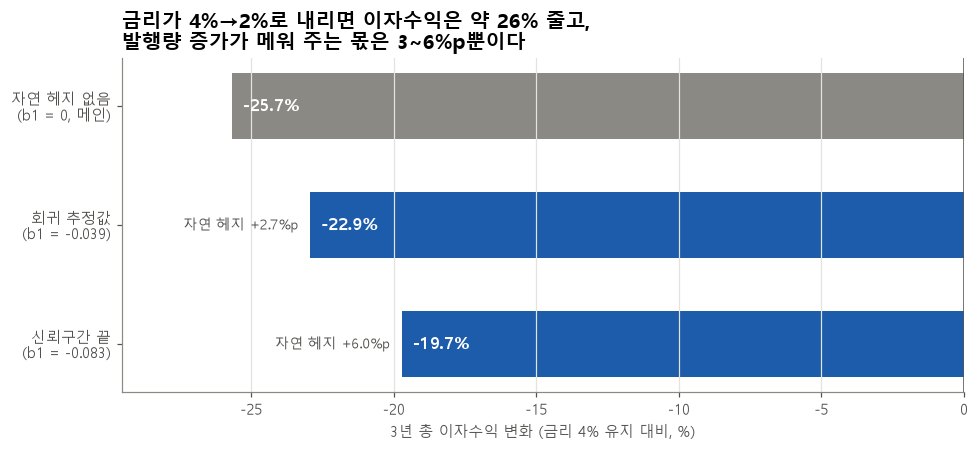

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\1_natural_hedge.png


In [3]:
B1 = {"자연 헤지 없음\n(b1 = 0, 메인)": 0.0, "회귀 추정값\n(b1 = -0.039)": -0.0394, "신뢰구간 끝\n(b1 = -0.083)": -0.0831}
months = 36
dgs2_path = np.linspace(0, -2.0, months + 1)[1:]
rate_path = np.linspace(4.0, 2.0, months + 1)[1:]
base_total = 100 * 0.04 * 3

changes = {}
for name, b in B1.items():
    R_path = 100 * np.exp(b * dgs2_path)
    changes[name] = (np.sum(R_path * rate_path / 100 / 12) / base_total - 1) * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(changes)
values = np.array(list(changes.values()))
bars = ax.barh(names, values, color=[GREY, BLUE, BLUE], height=0.55)
for bar, v in zip(bars, values):
    ax.text(v + 0.4, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", ha="left", color="white",
            fontsize=11, fontweight="bold")                       # 막대 안쪽 왼쪽 끝에 값
for i, v in enumerate(values[1:], start=1):
    ax.text(v - 0.4, i, f"자연 헤지 +{v - values[0]:.1f}%p", va="center", ha="right", color=TEXT_SUB, fontsize=9)   # 막대 바깥 왼쪽
ax.axvline(0, color=TEXT_SUB, linewidth=1)
ax.invert_yaxis()
ax.set_xlim(values.min() * 1.15, 0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("3년 총 이자수익 변화 (금리 4% 유지 대비, %)")
ax.set_title("금리가 4%→2%로 내리면 이자수익은 약 26% 줄고,\n발행량 증가가 메워 주는 몫은 3~6%p뿐이다", loc="left")
fig.tight_layout()
save(fig, "1_natural_hedge.png")

## 그림 2. 금리 시나리오 (방법 설명용)
이 셀이 하는 일: 시장 선도금리(진한 선)와 시뮬레이션 경로 1만 개의 퍼짐(바깥 = 5~95%, 안쪽 = 25~75%)을 팬 차트로 그린다.
- **팬 차트**: 시간이 갈수록 넓어지는 부채꼴 모양의 범위 그래프. 미래가 멀수록 불확실성이 커진다는 것을 보여준다.

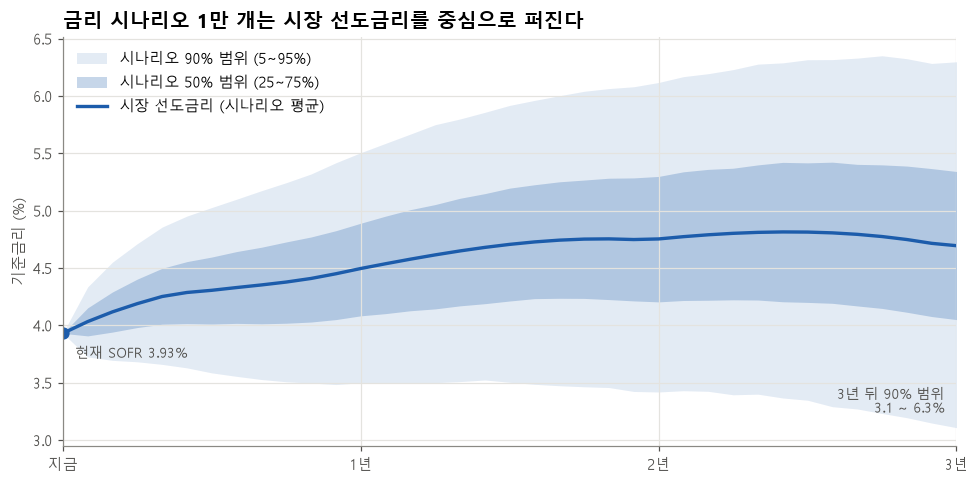

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\2_rate_paths.png


In [4]:
t = np.arange(paths.shape[1])
p5, p25, p75, p95 = np.percentile(paths, [5, 25, 75, 95], axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(t, p5, p95, color=BLUE, alpha=0.12, linewidth=0, label="시나리오 90% 범위 (5~95%)")
ax.fill_between(t, p25, p75, color=BLUE, alpha=0.25, linewidth=0, label="시나리오 50% 범위 (25~75%)")
ax.plot(t, market["fwd"], color=BLUE, linewidth=2.2, label="시장 선도금리 (시나리오 평균)")
ax.plot(0, market["sofr"], "o", color=BLUE, markersize=7)
ax.annotate(f"현재 SOFR {market['sofr']:.2f}%", (0, market["sofr"]), xytext=(8, -16), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)
ax.annotate(f"3년 뒤 90% 범위\n{p5[-1]:.1f} ~ {p95[-1]:.1f}%", (36, p5[-1]), xytext=(-8, 8), textcoords="offset points",
            ha="right", va="bottom", color=TEXT_SUB, fontsize=9)
ax.set_xlim(0, 36)
ax.set_xticks([0, 12, 24, 36])
ax.set_xticklabels(["지금", "1년", "2년", "3년"])
ax.set_ylabel("기준금리 (%)")
ax.set_title("금리 시나리오 1만 개는 시장 선도금리를 중심으로 퍼진다", loc="left")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "2_rate_paths.png")

## 그림 3. 규모별 효율적 투자선 (메시지 3·4)
이 셀이 하는 일: 세 규모의 25개 전략을 같은 축 범위로 나란히 그린다. 점 색은 만기(회색 = 무헤지, 파랑 = 3년, 주황 = 1년 롤링), 선은 효율적 투자선, ★는 최적 정책, 빨간 점선은 손실확률 5% 기준이다. 비용은 억 달러 단위.

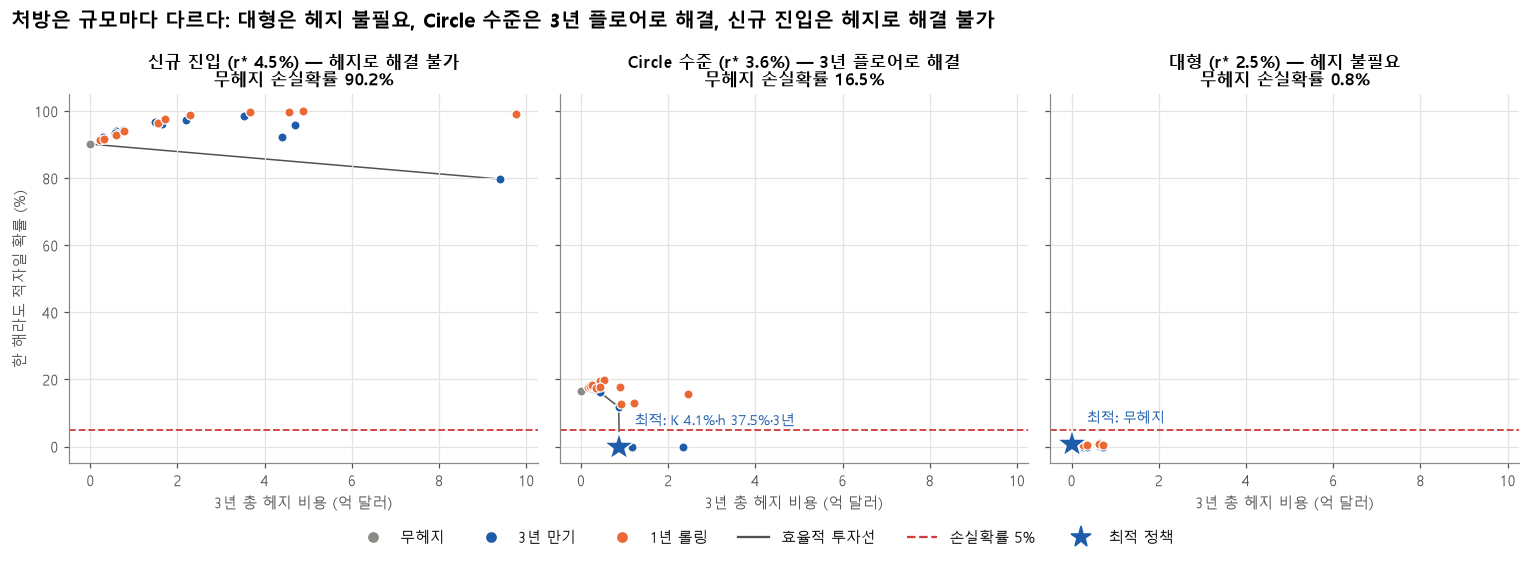

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\3_frontier_by_size.png


In [5]:
def efficient_mask(df):
    cost, loss = df["총 헤지 비용(백만$)"].to_numpy(), df["손실확률(%)"].to_numpy()
    return np.array([not ((cost <= cost[i]) & (loss <= loss[i]) & ((cost < cost[i]) | (loss < loss[i]))).any()
                     for i in range(len(df))])

TENOR_COLOR = {None: GREY, "3년": BLUE, "1년 롤링": ORANGE}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
verdict_text = {"신규 진입": "헤지로 해결 불가", "Circle 수준": "3년 플로어로 해결", "대형": "헤지 불필요"}
for ax, size in zip(axes, RSTAR):
    res = results[size].copy()
    res["비용(억$)"] = res["총 헤지 비용(백만$)"] / 100
    eff = res[efficient_mask(res)].sort_values("비용(억$)")
    ax.plot(eff["비용(억$)"], eff["손실확률(%)"], color=TEXT_SUB, linewidth=1, zorder=1)
    for tenor, color in TENOR_COLOR.items():
        sub = res[res["만기"].isna()] if tenor is None else res[res["만기"] == tenor]
        ax.scatter(sub["비용(억$)"], sub["손실확률(%)"], s=36, color=color, edgecolor="white", linewidth=0.8, zorder=2)
    best = pick_optimal(res)
    if best is not None:
        ax.plot(best["총 헤지 비용(백만$)"] / 100, best["손실확률(%)"], marker="*", markersize=20, color=BLUE,
                markeredgecolor="white", zorder=3)
        label = "최적: 무헤지" if best["전략"] == "무헤지" else f"최적: K {best['K']:.1f}%·h {best['h'] * 100:g}%·3년"
        ax.annotate(label, (best["총 헤지 비용(백만$)"] / 100, best["손실확률(%)"]), xytext=(10, 14),
                    textcoords="offset points", fontsize=9, color=BLUE)
    ax.axhline(5, color=RED, linestyle="--", linewidth=1.2)
    unh = res.loc[res["전략"] == "무헤지", "손실확률(%)"].iloc[0]
    ax.set_title(f"{size} (r* {RSTAR[size]}%) — {verdict_text[size]}\n무헤지 손실확률 {unh:.1f}%", fontsize=11)
    ax.set_xlabel("3년 총 헤지 비용 (억 달러)")
axes[0].set_ylabel("한 해라도 적자일 확률 (%)")
handles = [Line2D([], [], marker="o", linestyle="none", color=c, label=l)
           for c, l in [(GREY, "무헤지"), (BLUE, "3년 만기"), (ORANGE, "1년 롤링")]]
handles += [Line2D([], [], color=TEXT_SUB, label="효율적 투자선"), Line2D([], [], color=RED, linestyle="--", label="손실확률 5%"),
            Line2D([], [], marker="*", linestyle="none", markersize=14, color=BLUE, label="최적 정책")]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("처방은 규모마다 다르다: 대형은 헤지 불필요, Circle 수준은 3년 플로어로 해결, 신규 진입은 헤지로 해결 불가",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "3_frontier_by_size.png")

## 그림 4. 1년 롤링 vs 3년 만기 (메시지 3)
이 셀이 하는 일: Circle 수준의 최적 조합(K·h)으로 무헤지·1년 롤링·3년 만기의 **해별 적자확률**과 **한 해라도 적자일 확률**을, 메인 세계와 세계 C(금리가 1.32%로 끌려가는 스트레스)로 나란히 그린다.

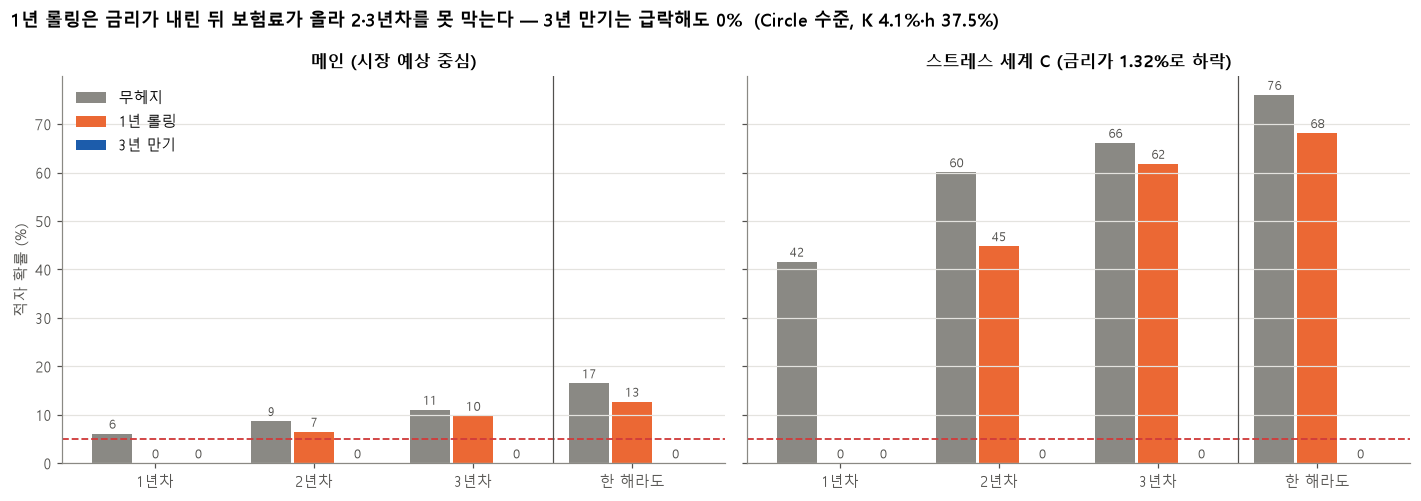

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\4_roll_vs_3y.png


In [6]:
pair = best_circle["전략"]
roll = pair.replace("3년", "1년 롤링")
SERIES = [("무헤지", "무헤지", GREY), ("1년 롤링", roll, ORANGE), ("3년 만기", pair, BLUE)]
GROUPS = ["1년차", "2년차", "3년차", "한 해라도"]


def year_probs(annual):
    return [(annual[:, y] < 0).mean() * 100 for y in range(3)] + [(annual < 0).any(axis=1).mean() * 100]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (title, ann) in zip(axes, [("메인 (시장 예상 중심)", annual_main), ("스트레스 세계 C (금리가 1.32%로 하락)", annual_c)]):
    x = np.arange(len(GROUPS))
    for i, (label, key, color) in enumerate(SERIES):
        vals = year_probs(ann[key])
        bars = ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=color, label=label)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.0f}", ha="center", fontsize=8, color=TEXT_SUB)
    ax.axhline(5, color=RED, linestyle="--", linewidth=1.2)
    ax.axvline(2.5, color=TEXT_SUB, linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("적자 확률 (%)")
axes[0].legend(loc="upper left")
k_txt, h_txt = best_circle["K"], best_circle["h"] * 100
fig.suptitle(f"1년 롤링은 금리가 내린 뒤 보험료가 올라 2·3년차를 못 막는다 — 3년 만기는 급락해도 0%  "
             f"(Circle 수준, K {k_txt:.1f}%·h {h_txt:g}%)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "4_roll_vs_3y.png")

## 그림 5. 강건성 (○/× 표)
이 셀이 하는 일: 06번에서 저장한 설정별 판정(`robustness_verdict.csv`)을 표 그림으로 만든다. ○ = 결론 유지, × = 뒤집힘, — = 판단 대상 없음(헤지가 필요 없는 경우).

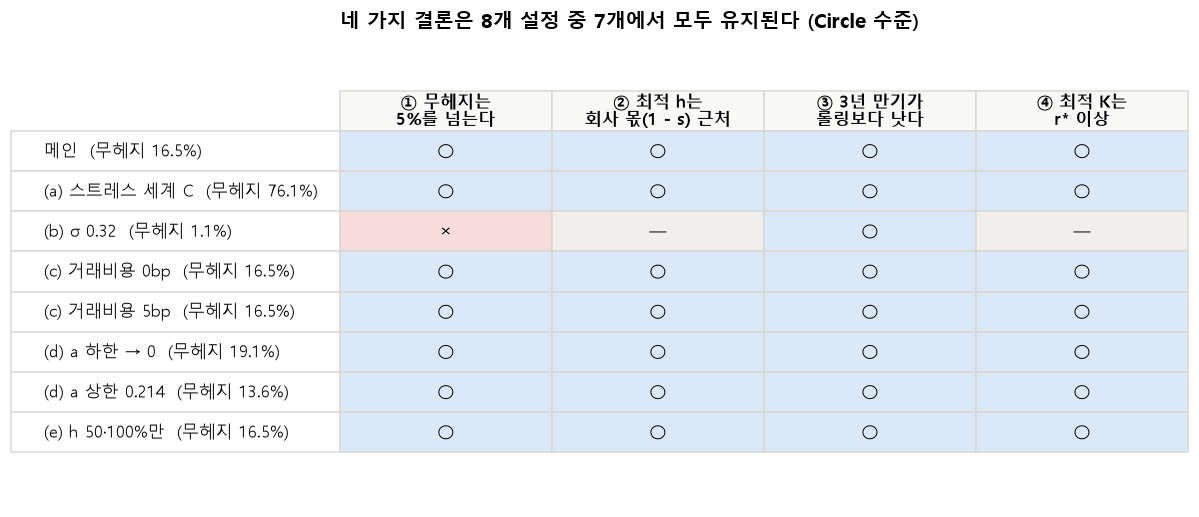

저장: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\output\figures\final\5_robustness.png


In [7]:
verdict = pd.read_csv(PROC_DIR / "robustness_verdict.csv", index_col=0)
cols = ["①", "②", "③", "④"]
col_names = ["① 무헤지는\n5%를 넘는다", "② 최적 h는\n회사 몫(1 - s) 근처", "③ 3년 만기가\n롤링보다 낫다", "④ 최적 K는\nr* 이상"]
held = sum((verdict.loc[i, cols] == "○").all() for i in verdict.index)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axis("off")
cell_text = verdict[cols].values.tolist()
row_labels = [f"{i}  (무헤지 {verdict.loc[i, '무헤지(%)']:.1f}%)" for i in verdict.index]
table = ax.table(cellText=cell_text, rowLabels=row_labels, colLabels=col_names, cellLoc="center", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.9)
MARK_COLOR = {"○": "#dbe8f8", "×": "#f8dcdc", "—": "#f0efec"}
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#d9d8d4")
    if row == 0:
        cell.set_text_props(fontweight="bold")
        cell.set_facecolor("#f9f9f7")
    elif col >= 0:
        cell.set_facecolor(MARK_COLOR.get(cell.get_text().get_text(), "white"))
ax.set_title(f"네 가지 결론은 {len(verdict)}개 설정 중 {held}개에서 모두 유지된다 (Circle 수준)",
             loc="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "5_robustness.png")